# 03 · Tabular Data with pandas: Series, DataFrames & Indexing
*AI Foundations · Notebook 03 of 19*

Almost every dataset you will meet in machine learning starts life as a **table**: one row per example (a patient, a house, a bike trip) and one column per measured property (age, price, duration). Before any model can be trained, that table has to be loaded, inspected, sliced, cleaned, reshaped and combined with other tables. **pandas** is the Python library for exactly this job, and it is the standard tool in data science, in Kaggle notebooks and in olympiad data tasks.

This notebook builds a precise mental model of pandas: *a table is a set of columns, each a typed array, all sharing one row index, and every cell can be addressed either by **label** or by **position***. With that model, every behavior becomes predictable: which selector returns a single number, a `Series` or a `DataFrame`, why adding two `Series` can produce `NaN`, why an integer column suddenly turns into floats, and why some assignments silently do nothing. Everything runs on a small but realistic bike-share dataset that you will create, save to Excel and CSV, and analyze from end to end.

**What you will learn**
- The table mental model: index + columns + typed arrays, **labels versus positions**
- `Series` in depth: construction, `index` / `values` / `name` / `dtype`, `.loc` vs `.iloc`, vectorized math, **index alignment**, boolean masks, `value_counts`, the `.str` and `.dt` accessors, categorical and nullable dtypes
- `DataFrame` in depth: five ways to build one, inspecting it, reading and writing CSV and Excel, and the round-trip pitfalls
- Meaningful row labels with `set_index` / `reset_index`, and why unique labels matter
- Selection with `[]`, `.loc`, `.iloc`, `.at`, `.iat`, with a complete table of return types (scalar / `Series` / `DataFrame`)
- Boolean filtering (`&`, `|`, `~`, `isin`, `between`, `query`) and `reindex`
- Modifying data safely: `.loc` assignment, `assign`, `drop`, **Copy-on-Write** versus the old `SettingWithCopyWarning`, `inplace` pitfalls, dtype conversions
- Missing data: `NaN` vs `None` vs `pd.NA`, detecting, dropping and filling, and how aggregations treat gaps
- Sorting and ranking, `groupby` (split–apply–combine, named aggregation, `transform`, `filter`), `pivot_table`, `crosstab`, `melt`
- Combining tables with `merge` (inner/left/right/outer, `validate`, `indicator`, the row-multiplication trap) and `concat`
- Performance: vectorization vs `apply` vs Python loops, memory usage and the `category` dtype

**Prerequisites:** Python basics (lists, dictionaries, functions, loops) and a first contact with NumPy arrays (dtypes, vectorized arithmetic, boolean masks).      **Estimated time:** ~5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. The mental model: what a table really is
2. `Series`: a labeled one-dimensional array
3. `DataFrame`: many columns sharing one index
4. Reading and writing files: CSV and Excel
5. Meaningful row labels: `set_index` and `reset_index`
6. Selecting data: `[]`, `.loc`, `.iloc`, `.at`, `.iat`
7. Modifying data safely (and Copy-on-Write)
8. Missing data
9. Sorting and ranking
10. `groupby`: split–apply–combine
11. Reshaping: `pivot_table`, `crosstab`, `melt`, `pivot`
12. Combining tables: `merge` and `concat`
13. Performance: vectorization and memory
14. Case study: one week of Riverton bike-share
15. Quiz
16. Summary, cheat sheet and going further

## 0. Setup

The cell below imports the libraries, fixes the random seed, sets one plotting style for the whole notebook and defines three small helpers:

* `run_check(name, test_fn)` runs the automatic checker of an exercise and prints ✅ / ❌ / ⏳ instead of crashing,
* `kind_of(obj)` describes what an expression returned (`scalar`, `Series (n,)` or `DataFrame (rows, cols)`), which we will use constantly when studying selection,
* `attempt("code")` runs an expression or a statement and reports its result, **or** the exception it raises, **plus** the names of any warnings it emits. It lets us run "forbidden" code on purpose and look at what happens without stopping the notebook.

> **Version note.** pandas 3.0 (released in early 2026) changed a few defaults: text columns get a dedicated `str` dtype instead of `object`, and *Copy-on-Write* became the only mode. This notebook was executed with the pandas version printed below, and every cell is written to run unchanged on both pandas 2.x and 3.x. Wherever the two versions print something different, the text tells you what to expect in each.

In [1]:
# Setup: imports, reproducibility, plotting style, versions, helpers
import contextlib
import io
import random
import sys
import time
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

PANDAS_MAJOR = int(pd.__version__.split(".")[0])
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} "
      f"| matplotlib {matplotlib.__version__}")
print("pandas 3 defaults active (str dtype, Copy-on-Write only):", PANDAS_MAJOR >= 3)


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet: fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def kind_of(obj) -> str:
    """Describe a pandas result: 'DataFrame (r, c)', 'Series (n,)' or 'scalar (<type>)'."""
    if isinstance(obj, pd.DataFrame):
        return f"DataFrame {obj.shape}"
    if isinstance(obj, pd.Series):
        return f"Series {obj.shape}"
    return f"scalar ({type(obj).__name__})"


def attempt(code: str, width: int = 100) -> None:
    """Run `code` (an expression or a statement) in the notebook's namespace and print the
    outcome on one line: the value (or its kind for Series/DataFrame), 'done' for a statement,
    or the exception raised, plus the names of any warnings emitted."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            try:
                compiled, is_expression = compile(code, "<attempt>", "eval"), True
            except SyntaxError:                     # an assignment or another statement
                compiled, is_expression = compile(code, "<attempt>", "exec"), False
            value = eval(compiled, globals())
            if not is_expression:
                outcome = "-> done"
            elif isinstance(value, (pd.Series, pd.DataFrame)):
                outcome = "-> " + kind_of(value)
            else:
                outcome = "-> " + repr(value)
        except Exception as exc:  # we *want* to see errors here, not crash
            message = str(exc).strip().splitlines()[0] if str(exc).strip() else ""
            outcome = f"raises {type(exc).__name__}: {message}"
    names = sorted({w.category.__name__ for w in caught})
    if names:
        outcome += "   [warning: " + ", ".join(names) + "]"
    print(f"{code:<34} {outcome}"[:width + 34])

Python 3.13.15 | NumPy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2
pandas 3 defaults active (str dtype, Copy-on-Write only): False


## 1. The mental model: what a table really is

### 1.1 From a spreadsheet to a table of typed columns

Riverton is a (fictional) riverside city with a public bike-share: six docking stations, classic and electric bikes, riders with annual, monthly or day passes. Every time someone unlocks a bike, the system writes one line into a trip log. Opened in a spreadsheet program, the first rows of one week's log look like this:

| trip_id | start_time | rider_id | start_station | end_station | bike_type | duration_min | distance_km | fare | rating |
|---|---|---|---|---|---|---|---|---|---|
| T101 | 2026-05-04 07:42 | R01 | STN | UNI | electric | 9.9 | 2.6 | 0.99 | 5 |
| T102 | 2026-05-04 07:55 | R05 | GAR | HAR | classic | 19.9 | 4.4 | 0.00 | 5 |
| T103 | 2026-05-04 08:05 | R03 | MKT | LIB | classic | 5.2 | 0.9 | 0.00 | |
| T104 | 2026-05-04 08:20 | R08 | HAR | STN | electric | 13.2 | 3.2 | 1.32 | 3 |
| T105 | 2026-05-04 12:35 | R11 | UNI | LIB | classic | 9.8 | 2.0 | 0.00 | 4 |

* Each **row** records one *observation* (here: one trip). In machine learning a row is one *example* or *sample*.
* Each **column** records one *attribute* of every observation (a *feature* or *variable*): who rode, from where, for how long.
* Every cell is identified by two coordinates: *which trip* and *which attribute*. The cell at row `T104`, column `end_station` holds `STN`.
* Notice the empty `rating` cell of trip `T103`: the rider simply did not rate the trip. Real tables always have holes, and a good tool must represent "no value here" explicitly.

pandas represents such a table as a **`DataFrame`**, and each of its columns as a **`Series`**. The single most useful sentence to remember is:

> **Key idea.** A `DataFrame` is a collection of columns. Each column is a one-dimensional **typed array** (all floats, or all timestamps, or all strings, ...), and all columns share one **index**: the sequence of row labels. A "row" is not stored anywhere as an object. It is assembled on demand by taking the *i*-th element of every column.

The picture below shows the anatomy on four rows and four columns of the log.

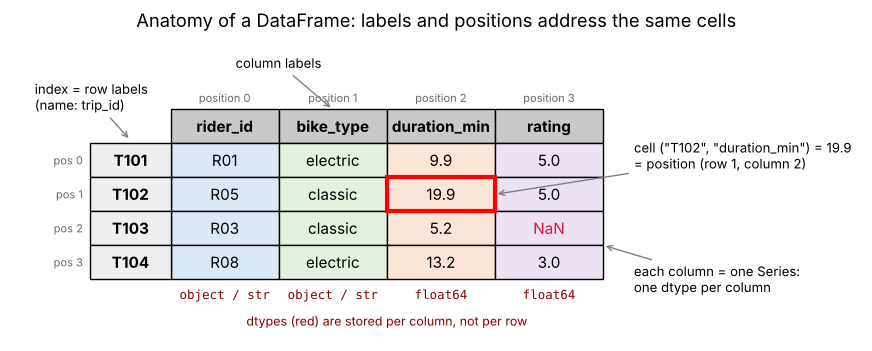

In [2]:
from matplotlib.patches import Rectangle


def draw_dataframe_anatomy():
    """Draw a labeled sketch of a small DataFrame: index, column labels, dtypes, positions."""
    rows = ["T101", "T102", "T103", "T104"]
    cols = ["rider_id", "bike_type", "duration_min", "rating"]
    cells = [["R01", "electric", "9.9", "5.0"], ["R05", "classic", "19.9", "5.0"],
             ["R03", "classic", "5.2", "NaN"], ["R08", "electric", "13.2", "3.0"]]
    dtypes = ["object / str", "object / str", "float64", "float64"]
    fills = ["#dbe9f6", "#e3f1df", "#fbe5d6", "#ece2f4"]
    W, H, X0 = 1.75, 0.55, 1.3          # cell width, cell height, width of the index column
    n = len(rows)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    for j, (c, dt, fc) in enumerate(zip(cols, dtypes, fills)):
        x = X0 + j * W
        ax.add_patch(Rectangle((x, n * H), W, H, fc="#c9c9c9", ec="black"))
        ax.text(x + W / 2, n * H + H / 2, c, ha="center", va="center", weight="bold")
        ax.text(x + W / 2, (n + 1) * H + 0.12, f"position {j}", ha="center", fontsize=8, color="dimgray")
        ax.text(x + W / 2, -0.32, dt, ha="center", fontsize=9, family="monospace", color="darkred")
        for i in range(n):
            y = (n - 1 - i) * H
            ax.add_patch(Rectangle((x, y), W, H, fc=fc, ec="black"))
            ax.text(x + W / 2, y + H / 2, cells[i][j], ha="center", va="center",
                    color="crimson" if cells[i][j] == "NaN" else "black")
    for i, r in enumerate(rows):
        y = (n - 1 - i) * H
        ax.add_patch(Rectangle((0, y), X0, H, fc="#efefef", ec="black"))
        ax.text(X0 / 2, y + H / 2, r, ha="center", va="center", weight="bold")
        ax.text(-0.12, y + H / 2, f"pos {i}", ha="right", va="center", fontsize=8, color="dimgray")
    # highlight one cell: row label T102, column label duration_min
    hx, hy = X0 + 2 * W, (n - 2) * H
    ax.add_patch(Rectangle((hx, hy), W, H, fill=False, ec="red", lw=3))
    right = X0 + len(cols) * W
    notes = [
        ((X0 / 2, n * H + 0.05), (-0.9, n * H + 0.75), "index = row labels\n(name: trip_id)"),
        ((X0 + 1.5 * W, (n + 1) * H), (X0 + 0.6 * W, (n + 1) * H + 0.75), "column labels"),
        ((hx + W, hy + H / 2), (right + 0.5, hy + 0.9), 'cell ("T102", "duration_min") = 19.9\n'
                                                         "= position (row 1, column 2)"),
        ((right, H), (right + 0.5, 0.0), "each column = one Series:\none dtype per column"),
    ]
    for xy, xytext, text in notes:
        ax.annotate(text, xy=xy, xytext=xytext, fontsize=9.5, va="center",
                    arrowprops=dict(arrowstyle="->", color="gray"))
    ax.text(X0 + 2 * W, -0.75, "dtypes (red) are stored per column, not per row", ha="center",
            fontsize=9, color="darkred")
    ax.set_xlim(-1.3, right + 4.2)
    ax.set_ylim(-1.0, (n + 1) * H + 1.2)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Anatomy of a DataFrame: labels and positions address the same cells")
    plt.show()


draw_dataframe_anatomy()

Read the figure in two ways:

* **By label.** Row labels (`T101`, `T102`, ...) live in the *index*, and column labels (`rider_id`, ...) live in `columns`. The highlighted cell is `("T102", "duration_min")`.
* **By position.** The same cell is at row position 1 and column position 2, counting from 0 as Python always does.

Every pandas operation is either **label-based** (`.loc`, arithmetic between objects, `merge`, `groupby` keys) or **position-based** (`.iloc`). Almost every pandas surprise comes from mixing the two systems without noticing. We will keep asking "label or position?" throughout the notebook.

### 1.2 Why not just a list of lists, a dict, or a NumPy array?

| Container | Row labels | Column names | One type per column | Missing values | Fast column math |
|---|---|---|---|---|---|
| list of lists (rows) | no (positions only) | no | no (each row mixes types) | no convention | no (Python loops) |
| dict of lists (columns) | no | yes | not enforced | no convention | no |
| NumPy 2-D array | no | no | **one dtype for the whole array** | only `NaN` in float arrays | yes |
| pandas `DataFrame` | **yes** (the index) | **yes** | **yes** | `NaN` / `NaT` / `pd.NA` | **yes** (NumPy underneath) |

A NumPy array would force a single dtype on the whole table, so text and numbers could only coexist as slow Python objects. pandas keeps NumPy's speed *column by column* and adds the bookkeeping that real data needs: names, labels, per-column types and missing-value markers.

### 1.3 The connection to machine learning

In ML notation, a dataset with $m$ examples and $d$ features is a **design matrix** $X \in \mathbb{R}^{m \times d}$ plus a **target vector** $\mathbf{y} \in \mathbb{R}^{m}$. Row $i$ of $X$ is the feature vector $\mathbf{x}^{(i)} \in \mathbb{R}^{d}$ of example $i$. A `DataFrame` is $X$ (and often $\mathbf{y}$) *before* it is ready for a model: it still carries names, labels, text columns and holes. Data preparation is the work of turning the DataFrame into a clean numeric matrix, which you then hand to NumPy or scikit-learn with `.to_numpy()`.

<details>
<summary><b>Quick check</b>: in the five-row table above, take <code>trip_id</code> as the index. What are the label coordinates and the position coordinates of the cell that holds trip T104's fare?</summary>

Labels: row `"T104"`, column `"fare"`. Positions: once `trip_id` becomes the index it is no longer a data column, so the data columns are `start_time` (0), `rider_id` (1), `start_station` (2), `end_station` (3), `bike_type` (4), `duration_min` (5), `distance_km` (6), `fare` (7), `rating` (8). T104 is the fourth row, so the position coordinates are (3, 7).
</details>

## 2. `Series`: a labeled one-dimensional array

A `Series` is the building block of everything else: one column of a table. We start with it, exactly as you would focus on a single column of a spreadsheet, and then put several of them side by side in Section 3.

### 2.1 From a Python list to a labeled `Series`

Here are the end stations of the first five trips, stored as an ordinary Python list.

In [3]:
end_list = ["UNI", "HAR", "LIB", "STN", "LIB"]
print(end_list)
print("length:", len(end_list))
print("item at position 1:", end_list[1])

['UNI', 'HAR', 'LIB', 'STN', 'LIB']
length: 5
item at position 1: HAR


Suppose you need trip T102's end station. With the list, you have to know that T102 was the second trip exported and ask for `end_list[1]`. That link between a position and a trip is written down nowhere in the data: if the next export is sorted differently (say, by start station), the very same line quietly returns some other trip's station, and no error warns you. A `Series` makes the link explicit. Every value carries a **label**, here its trip id, and you look values up by label instead of by position. The constructor is `pd.Series(data, index=..., name=...)`.

In [4]:
trip_ids = ["T101", "T102", "T103", "T104", "T105"]
end = pd.Series(end_list, index=trip_ids, name="end_station")
end

T101    UNI
T102    HAR
T103    LIB
T104    STN
T105    LIB
Name: end_station, dtype: object

The printout has three parts: the **labels** on the left, the **values** on the right, and a footer with the Series' **name** and **dtype** (data type). Text is stored with dtype `object` in pandas 2 (an array of pointers to Python strings) and with the dedicated `str` dtype in pandas 3. Schematically:

```
             index (labels)    values
             --------------    ------
 position 0      T101           UNI
 position 1      T102           HAR
 position 2      T103           LIB
 position 3      T104           STN
 position 4      T105           LIB
             name = "end_station"     dtype = object (pandas 2) / str (pandas 3)
```

> **Key idea.** A `Series` = an array of values + an `Index` of labels of the same length + a `name` + a `dtype`. Labels are *in addition to* positions, never instead of them: every element still has a position 0, 1, 2, ...

### 2.2 Four ways to construct a `Series`

In [5]:
# (a) from a dict: keys become labels, insertion order is kept
docks = pd.Series({"HAR": 20, "MKT": 15, "LIB": 12, "STN": 24, "UNI": 18, "GAR": 10}, name="docks")
# (b) from a NumPy array, reusing the labels of another Series
elevation = pd.Series(np.array([4, 17, 29, 38, 71, 93]), index=docks.index, name="elevation_m")
# (c) from a scalar: the value is broadcast to every label
in_repair = pd.Series(0, index=docks.index, name="bikes_in_repair")
# (d) from a list without an index: labels default to 0, 1, ..., n-1 (a RangeIndex)
distances = pd.Series([2.6, 4.4, 0.9, 3.2, 2.0], name="distance_km")

for s in [docks, elevation, in_repair, distances]:
    print(f"{s.name:>16}: dtype={str(s.dtype):<8} labels={list(s.index)}")

           docks: dtype=int64    labels=['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR']
     elevation_m: dtype=int64    labels=['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR']
 bikes_in_repair: dtype=int64    labels=['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR']
     distance_km: dtype=float64  labels=[0, 1, 2, 3, 4]


When you pass a dict **and** an explicit `index`, pandas looks each requested label up in the dict. Labels that are absent get a missing value, `NaN` ("not a number"). Watch the dtype as well:

In [6]:
pd.Series({"HAR": 20, "MKT": 15, "LIB": 12}, index=["MKT", "HAR", "PIER"], name="docks")

MKT     15.0
HAR     20.0
PIER     NaN
Name: docks, dtype: float64

Three things happened: the result follows the order of the requested labels, `LIB` was dropped because it was not requested, and `PIER`, which has no entry, became `NaN`. Because `NaN` is a floating-point value, the integers 15 and 20 were converted to floats (15.0, 20.0). This is *label alignment*, the most important idea of this section, and we come back to it in 2.6.

### 2.3 Anatomy: `index`, `values`, `name`, `dtype`

In [7]:
print("name  :", end.name)
print("index :", end.index)
print("values:", end.values)
print("dtype :", end.dtype)
print("shape :", end.shape, "| size:", end.size, "| len:", len(end))

name  : end_station
index : Index(['T101', 'T102', 'T103', 'T104', 'T105'], dtype='object')
values: ['UNI' 'HAR' 'LIB' 'STN' 'LIB']
dtype : object
shape : (5,) | size: 5 | len: 5


* `end.index` is an `Index` object holding the labels. It is immutable: you can replace it as a whole, but not change one label in place.
* `end.values` gives the underlying data.
* `dtype` (singular) belongs to a Series. A DataFrame has `dtypes` (plural), one per column.
* `shape` is a 1-tuple `(5,)`, because a Series is one-dimensional.

**`.values` versus `.to_numpy()` versus `.array`.** For plain numeric data all three look alike, but they differ for pandas' own *extension* dtypes (nullable integers, categoricals, and the pandas 3 `str` dtype):

In [8]:
examples = {
    "float64": pd.Series([2.6, 4.4]),
    "Int64 (nullable)": pd.Series([5, None], dtype="Int64"),
    "category": pd.Series(["HAR", "MKT"], dtype="category"),
    "datetime64": pd.Series(pd.to_datetime(["2026-05-04", "2026-05-05"])),
}
rows = []
for label, s in examples.items():
    rows.append({"Series dtype": label,
                 "type(s.values)": type(s.values).__name__,
                 "type(s.to_numpy())": type(s.to_numpy()).__name__,
                 "s.to_numpy().dtype": str(s.to_numpy().dtype)})
pd.DataFrame(rows)

,Series dtype,type(s.values),type(s.to_numpy()),s.to_numpy().dtype
0,float64,ndarray,ndarray,float64
1,Int64 (nullable),IntegerArray,ndarray,float64
2,category,Categorical,ndarray,object
3,datetime64,ndarray,ndarray,datetime64[ns]


| Accessor | Returns | Use it when |
|---|---|---|
| `.to_numpy()` | **always** a NumPy `ndarray` (copying if necessary) | you need NumPy / scikit-learn input |
| `.array` | the pandas array that actually stores the data | rarely, in library code |
| `.values` | a NumPy array *or* a pandas extension array, depending on the dtype | legacy code, prefer `.to_numpy()` |

Notice that the nullable `Int64` column, which contains a missing entry, comes out of `.to_numpy()` as a **`float64`** array with `NaN` in the gap: NumPy integer arrays have no slot for "missing", so pandas picks the closest NumPy type that has one (pandas versions before 2.2 returned an `object` array instead, and without missing entries you get `int64`). To be explicit and version-proof, state the conversion yourself: `s.to_numpy(dtype="float64", na_value=np.nan)`.

### 2.4 Labels versus positions: `.loc`, `.iloc`, and the ambiguous `s[0]`

Every element has two addresses. **`.loc[...]`** takes *labels*, and **`.iloc[...]`** takes integer *positions*.

In [9]:
print("by label   :", end.loc["T102"])
print("by position:", end.iloc[1])
print("\nlabel slice  end.loc['T102':'T104']  (includes T104):")
print(end.loc["T102":"T104"])
print("\nposition slice  end.iloc[1:3]  (excludes position 3):")
print(end.iloc[1:3])

by label   : HAR
by position: HAR

label slice  end.loc['T102':'T104']  (includes T104):
T102    HAR
T103    LIB
T104    STN
Name: end_station, dtype: object

position slice  end.iloc[1:3]  (excludes position 3):
T102    HAR
T103    LIB
Name: end_station, dtype: object


> **Common pitfall.** Label slices **include** both endpoints, and position slices **exclude** the stop, as everywhere in Python. The reason: positions are integers, and half-open ranges $[\text{start}, \text{stop})$ make `len = stop - start` and let `s.iloc[:k]` and `s.iloc[k:]` split a Series cleanly. Labels have no arithmetic (what is "the label just after T104"?), so the only sensible convention is "up to and including the label you named".

The plain bracket `s[...]` tries to guess which system you mean, and the guess depends on the *type of the index*. Consider counts of trips per hour, labeled by the hour (integer labels), sorted by count:

In [10]:
by_hour = pd.Series([9, 6, 5, 3], index=[8, 17, 7, 12], name="trips")
print(by_hour, "\n")
print("by_hour.loc[8]  =", by_hour.loc[8], "  (the label 8)")
print("by_hour.iloc[0] =", by_hour.iloc[0], "  (position 0, which happens to carry label 8)")
attempt("by_hour[8]")
attempt("by_hour[0]")
attempt("by_hour[0:2]")
attempt("end[0]")

8     9
17    6
7     5
12    3
Name: trips, dtype: int64 

by_hour.loc[8]  = 9   (the label 8)
by_hour.iloc[0] = 9   (position 0, which happens to carry label 8)
by_hour[8]                         -> np.int64(9)
by_hour[0]                         raises KeyError: 0
by_hour[0:2]                       -> Series (2,)
end[0]                             -> 'UNI'   [warning: FutureWarning]


Look closely at the four `[]` lines:

* With an **integer index**, `by_hour[8]` and `by_hour[0]` are treated as **labels**: label 8 exists, label 0 does not, hence the `KeyError`.
* Yet `by_hour[0:2]` is treated as **positions** (the first two rows). Single integers and integer slices follow different rules!
* With a **string index**, `end[0]` has no label 0 to find. pandas 2 falls back to position 0 and emits a `FutureWarning`. pandas 3 removed the fallback and raises `KeyError`. Code that relied on the fallback breaks when you upgrade.

> **Key idea.** Write `.loc[...]` when you mean labels and `.iloc[...]` when you mean positions. Use plain `[]` on a Series only when the meaning cannot be misread (we will see in Section 6 that on a *DataFrame*, `[]` has its own, well-defined job: selecting columns).

### 2.5 Vectorized arithmetic

Arithmetic between Series, or between a Series and a number, is applied element by element in compiled NumPy code, with no Python loop. Let us compute the average speed of each trip, in km/h:

$$
\text{speed} = \frac{\text{distance (km)}}{\text{duration (h)}} = \frac{\text{distance\_km}}{\text{duration\_min}/60}.
$$

By hand for trip T101: $2.6 / (9.9/60) = 2.6 \times 60 / 9.9 = 156 / 9.9 \approx 15.76$ km/h.

In [11]:
duration = pd.Series([9.9, 19.9, 5.2, 13.2, 9.8], index=trip_ids, name="duration_min")
distance = pd.Series([2.6, 4.4, 0.9, 3.2, 2.0], index=trip_ids, name="distance_km")

speed = (distance / (duration / 60)).round(2).rename("speed_kmh")
print(speed, "\n")
print("in seconds       :", (duration * 60).tolist())
print("total minutes    :", round(duration.sum(), 1), "| mean:", round(duration.mean(), 2))
print("longest trip     : label", duration.idxmax(), "at position", duration.argmax())

T101    15.76
T102    13.27
T103    10.38
T104    14.55
T105    12.24
Name: speed_kmh, dtype: float64

 

in seconds       : [594.0, 1194.0, 312.0, 792.0, 588.0]
total minutes    : 58.0 | mean: 11.6
longest trip     : label T102 at position 1


Labels travel through the computation: the result is still indexed by trip id. Note the pair `idxmax()` (the **label** of the maximum, `T102`) and `argmax()` (its **position**, 1): the same label/position duality again.

### 2.6 Index alignment: arithmetic matches labels, not positions

Two counting apps report the number of departures per station: one for the morning, one for the afternoon. They do not cover the same stations, and they list them in different orders.

In [12]:
morning = pd.Series({"HAR": 3, "MKT": 5, "LIB": 2, "STN": 4}, name="morning")
afternoon = pd.Series({"STN": 6, "UNI": 4, "MKT": 1, "GAR": 2}, name="afternoon")
total = morning + afternoon
total

GAR     NaN
HAR     NaN
LIB     NaN
MKT     6.0
STN    10.0
UNI     NaN
dtype: float64

Before adding, pandas **aligns** the two Series on their labels. Step by step:

1. Form the **union** of the two indexes: {GAR, HAR, LIB, MKT, STN, UNI}. When the indexes differ, the union comes out sorted.
2. Look each label up in both Series. A label absent from one side gets `NaN` on that side.
3. Add element by element. Anything plus `NaN` is `NaN`.

| label | morning | afternoon | morning + afternoon |
|---|---|---|---|
| GAR | (absent → NaN) | 2 | NaN |
| HAR | 3 | (absent → NaN) | NaN |
| LIB | 2 | (absent → NaN) | NaN |
| MKT | 5 | 1 | **6** |
| STN | 4 | 6 | **10** |
| UNI | (absent → NaN) | 4 | NaN |

Only MKT and STN appear in both inputs, so only they get a number, and the dtype becomes `float64` because `NaN` is a float. Compare with what NumPy does with the same raw numbers: it pairs values **by position**, blindly.

In [13]:
print("NumPy, by position:", morning.to_numpy() + afternoon.to_numpy(),
      " <- pairs HAR with STN, MKT with UNI, ...: meaningless")
print("\npandas with fill_value=0 (absent label counts as 0):")
print(morning.add(afternoon, fill_value=0).astype(int))

NumPy, by position: [9 9 3 6]  <- pairs HAR with STN, MKT with UNI, ...: meaningless

pandas with fill_value=0 (absent label counts as 0):
GAR     2
HAR     3
LIB     2
MKT     6
STN    10
UNI     4
dtype: int64


`morning.add(afternoon, fill_value=0)` treats a label that is missing on **one** side as 0 *before* adding. That is right for counts (a station that is not in the morning report really had no morning departures), but it would be wrong for, say, temperatures. Decide what absence *means* before you fill it. The same methods exist for every operator: `.sub`, `.mul`, `.div`, `.pow`.

The diagram shows the matching that happened in `morning + afternoon`.

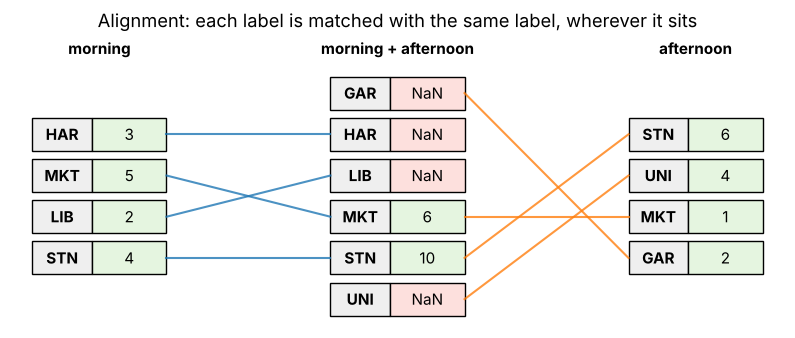

In [14]:
def draw_alignment(left, right, result):
    """Sketch label matching: inputs on the outside, the aligned result in the middle."""
    fig, ax = plt.subplots(figsize=(10, 3.8))
    n = len(result)
    columns = [(left, 0.0, "morning"), (result, 4.0, "morning + afternoon"), (right, 8.0, "afternoon")]
    pos = {}
    for series, x, title in columns:
        top = n - 1 - (n - len(series)) / 2          # center shorter columns vertically
        ax.text(x + 0.9, n + 0.35, title, ha="center", weight="bold")
        for k, (label, value) in enumerate(series.items()):
            y = top - k
            missing = pd.isna(value)
            ax.add_patch(Rectangle((x, y), 0.8, 0.8, fc="#efefef", ec="black"))
            ax.add_patch(Rectangle((x + 0.8, y), 1.0, 0.8, fc="#fde0dd" if missing else "#e5f5e0", ec="black"))
            ax.text(x + 0.4, y + 0.4, label, ha="center", va="center", weight="bold")
            ax.text(x + 1.3, y + 0.4, "NaN" if missing else f"{value:g}", ha="center", va="center")
            pos[(title, label)] = (x, y)
    for label in left.index:                          # morning (right edge) -> result (left edge)
        (x0, y0), (x1, y1) = pos[("morning", label)], pos[("morning + afternoon", label)]
        ax.plot([x0 + 1.8, x1], [y0 + 0.4, y1 + 0.4], color="tab:blue", alpha=0.8)
    for label in right.index:                         # afternoon (left edge) -> result (right edge)
        (x0, y0), (x1, y1) = pos[("afternoon", label)], pos[("morning + afternoon", label)]
        ax.plot([x0, x1 + 1.8], [y0 + 0.4, y1 + 0.4], color="tab:orange", alpha=0.8)
    ax.set_xlim(-0.3, 10.1)
    ax.set_ylim(-0.3, n + 0.8)
    ax.axis("off")
    ax.set_title("Alignment: each label is matched with the same label, wherever it sits")
    plt.show()


draw_alignment(morning, afternoon, total)

Green result cells received a value from *both* sides, and red ones had a partner missing and became `NaN`.

> **Going deeper.** Alignment is pandas' answer to the question "which value goes with which?". It is why you can add two columns from two different tables without first sorting them, and it is the same matching logic that `merge` (Section 12) uses on columns. One subtle consequence: if a label is **duplicated**, alignment pairs *every* copy on the left with *every* copy on the right. For instance `pd.Series([1, 2], index=["x", "x"]) + pd.Series([10, 20, 30], index=["x", "x", "y"])` has **four** rows labeled `x` (2 × 2 pairs), plus `y` with `NaN`. Keep labels unique unless you have a reason not to.

### 2.7 Boolean masks

A comparison produces a **boolean Series** with the same labels. Using it inside `[]` (or `.loc[]`) keeps only the `True` positions:

In [15]:
is_long = duration > 12
print(is_long, "\n")
print(duration[is_long], "\n")
print("number of long trips:", is_long.sum(), "| share of long trips:", is_long.mean())

T101    False
T102     True
T103    False
T104     True
T105    False
Name: duration_min, dtype: bool 

T102    19.9
T104    13.2
Name: duration_min, dtype: float64 

number of long trips: 2 | share of long trips: 0.4


Because `True` counts as 1 and `False` as 0, `mask.sum()` counts the matches and `mask.mean()` gives their *fraction*: 2 of 5 trips, 0.4. Conditions are combined with the element-wise operators `&` (and), `|` (or) and `~` (not), each condition **inside its own parentheses** (Section 6.7 explains why the parentheses are compulsory):

In [16]:
long_and_far = (duration > 12) & (distance > 3)
short_or_slow = (duration < 6) | (speed < 14)
print(pd.DataFrame({"duration": duration, "distance": distance, "speed": speed,
                    "long_and_far": long_and_far, "short_or_slow": short_or_slow,
                    "not_long": ~is_long}))

      duration  distance  speed  long_and_far  short_or_slow  not_long
T101       9.9       2.6  15.76         False          False      True
T102      19.9       4.4  13.27          True           True     False
T103       5.2       0.9  10.38         False           True      True
T104      13.2       3.2  14.55          True          False     False
T105       9.8       2.0  12.24         False           True      True


### 2.8 Counting and summarizing: `value_counts`, `unique`, `nunique`, `describe`

Here are the end stations of nine trips. The last bike has not been docked yet, so its end station is unknown (`None`).

In [17]:
ends9 = pd.Series(["UNI", "HAR", "LIB", "STN", "LIB", "STN", "HAR", "HAR", None], name="end_station")
print(ends9.value_counts(), "\n")
print(ends9.value_counts(normalize=True).round(3), "\n")
print(ends9.value_counts(dropna=False))

end_station
HAR    3
LIB    2
STN    2
UNI    1
Name: count, dtype: int64 

end_station
HAR    0.375
LIB    0.250
STN    0.250
UNI    0.125
Name: proportion, dtype: float64 

end_station
HAR     3
STN     2
LIB     2
UNI     1
None    1
Name: count, dtype: int64


* `value_counts()` counts each distinct value, most frequent first, and **ignores missing values** by default. `dropna=False` adds a row for them.
* `normalize=True` divides by the number of *non-missing* values (8 here), so HAR's share is 3/8 = 0.375, not 3/9.
* Since pandas 2.0 the result is named `count` (or `proportion`), and its index is named after the original Series.

In [18]:
print("unique values :", ends9.unique())
print("nunique       :", ends9.nunique(), "(missing values are not counted)")
print(ends9.describe())

unique values : ['UNI' 'HAR' 'LIB' 'STN' None]
nunique       : 4 (missing values are not counted)
count       8
unique      4
top       HAR
freq        3
Name: end_station, dtype: object


For text, `describe()` reports `count` (non-missing values), `unique`, the most frequent value `top` and its frequency `freq`. For numbers it reports count, mean, standard deviation, min, quartiles and max, as you will see in Section 4.

### 2.9 The `.str` accessor: vectorized text methods

Station names typed by hand by the maintenance staff are messy: stray spaces, inconsistent capitals, one missing entry. The `.str` accessor applies Python's string methods to every element at once and passes missing values through untouched.

In [19]:
raw_names = pd.Series(["  Harbor Square", "market hall", "CENTRAL LIBRARY ", "University  Gate",
                       None, "North Station"], name="station_name")
clean_names = (raw_names.str.strip()                          # remove leading/trailing spaces
                        .str.replace(r"\s+", " ", regex=True)  # collapse inner runs of spaces
                        .str.title())                          # 'market hall' -> 'Market Hall'
print(raw_names.tolist())
print(clean_names.tolist())
print("lengths:", clean_names.str.len().tolist())

['  Harbor Square', 'market hall', 'CENTRAL LIBRARY ', 'University  Gate', None, 'North Station']
['Harbor Square', 'Market Hall', 'Central Library', 'University Gate', None, 'North Station']
lengths: [13.0, 11.0, 15.0, 15.0, nan, 13.0]


Boolean string methods need care when values are missing. In pandas 2, `.str.contains(...)` passes the missing entry through (you get `None` or `NaN` in an `object` column, which pandas refuses to use as a mask), while pandas 3 returns `False`. Passing `na=False` gives a clean boolean mask in every version:

In [20]:
print(clean_names.str.contains("gate", case=False).tolist())
print(clean_names.str.contains("gate", case=False, na=False).tolist())
print(clean_names[clean_names.str.contains("gate", case=False, na=False)])
print(clean_names.str.split(" ", n=1, expand=True))   # first word | rest, as a DataFrame

[False, False, False, True, None, False]
[False, False, False, True, False, False]
3    University Gate
Name: station_name, dtype: object
            0        1
0      Harbor   Square
1      Market     Hall
2     Central  Library
3  University     Gate
4        None     None
5       North  Station


Other frequently used methods: `.str.lower()`, `.str.upper()`, `.str.startswith(...)`, `.str.endswith(...)`, `.str[:3]` (slicing every string), `.str.extract(regex)` (capture groups into columns) and `.str.cat(sep=...)` (join everything into one string).

### 2.10 The `.dt` accessor: dates and times

Timestamps stored as text are just strings. `pd.to_datetime` parses them into the `datetime64` dtype. Afterwards `.dt` exposes calendar fields as vectorized operations. Passing an explicit `format` is faster and avoids ambiguity: is "04/05/2026" April 5th or May 4th?

In [21]:
starts = pd.to_datetime(
    pd.Series(["2026-05-04 07:42", "2026-05-04 17:18", "2026-05-09 10:45", "2026-05-10 19:50"],
              index=["T101", "T106", "T138", "T148"], name="start_time"),
    format="%Y-%m-%d %H:%M",
)
print("dtype:", starts.dtype)
pd.DataFrame({
    "start_time": starts,
    "hour": starts.dt.hour,
    "weekday": starts.dt.day_name(),
    "dayofweek": starts.dt.dayofweek,          # Monday = 0, ..., Sunday = 6
    "is_weekend": starts.dt.dayofweek >= 5,
    "date": starts.dt.date,
    "hour_block": starts.dt.floor("h"),
})

dtype: datetime64[ns]


,start_time,hour,weekday,dayofweek,is_weekend,date,hour_block
T101,2026-05-04 07:42:00,7,Monday,0,False,2026-05-04,2026-05-04 07:00:00
T106,2026-05-04 17:18:00,17,Monday,0,False,2026-05-04,2026-05-04 17:00:00
T138,2026-05-09 10:45:00,10,Saturday,5,True,2026-05-09,2026-05-09 10:00:00
T148,2026-05-10 19:50:00,19,Sunday,6,True,2026-05-10,2026-05-10 19:00:00


Subtracting two timestamps gives a **`Timedelta`** (a duration). Adding a duration to a timestamp gives a new timestamp:

In [22]:
minutes = pd.Series([9.9, 11.6, 41.5, np.nan], index=starts.index)
ends_at = starts + pd.to_timedelta(minutes, unit="min")
print(pd.DataFrame({"start": starts, "end": ends_at}))
print("\nrecovered minutes:", ((ends_at - starts).dt.total_seconds() / 60).round(1).tolist())
print("gap to the previous start:\n", starts.diff())

                   start                 end
T101 2026-05-04 07:42:00 2026-05-04 07:51:54
T106 2026-05-04 17:18:00 2026-05-04 17:29:36
T138 2026-05-09 10:45:00 2026-05-09 11:26:30
T148 2026-05-10 19:50:00                 NaT

recovered minutes: [9.9, 11.6, 41.5, nan]
gap to the previous start:
 T101               NaT
T106   0 days 09:36:00
T138   4 days 17:27:00
T148   1 days 09:05:00
Name: start_time, dtype: timedelta64[ns]


The open trip T148 has no duration, so its end is `NaT` ("not a time"), the datetime version of `NaN`.

> **Version note.** pandas 2 stores timestamps with nanosecond resolution (`datetime64[ns]`). pandas 3 infers microseconds (`datetime64[us]`) for parsed strings. For anything at human time scales the two behave identically.

### 2.11 dtypes in depth: why integers turn into floats, nullable and categorical types

| dtype | holds | missing-value marker | example in this notebook |
|---|---|---|---|
| `int64` | whole numbers | **none** | number of docks |
| `float64` | real numbers | `NaN` | `distance_km` |
| `bool` | `True` / `False` | **none** | `is_weekend` |
| `object` | arbitrary Python objects (pandas 2's default for text) | `None` or `NaN` | station codes in pandas 2 |
| `str` | text (pandas 3's default for text) | `NaN` | station codes in pandas 3 |
| `datetime64` | timestamps | `NaT` | `start_time` |
| `timedelta64` | durations | `NaT` | `end - start` |
| `category` | values from a fixed, small set | `NaN` | `bike_type` |
| `Int64`, `Float64`, `boolean`, `string` | *nullable* versions | `pd.NA` | `rating` |

**Why does an integer column with a gap become `float64`?** A NumPy `int64` array uses all $2^{64}$ bit patterns for numbers. There is no spare pattern meaning "missing". The IEEE 754 floating-point format *does* reserve special patterns (`NaN`), so pandas stores the column as floats in order to represent the hole. Most of the time this is harmless (a rating of `5.0` equals `5`), but floats can only represent every integer up to $2^{53}$:

In [23]:
print(pd.Series([5, 4, 3]).dtype, "->", pd.Series([5, None, 3]).dtype)

big = 2**53 + 1                       # 9007199254740993, e.g. a large ID number
as_float_column = pd.Series([big, None])
print(f"stored  : {big}")
print(f"read out: {int(as_float_column.iloc[0])}   <- off by one: precision lost!")

int64 -> float64
stored  : 9007199254740993
read out: 9007199254740992   <- off by one: precision lost!


A `float64` has 52 explicit mantissa bits plus one implicit leading bit, so it represents every integer up to $2^{53} = 9\,007\,199\,254\,740\,992$ exactly. Beyond that, consecutive floats are 2 apart and $2^{53}+1$ is rounded to $2^{53}$. Large integer IDs must never pass through a float column.

The fix is a **nullable integer dtype**, written with a capital I: `"Int64"`. It stores the integers together with a separate boolean mask that marks the missing entries, shown as `<NA>`:

In [24]:
rating = pd.Series([5, None, 3], index=["T101", "T103", "T104"], dtype="Int64", name="rating")
print(rating, "\n")
print((rating + 1).tolist(), "| mean:", rating.mean(), "| missing:", rating.isna().tolist())
print("big ID kept exactly:", pd.Series([big, None], dtype="Int64").iloc[0])

T101       5
T103    <NA>
T104       3
Name: rating, dtype: Int64 

[6, <NA>, 4] | mean: 4.0 | missing: [False, True, False]
big ID kept exactly: 9007199254740993


**Categorical data.** A column whose values come from a small fixed set (bike types, station codes, sizes) can be stored as `category`: pandas keeps the list of distinct *categories* once and stores each row as a small integer *code*. An **ordered** categorical also knows how its categories compare, so sorting and `<` / `>` follow the meaning instead of the alphabet:

In [25]:
size_type = pd.CategoricalDtype(["small", "medium", "large"], ordered=True)
station_size = pd.Series(["large", "medium", "small", "large", "medium", "small"],
                         index=docks.index, dtype=size_type, name="size")
print(pd.DataFrame({"docks": docks, "size": station_size, "code": station_size.cat.codes,
                    "at_least_medium": station_size >= "medium"}))
print("\ncategories:", list(station_size.cat.categories))
print("sorted    :", station_size.sort_values().tolist())

     docks    size  code  at_least_medium
HAR     20   large     2             True
MKT     15  medium     1             True
LIB     12   small     0            False
STN     24   large     2             True
UNI     18  medium     1             True
GAR     10   small     0            False

categories: ['small', 'medium', 'large']
sorted    : ['small', 'small', 'medium', 'medium', 'large', 'large']


In [26]:
# Assigning a value that is not one of the categories is refused:
size_copy = station_size.copy()
try:
    size_copy.loc["GAR"] = "huge"
except TypeError as exc:
    print("TypeError:", exc)

TypeError: Cannot setitem on a Categorical with a new category (huge), set the categories first


The codes are $0, 1, 2$ for small, medium, large, so `>= "medium"` is just a comparison of small integers. Alphabetically "large" < "medium" < "small", which is exactly *not* what we want. We measure the memory savings of `category` in Section 13.

<details>
<summary><b>Quick check</b>: <code>a = pd.Series([1, 2, 3], index=["x", "y", "z"])</code> and <code>b = pd.Series([10, 20, 30], index=["z", "y", "w"])</code>. What is <code>a + b</code>, and what is its dtype?</summary>

The union of labels, sorted, is w, x, y, z. Only y and z are on both sides: y → 2 + 20 = 22, z → 3 + 10 = 13, and w and x become `NaN`. Result: `w NaN, x NaN, y 22.0, z 13.0` with dtype `float64` (the `NaN`s force floats). With `a.add(b, fill_value=0)` you would get `w 30.0, x 1.0, y 22.0, z 13.0`.
</details>

<details>
<summary><b>Quick check</b>: why is <code>s.loc["b":"d"]</code> three elements long for <code>s = pd.Series([1, 2, 3, 4, 5], index=list("abcde"))</code>, while <code>s.iloc[1:3]</code> is only two?</summary>

Label slices include both named endpoints (b, c, d). Position slices follow Python's half-open convention: positions 1 and 2 only, so `len = 3 - 1 = 2`.
</details>

### ✏️ Exercise 1: combine two station counters

Write `combine_counts(a, b)` that returns the per-station totals of two count Series. A station that appears in only one input counts as 0 in the other. The result must have **integer** dtype `int64`, be **sorted by label**, be **named** `"total"`, and the inputs must not be modified.

In [27]:
# ✏️ Exercise 1: combine two station counters
def combine_counts(a: pd.Series, b: pd.Series) -> pd.Series:
    """Per-label totals of a and b (absent labels count as 0), int64, sorted by label, named 'total'."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    a = pd.Series({"HAR": 3, "MKT": 5, "LIB": 2})
    b = pd.Series({"MKT": 1, "GAR": 4})
    out = combine_counts(a, b)
    assert isinstance(out, pd.Series), "return a Series"
    assert list(out.index) == ["GAR", "HAR", "LIB", "MKT"], f"labels/order wrong: {list(out.index)}"
    assert out.tolist() == [4, 3, 2, 6], f"values wrong: {out.tolist()}"
    assert out.dtype == "int64", f"dtype should be int64, got {out.dtype}"
    assert out.name == "total", f"the result should be named 'total', got {out.name!r}"
    assert a.tolist() == [3, 5, 2] and b.tolist() == [1, 4], "inputs must not be modified"
    same = combine_counts(pd.Series({"UNI": 2, "HAR": 1}), pd.Series({"UNI": 1, "HAR": 1}))
    assert list(same.index) == ["HAR", "UNI"], "sort the labels even when both inputs share them"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def combine_counts(a, b):
    return a.add(b, fill_value=0).astype("int64").sort_index().rename("total")
```
`add(..., fill_value=0)` aligns on labels and treats a one-sided label as 0. The `NaN`-free result can then be cast back to integers. The explicit `sort_index()` matters when both inputs have identical (unsorted) labels: then no union is formed and the original order is kept.
</details>

### ✏️ Exercise 2: the most common value and its share

Write `most_common_share(s)` returning a tuple `(value, share)`: the most frequent **non-missing** value of `s`, and its share among the non-missing entries, rounded to 3 decimals. If several values tie, return the smallest one (alphabetically for text, numerically for numbers).

If `s` has no non-missing entries, return `(None, 0.0)`.


In [28]:
# ✏️ Exercise 2: the most common value and its share
def most_common_share(s: pd.Series) -> tuple:
    """Return (most frequent non-missing value, its share among non-missing values rounded to 3 decimals)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = most_common_share(pd.Series(["HAR", "MKT", "HAR", None, "MKT", "LIB", None]))
    assert isinstance(out, tuple) and len(out) == 2, "return a tuple (value, share)"
    assert out[0] == "HAR", f"HAR and MKT tie (2 each), and the alphabetically first is HAR, got {out[0]!r}"
    assert abs(out[1] - 0.4) < 1e-9, f"share should be 2/5 = 0.4 (missing values excluded), got {out[1]}"
    out2 = most_common_share(pd.Series([3, 3, 1, np.nan, 3]))
    assert out2[0] == 3 and abs(out2[1] - 0.75) < 1e-9, f"expected (3, 0.75), got {out2}"
    out3 = most_common_share(pd.Series(["b", "a", "b", "a", "c", "c"]))
    assert out3[0] == "a" and abs(out3[1] - 0.333) < 1e-9, f"expected ('a', 0.333), got {out3}"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def most_common_share(s):
    shares = s.value_counts(normalize=True)          # missing values already excluded
    if shares.empty:
        return None, 0.0
    best = shares[shares == shares.max()].sort_index()
    value = best.index[0]
    return value, round(float(best.iloc[0]), 3)
```
`value_counts(normalize=True)` divides by the number of non-missing entries. Keeping all values that reach the maximum share and sorting their labels resolves ties deterministically.
</details>

## 3. `DataFrame`: many columns sharing one index

A `Series` describes **one** attribute of many items. A real table describes *several* attributes of the *same* items: for each station, its number of docks, its elevation, its full name, and so on. A **`DataFrame`** places several Series side by side so that they share one set of row labels.

> **Key idea.** `DataFrame` = an `Index` of row labels (`df.index`) + an `Index` of column labels (`df.columns`) + one typed array per column. Taking one column out gives you back a `Series` that carries the shared row index.

### 3.1 From Series to DataFrame

Pass a dict whose keys are the column labels and whose values are Series. The Series' common index becomes the row labels.

In [29]:
stations = pd.DataFrame({"docks": docks, "elevation_m": elevation})
stations

,docks,elevation_m
HAR,20,4
MKT,15,17
LIB,12,29
STN,24,38
UNI,18,71
GAR,10,93


Selecting a column with `stations["docks"]` returns a `Series` again: same labels, same values, and the column label as its `name`.

In [30]:
col = stations["docks"]
print(type(col).__name__, "| name:", col.name, "| index:", list(col.index))
print("identical to the Series we started from:", col.equals(docks))

Series | name: docks | index: ['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR']
identical to the Series we started from: True


**What if the Series do not share the same labels?** The constructor aligns them exactly as arithmetic does (Section 2.6): the row index becomes the **union** of all labels, and each column gets `NaN` wherever its Series has no entry.

In [31]:
full_names = pd.Series({"UNI": "University Gate", "HAR": "Harbor Square", "MKT": "Market Hall",
                        "PIER": "Pier Nine"}, name="name")
aligned = pd.DataFrame({"name": full_names, "docks": docks})
print(aligned, "\n")
print(aligned.dtypes)

                 name  docks
GAR               NaN   10.0
HAR     Harbor Square   20.0
LIB               NaN   12.0
MKT       Market Hall   15.0
PIER        Pier Nine    NaN
STN               NaN   24.0
UNI   University Gate   18.0 

name      object
docks    float64
dtype: object


The result has 7 rows: the six real stations plus `PIER`, a planned station that has a name but no docks yet. Three stations have no name in `full_names`, so their `name` is `NaN`. `PIER` has no docks, so `docks` holds a `NaN` and has been converted to `float64` (Section 2.11 explains why). Building a DataFrame from Series is effectively an *outer join on labels*: nothing is lost, and gaps are marked.

### 3.2 Five ways to build a DataFrame

Data reaches you in different shapes, and pandas has a constructor for each. The two fundamental orientations are "**one entry per column**" and "**one entry per row**".

In [32]:
# (1) dict of lists: one list per COLUMN (all lists must have the same length)
from_columns = pd.DataFrame({"station": ["HAR", "MKT", "LIB"], "docks": [20, 15, 12],
                             "has_kiosk": [True, False, True]})
# (2) list of tuples: one tuple per ROW, plus the column names
from_rows = pd.DataFrame([("HAR", 20, True), ("MKT", 15, False), ("LIB", 12, True)],
                         columns=["station", "docks", "has_kiosk"])
# (3) list of dicts ("records", the shape of JSON data from web APIs): one dict per ROW
from_records = pd.DataFrame([
    {"station": "HAR", "docks": 20, "has_kiosk": True},
    {"station": "MKT", "docks": 15},                                     # a key is missing
    {"station": "LIB", "docks": 12, "has_kiosk": True, "cafe": "yes"},   # an extra key
])
# (4) a 2-D NumPy array: ONE dtype for the whole grid, labels passed separately
from_array = pd.DataFrame(np.array([[12, 8], [5, 10], [9, 3]]),
                          index=["HAR", "MKT", "LIB"], columns=["bikes", "free_docks"])
# (5) dict of Series: aligned on labels (Section 3.1)

print("(1) and (2) build the same table:", from_columns.equals(from_rows), "\n")
print(from_records, "\n")
print(from_records.dtypes, "\n")
print(from_array)

(1) and (2) build the same table: True 

  station  docks has_kiosk cafe
0     HAR     20      True  NaN
1     MKT     15       NaN  NaN
2     LIB     12      True  yes 

station      object
docks         int64
has_kiosk    object
cafe         object
dtype: object 

     bikes  free_docks
HAR     12           8
MKT      5          10
LIB      9           3


Look at the records version: the column set is the union of all keys, in order of first appearance, and absent keys become `NaN`. One side effect deserves attention: `has_kiosk` was meant to be a boolean column, but a `bool` array cannot hold `NaN`, so pandas falls back to the general `object` dtype (Python objects `True`, `NaN`, `True`). One missing entry silently changed the type of the whole column.

Two more rules, checked below: lists of different lengths are refused, while a single scalar is *broadcast* to every row.

In [33]:
attempt('pd.DataFrame({"station": ["HAR", "MKT"], "docks": [20, 15, 12]})')
attempt('pd.DataFrame({"station": ["HAR", "MKT"], "city": "Riverton"})')

pd.DataFrame({"station": ["HAR", "MKT"], "docks": [20, 15, 12]}) raises ValueError: All arrays must be of the same length
pd.DataFrame({"station": ["HAR", "MKT"], "city": "Riverton"}) -> DataFrame (2, 2)


| Constructor input | one element describes | missing entries | typical source |
|---|---|---|---|
| dict of lists | a column | not allowed (equal lengths required) | data typed by hand |
| list of tuples / lists + `columns=` | a row | short rows are padded with `NaN` | rows from a database or a loop |
| list of dicts | a row | missing keys become `NaN` | JSON, web APIs |
| 2-D NumPy array | the whole grid | only `NaN`, and only in float arrays | numerical results |
| dict of Series | a column | aligned on labels, gaps become `NaN` | combining computed columns |

> **Common pitfall.** Building a DataFrame **row by row inside a loop** (for example with repeated `pd.concat`) copies the whole table at every step, so the total cost grows like $n^2$. Collect the rows in a Python list first and call the constructor once (Section 13 measures the difference).

### 3.3 Anatomy of a DataFrame: `shape`, `index`, `columns`, `dtypes`

In [34]:
print("shape  :", stations.shape, "  -> (rows, columns)")
print("len    :", len(stations), "       -> number of rows")
print("size   :", stations.size, "      -> number of cells")
print("ndim   :", stations.ndim)
print("index  :", stations.index)
print("columns:", stations.columns)
print("dtypes :")
print(stations.dtypes)

shape  :

 (6, 2)   -> (rows, columns)
len    : 6        -> number of rows
size   : 12       -> number of cells
ndim   : 2
index  : Index(['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR'], dtype='object')
columns: Index(['docks', 'elevation_m'], dtype='object')
dtypes :
docks          int64
elevation_m    int64
dtype: object


* Both axes are `Index` objects: `df.index` holds the row labels, `df.columns` the column labels. Everything you learned about a Series' index applies to both.
* `dtypes` (plural) is itself a **Series**: its labels are the column names and its values are the dtypes. The final line `dtype: object` describes *that* Series (dtype descriptions are stored as Python objects). It does not mean the columns are text.

**Rows are assembled on demand.** Selecting one row returns a `Series` whose labels are the *column* names. A Series has a single dtype, so pandas must pick one type able to hold every value of the row:

In [35]:
print(stations.loc["UNI"], "\n")
mixed = pd.DataFrame({"name": ["Harbor Square"], "docks": [20]}, index=["HAR"])
print(mixed.loc["HAR"], "\n")
print("stations.to_numpy():", stations.to_numpy().dtype, stations.to_numpy().shape,
      "| mixed.to_numpy():", mixed.to_numpy().dtype)

docks          18
elevation_m    71
Name: UNI, dtype: int64 

name     Harbor Square
docks               20
Name: HAR, dtype: object 

stations.to_numpy(): int64 (6, 2) | mixed.to_numpy(): object


Row `UNI` of `stations` stays `int64` because both columns are integers, but the row of `mixed` combines text and a number, so it becomes `object`. The same happens with `.to_numpy()`: a numeric table becomes a fast `int64` / `float64` matrix (exactly what scikit-learn wants as $X \in \mathbb{R}^{m \times d}$), while a table with any text column becomes an `object` array of Python objects. This is one reason to **think in columns** and avoid looping over rows.

### 3.4 The dataset: one week of Riverton bike-share

From now on we work with a complete (fictional) dataset: the trip log of the Riverton bike-share for **Monday 4 May to Sunday 10 May 2026**, plus three small reference tables. Here is the data dictionary.

| column | meaning | values / unit |
|---|---|---|
| `trip_id` | unique trip identifier | `T101` ... `T148` |
| `start_time` | when the bike was unlocked | date and time |
| `rider_id` | who rode | `R01` ... `R14` |
| `start_station`, `end_station` | where the trip started and ended | `HAR`, `MKT`, `LIB`, `STN`, `UNI`, `GAR` |
| `bike_type` | kind of bike | `classic` or `electric` |
| `duration_min` | ride duration | minutes |
| `distance_km` | distance measured by the bike's GPS | kilometers |
| `fare` | amount charged | dollars |
| `rating` | optional rating given by the rider | 1 to 5 stars |

**Tariff.** Members (annual or monthly plan) ride classic bikes for free and pay \$0.10 per minute on electric bikes. Casual riders (day pass) pay a \$1.00 unlock fee plus \$0.05 per minute on a classic bike or \$0.15 per minute on an electric bike.

**Deliberate imperfections**, as in every real log: trip T148 was still in progress when the log was exported (no end station, duration, distance, fare or rating), trip T120 had a lock fault (no duration and no fare), trip T128 lost its GPS signal (no distance), and many riders skipped the rating. There is also one billing error hidden in the data, which the case study (Section 14) will track down.

The trips are embedded below as a list of row tuples, i.e. constructor (2) from Section 3.2, with `None` marking a missing value.

In [36]:
TRIP_COLUMNS = ["trip_id", "start_time", "rider_id", "start_station", "end_station", "bike_type",
                "duration_min", "distance_km", "fare", "rating"]
TRIP_ROWS = [
    ('T101', '2026-05-04 07:42', 'R01', 'STN', 'UNI', 'electric', 9.9, 2.6, 0.99, 5),
    ('T102', '2026-05-04 07:55', 'R05', 'GAR', 'HAR', 'classic', 19.9, 4.4, 0.0, 5),
    ('T103', '2026-05-04 08:05', 'R03', 'MKT', 'LIB', 'classic', 5.2, 0.9, 0.0, None),
    ('T104', '2026-05-04 08:20', 'R08', 'HAR', 'STN', 'electric', 13.2, 3.2, 1.32, 3),
    ('T105', '2026-05-04 12:35', 'R11', 'UNI', 'LIB', 'classic', 9.8, 2.0, 0.0, 4),
    ('T106', '2026-05-04 17:18', 'R01', 'UNI', 'STN', 'classic', 11.6, 2.6, 0.0, 4),
    ('T107', '2026-05-04 17:40', 'R08', 'STN', 'HAR', 'electric', 11.2, 3.3, 1.12, None),
    ('T108', '2026-05-04 18:05', 'R10', 'UNI', 'HAR', 'classic', 16.3, 3.7, 0.0, 1),
    ('T109', '2026-05-05 07:38', 'R01', 'STN', 'UNI', 'electric', 9.8, 2.4, 0.98, 4),
    ('T110', '2026-05-05 08:02', 'R05', 'GAR', 'HAR', 'classic', 20.4, 4.9, 0.0, 4),
    ('T111', '2026-05-05 08:12', 'R02', 'STN', 'MKT', 'classic', 12.5, 2.4, 0.0, None),
    ('T112', '2026-05-05 08:31', 'R03', 'MKT', 'LIB', 'classic', 5.4, 0.9, 0.0, 3),
    ('T113', '2026-05-05 13:10', 'R11', 'LIB', 'UNI', 'electric', 9.2, 2.0, 0.92, 5),
    ('T114', '2026-05-05 17:25', 'R01', 'UNI', 'STN', 'classic', 12.6, 2.5, 0.0, 5),
    ('T115', '2026-05-05 18:12', 'R02', 'MKT', 'STN', 'electric', 9.0, 2.4, 0.9, None),
    ('T116', '2026-05-06 07:47', 'R01', 'STN', 'UNI', 'electric', 11.6, 2.7, 1.16, 4),
    ('T117', '2026-05-06 07:58', 'R05', 'GAR', 'HAR', 'classic', 18.6, 4.6, 0.0, 3),
    ('T118', '2026-05-06 08:16', 'R08', 'HAR', 'STN', 'electric', 14.1, 3.3, 1.41, 4),
    ('T119', '2026-05-06 08:40', 'R03', 'MKT', 'LIB', 'classic', 6.0, 0.9, 0.0, 5),
    ('T120', '2026-05-06 12:50', 'R07', 'LIB', 'MKT', 'classic', None, 1.0, None, None),
    ('T121', '2026-05-06 17:33', 'R08', 'STN', 'HAR', 'electric', 11.9, 3.3, 1.19, 4),
    ('T122', '2026-05-06 18:20', 'R10', 'UNI', 'HAR', 'classic', 16.8, 3.7, 0.0, 3),
    ('T123', '2026-05-06 21:05', 'R11', 'LIB', 'UNI', 'electric', 9.1, 2.0, 0.91, None),
    ('T124', '2026-05-07 07:40', 'R01', 'STN', 'UNI', 'electric', 9.7, 2.5, 0.97, 4),
    ('T125', '2026-05-07 08:09', 'R02', 'STN', 'MKT', 'classic', 12.1, 2.5, 0.0, 2),
    ('T126', '2026-05-07 08:25', 'R05', 'GAR', 'HAR', 'classic', 19.1, 4.8, 0.0, 5),
    ('T127', '2026-05-07 17:21', 'R01', 'UNI', 'STN', 'classic', 13.6, 2.6, 0.0, 3),
    ('T128', '2026-05-07 17:52', 'R07', 'MKT', 'LIB', 'classic', 6.0, None, 0.0, None),
    ('T129', '2026-05-07 18:30', 'R02', 'MKT', 'STN', 'classic', 13.1, 2.5, 0.0, 4),
    ('T130', '2026-05-08 07:44', 'R08', 'HAR', 'STN', 'electric', 12.8, 3.2, 1.28, 3),
    ('T131', '2026-05-08 08:03', 'R03', 'MKT', 'LIB', 'classic', 5.1, 0.9, 0.0, 4),
    ('T132', '2026-05-08 12:15', 'R04', 'HAR', 'MKT', 'electric', 6.6, 1.5, 1.99, 5),
    ('T133', '2026-05-08 16:55', 'R08', 'STN', 'HAR', 'electric', 11.5, 3.0, 1.15, 2),
    ('T134', '2026-05-08 18:10', 'R10', 'UNI', 'HAR', 'classic', 15.2, 3.7, 0.0, None),
    ('T135', '2026-05-08 19:40', 'R09', 'MKT', 'HAR', 'classic', 7.9, 1.5, 1.4, 5),
    ('T136', '2026-05-09 09:30', 'R07', 'GAR', 'GAR', 'classic', 34.7, 5.7, 0.0, 4),
    ('T137', '2026-05-09 10:15', 'R04', 'MKT', 'GAR', 'electric', 17.5, 3.5, 3.62, None),
    ('T138', '2026-05-09 10:45', 'R06', 'HAR', 'HAR', 'electric', 41.5, 8.5, 7.22, 5),
    ('T139', '2026-05-09 11:20', 'R12', 'HAR', 'MKT', 'electric', 7.0, 1.4, 2.05, 5),
    ('T140', '2026-05-09 13:05', 'R09', 'MKT', 'GAR', 'electric', 17.3, 3.4, 7.2, 5),
    ('T141', '2026-05-09 14:40', 'R04', 'GAR', 'HAR', 'electric', 18.0, 4.3, 3.7, None),
    ('T142', '2026-05-09 15:30', 'R14', 'LIB', 'HAR', 'classic', 13.4, 2.3, 1.67, 3),
    ('T143', '2026-05-09 16:10', 'R12', 'GAR', 'HAR', 'classic', 24.2, 4.4, 2.21, 3),
    ('T144', '2026-05-10 09:10', 'R07', 'GAR', 'GAR', 'classic', 32.6, 5.7, 0.0, 4),
    ('T145', '2026-05-10 11:00', 'R06', 'HAR', 'GAR', 'electric', 23.9, 4.5, 4.58, None),
    ('T146', '2026-05-10 12:30', 'R09', 'HAR', 'HAR', 'classic', 35.1, 6.2, 2.75, 4),
    ('T147', '2026-05-10 14:15', 'R06', 'GAR', 'HAR', 'classic', 22.9, 4.6, 2.15, 4),
    ('T148', '2026-05-10 19:50', 'R12', 'MKT', None, 'electric', None, None, None, None),
]
trip_log = pd.DataFrame(TRIP_ROWS, columns=TRIP_COLUMNS)
trip_log["start_time"] = pd.to_datetime(trip_log["start_time"], format="%Y-%m-%d %H:%M")
print(trip_log.shape)
trip_log.head()

(48, 10)


,trip_id,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
0,T101,2026-05-04 07:42:00,R01,STN,UNI,electric,9.9,2.6,0.99,5.0
1,T102,2026-05-04 07:55:00,R05,GAR,HAR,classic,19.9,4.4,0.00,5.0
2,T103,2026-05-04 08:05:00,R03,MKT,LIB,classic,5.2,0.9,0.00,NaN
3,T104,2026-05-04 08:20:00,R08,HAR,STN,electric,13.2,3.2,1.32,3.0
4,T105,2026-05-04 12:35:00,R11,UNI,LIB,classic,9.8,2.0,0.00,4.0


In [37]:
# Three small reference tables
station_info = pd.DataFrame({
    "code": ["HAR", "MKT", "LIB", "STN", "UNI", "GAR"],
    "name": ["Harbor Square", "Market Hall", "Central Library", "North Station",
             "University Gate", "Botanic Gardens"],
    "zone": ["riverside", "downtown", "downtown", "downtown", "hill", "hill"],
    "docks": [20, 15, 12, 24, 18, 10],
    "elevation_m": [4, 17, 29, 38, 71, 93],
})
rider_info = pd.DataFrame({
    "rider_id": [f"R{k:02d}" for k in range(1, 14)],
    "name": ["Amara Okafor", "Lucas Ferreira", "Mei Lin", "Jonas Becker", "Priya Raman",
             "Sofia Marino", "Tomasz Nowak", "Aiko Tanaka", "Diego Alvarez", "Fatima Haddad",
             "Noah Williams", "Elif Kaya", "Kwame Mensah"],
    "plan": ["annual", "monthly", "annual", "day-pass", "annual", "day-pass", "monthly",
             "annual", "day-pass", "monthly", "annual", "day-pass", "monthly"],
    "age_group": ["25-39", "18-24", "40-64", "25-39", "40-64", "18-24", "25-39",
                  "25-39", "18-24", "40-64", "65+", "25-39", "18-24"],
})
tariff = pd.DataFrame({
    "member_type": ["member", "member", "casual", "casual"],
    "bike_type": ["classic", "electric", "classic", "electric"],
    "unlock_fee": [0.00, 0.00, 1.00, 1.00],
    "per_min": [0.00, 0.10, 0.05, 0.15],
})
for name, table in [("station_info", station_info), ("rider_info", rider_info), ("tariff", tariff)]:
    print(f"{name:<12} shape={table.shape}  columns={list(table.columns)}")

station_info shape=(6, 5)  columns=['code', 'name', 'zone', 'docks', 'elevation_m']
rider_info   shape=(13, 4)  columns=['rider_id', 'name', 'plan', 'age_group']
tariff       shape=(4, 4)  columns=['member_type', 'bike_type', 'unlock_fee', 'per_min']


Notice two details that will matter later: the rider registry lists **13** riders (`R01`–`R13`), but the trip log also contains rider `R14`, who bought a day pass at a street kiosk and was never registered, and rider `R13` registered but did not ride this week. Mismatches like these are normal when tables come from different systems, and Section 12 shows how to detect them.

<details>
<summary><b>Quick check</b>: what are the dtypes of the columns of <code>pd.DataFrame([{"a": 1, "b": 2.5}, {"a": 3}])</code>?</summary>

Column `a` holds 1 and 3, so it is `int64`. Column `b` holds 2.5 and a missing value (the second record has no key `b`), so it is `float64` with a `NaN`. Had `b` been a column of booleans or integers, the `NaN` would have forced `object` or `float64` respectively.
</details>

## 4. Reading and writing files: CSV and Excel

Real data rarely starts inside your code: it arrives as a spreadsheet exported by a colleague or as a CSV file dumped by a database. In this section we save the Riverton tables to disk in both formats, read them back as a data scientist would on day one, and learn what can go wrong on the way.

### 4.1 Writing: `to_excel` and `to_csv`

An Excel **workbook** can hold several **sheets**. `pd.ExcelWriter` opens one workbook and lets several DataFrames write into it (the `openpyxl` package does the actual `.xlsx` work). `index=False` skips the row labels 0, 1, 2, ..., which carry no information here.

In [38]:
XLSX_PATH = DATA_DIR / "03_riverton_bikeshare.xlsx"
CSV_PATH = DATA_DIR / "03_riverton_trips.csv"

with pd.ExcelWriter(XLSX_PATH, engine="openpyxl") as writer:    # one workbook, four sheets
    trip_log.to_excel(writer, sheet_name="trips", index=False)
    station_info.to_excel(writer, sheet_name="stations", index=False)
    rider_info.to_excel(writer, sheet_name="riders", index=False)
    tariff.to_excel(writer, sheet_name="tariff", index=False)
trip_log.to_csv(CSV_PATH, index=False)

for path in [XLSX_PATH, CSV_PATH]:
    print(f"{str(path):<34} {path.stat().st_size:>6,} bytes")

data/03_riverton_bikeshare.xlsx    10,081 bytes
data/03_riverton_trips.csv          3,045 bytes


A CSV ("comma-separated values") file is plain text. Let us look at the header line, the first two trips, and the three trips with gaps (T120, T128 and T148):

In [39]:
csv_lines = CSV_PATH.read_text().splitlines()
for line_no in [0, 1, 2, 20, 28, 48]:          # line 0 is the header, line k holds trip k
    print(f"line {line_no:>2}: {csv_lines[line_no]}")

line  0: trip_id,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
line  1: T101,2026-05-04 07:42:00,R01,STN,UNI,electric,9.9,2.6,0.99,5.0
line  2: T102,2026-05-04 07:55:00,R05,GAR,HAR,classic,19.9,4.4,0.0,5.0
line 20: T120,2026-05-06 12:50:00,R07,LIB,MKT,classic,,1.0,,
line 28: T128,2026-05-07 17:52:00,R07,MKT,LIB,classic,6.0,,0.0,
line 48: T148,2026-05-10 19:50:00,R12,MKT,,electric,,,,


* One line per row, values separated by commas, column names on the first line.
* A missing value is simply an **empty field**: `,,` in the line of T120, and a run of empty fields at the end of T148.
* Nothing in the file says that `start_time` is a date, that `rating` is a 1–5 score or that `bike_type` has only two possible values. **A CSV stores no dtypes**: every reader has to guess them again from the text. An Excel cell, by contrast, does have a type (number, text, date), which is why the two formats behave differently when read back.

### 4.2 Reading an Excel sheet: `pd.read_excel`

`pd.read_excel` reads one sheet (the first one, unless told otherwise) and returns a `DataFrame`. From here on, `trips` is our main table.

In [40]:
trips = pd.read_excel(XLSX_PATH)
print(type(trips))
trips.head()

<class 'pandas.core.frame.DataFrame'>


,trip_id,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
0,T101,2026-05-04 07:42:00,R01,STN,UNI,electric,9.9,2.6,0.99,5.0
1,T102,2026-05-04 07:55:00,R05,GAR,HAR,classic,19.9,4.4,0.00,5.0
2,T103,2026-05-04 08:05:00,R03,MKT,LIB,classic,5.2,0.9,0.00,NaN
3,T104,2026-05-04 08:20:00,R08,HAR,STN,electric,13.2,3.2,1.32,3.0
4,T105,2026-05-04 12:35:00,R11,UNI,LIB,classic,9.8,2.0,0.00,4.0


Compare the printout with the workbook. The sheet's header row (`trip_id`, `start_time`, ...) has become `trips.columns`. The workbook has no column holding 0, 1, 2, ..., though: since we did not pass `index_col`, pandas generated a default `RangeIndex` (0 to 47) to label the rows. That is why `trips.loc[0]` returns the first trip while `trips.loc["T101"]` raises a `KeyError`: for now the trip ids are ordinary values inside the `trip_id` column, not row labels (Section 5 moves them into the index).

`head(n)` shows the first `n` rows (5 by default), `tail(n)` the last ones, and `sample(n)` a random selection, which is a better way to spot problems hiding in the middle of a file. Fixing `random_state` makes the sample reproducible.

In [41]:
display(trips.tail(3))
display(trips.sample(3, random_state=SEED))

,trip_id,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
45,T146,2026-05-10 12:30:00,R09,HAR,HAR,classic,35.1,6.2,2.75,4.0
46,T147,2026-05-10 14:15:00,R06,GAR,HAR,classic,22.9,4.6,2.15,4.0
47,T148,2026-05-10 19:50:00,R12,MKT,NaN,electric,NaN,NaN,NaN,NaN


,trip_id,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
27,T128,2026-05-07 17:52:00,R07,MKT,LIB,classic,6.0,NaN,0.0,NaN
40,T141,2026-05-09 14:40:00,R04,GAR,HAR,electric,18.0,4.3,3.7,NaN
26,T127,2026-05-07 17:21:00,R01,UNI,STN,classic,13.6,2.6,0.0,3.0


### 4.3 First inspection: `shape`, `columns`, `dtypes`, `info()`, `describe()`

The first questions to ask about any new table: how big is it, what are its columns, and what type did pandas give each column?

In [42]:
print("shape:", trips.shape)
print(trips.columns)
print(trips.dtypes)

shape: (48, 10)
Index(['trip_id', 'start_time', 'rider_id', 'start_station', 'end_station', 'bike_type', 'duration_min', 'distance_km',
       'fare', 'rating'],
      dtype='object')
trip_id                  object
start_time       datetime64[ns]
rider_id                 object
start_station            object
end_station              object
bike_type                object
duration_min            float64
distance_km             float64
fare                    float64
rating                  float64
dtype: object


48 rows (trips) and 10 columns. `start_time` came back as `datetime64` because Excel stores real dates. The text columns are `object` (pandas 2) or `str` (pandas 3). `rating` is `float64` even though ratings are whole numbers: the empty cells became `NaN`, which forces floats (Section 2.11).

`info()` adds the number of **non-null** (non-missing) values per column, which reveals gaps at a glance, plus the memory footprint:

In [43]:
trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   trip_id        48 non-null     object        
 1   start_time     48 non-null     datetime64[ns]
 2   rider_id       48 non-null     object        
 3   start_station  48 non-null     object        
 4   end_station    47 non-null     object        
 5   bike_type      48 non-null     object        
 6   duration_min   46 non-null     float64       
 7   distance_km    46 non-null     float64       
 8   fare           46 non-null     float64       
 9   rating         36 non-null     float64       
dtypes: datetime64[ns](1), float64(4), object(5)
memory usage: 3.9+ KB


Every column has 48 non-null values except `end_station` (47), `duration_min`, `distance_km` and `fare` (46 each) and `rating` (36). `describe()` summarizes each numeric column: count of non-missing values, mean, standard deviation, minimum, quartiles (25%, 50% = median, 75%) and maximum. (By default it also summarizes datetime columns, but here we ask for the numeric ones only.)

In [44]:
trips.describe(include="number").round(2)

,duration_min,distance_km,fare,rating
count,46.00,46.00,46.00,36.00
mean,14.89,3.15,1.19,3.89
std,8.27,1.57,1.72,1.01
min,5.10,0.90,0.00,1.00
25%,9.72,2.32,0.00,3.00
50%,12.70,2.85,0.92,4.00
75%,17.88,4.15,1.41,5.00
max,41.50,8.50,7.22,5.00


Two things to read in this table. First, `count` differs between columns because missing values are **skipped**, never counted as zeros: the mean rating 3.89 is the average of the 36 ratings that exist. Second, the quartiles hint at the shape of the data: half of the trips last at most 12.7 minutes and three quarters at most 17.88 minutes, but the longest lasts 41.5 minutes. The distribution is skewed to the right by a few long weekend rides, which also pull the mean (14.89) above the median.

For the text columns, `describe` reports the number of non-missing values, the number of distinct values, the most frequent value (`top`) and its frequency (`freq`):

In [45]:
trips.describe(exclude=["number", "datetime"])

,trip_id,rider_id,start_station,end_station,bike_type
count,48,48,48,47,48
unique,48,13,6,6,2
top,T101,R01,MKT,HAR,classic
freq,1,7,11,17,27


Rider `R01` is the most frequent rider (7 trips), `MKT` the most frequent start station (11 departures) and `HAR` the most frequent destination (17 arrivals): a first glimpse of the commuting pattern we will analyze in Section 14.

**Empty cells became `NaN`.** The last trip, T148, was still in progress when the log was exported:

In [46]:
print(trips.iloc[-1], "\n")
value = trips.loc[47, "duration_min"]
print("value:", value, "| type:", type(value).__name__, "| pd.isna(value):", pd.isna(value))
print("missing values per column:", trips.isna().sum().to_dict())

trip_id                         T148
start_time       2026-05-10 19:50:00
rider_id                         R12
start_station                    MKT
end_station                      NaN
bike_type                   electric
duration_min                     NaN
distance_km                      NaN
fare                             NaN
rating                           NaN
Name: 47, dtype: object 

value: nan | type: float64 | pd.isna(value): True
missing values per column: {'trip_id': 0, 'start_time': 0, 'rider_id': 0, 'start_station': 0, 'end_station': 1, 'bike_type': 0, 'duration_min': 2, 'distance_km': 2, 'fare': 2, 'rating': 12}


The type printed above is the clue: the missing duration is a `float64`. So the `NaN` on screen is not text at all but a number, the IEEE 754 floating-point value "Not a Number", which NumPy and pandas use as a placeholder for "nothing recorded here". Test for it with `pd.isna(...)`, never with `==` (Section 8 explains why `value == np.nan` is always `False`).

> **Common pitfall.** Reading a single column from a file (with `read_excel` or `read_csv`) does not give you a `Series`. `pd.read_excel(XLSX_PATH, usecols=["fare"])` still builds a table, just one that is a single column wide, with shape `(48, 1)`. When you need a `Series`, take the column out by name or call `.squeeze("columns")`:

In [47]:
fares_only = pd.read_excel(XLSX_PATH, usecols=["fare"])
print("read_excel(usecols=['fare'])   ->", kind_of(fares_only))
print("fares_only['fare']             ->", kind_of(fares_only["fare"]))
print("fares_only.squeeze('columns')  ->", kind_of(fares_only.squeeze("columns")))

read_excel(usecols=['fare'])   -> DataFrame (48, 1)
fares_only['fare']             -> Series (48,)
fares_only.squeeze('columns')  -> Series (48,)


### 4.4 Useful options of `read_excel`

| option | effect | example |
|---|---|---|
| `sheet_name` | which sheet: a name, a 0-based position, a list, or `None` for **all** sheets (returns a dict) | `sheet_name="riders"`, `sheet_name=1`, `sheet_name=None` |
| `usecols` | read only some columns: names, Excel letters, or a function | `usecols=["trip_id", "fare"]`, `usecols="A:C"` |
| `index_col` | use a column as the row labels | `index_col="rider_id"` |
| `dtype` | force the dtype of some columns | `dtype={"rider_id": str}` |
| `nrows`, `skiprows` | read only part of the rows | `nrows=100` |
| `parse_dates` | parse text columns as dates (needed when dates were stored as text) | `parse_dates=["start_time"]` |
| `na_values`, `keep_default_na` | control which cell contents count as missing | see 4.6 |

In [48]:
all_sheets = pd.read_excel(XLSX_PATH, sheet_name=None)              # dict: sheet name -> DataFrame
print({name: frame.shape for name, frame in all_sheets.items()})

riders = pd.read_excel(XLSX_PATH, sheet_name="riders", index_col="rider_id")
print(riders.head(3), "\n")

station_names = pd.read_excel(XLSX_PATH, sheet_name=1, usecols="A:C")    # 2nd sheet, columns A to C
print(station_names.head(3), "\n")

first_trips = pd.read_excel(XLSX_PATH, sheet_name="trips", nrows=3,
                            usecols=["trip_id", "bike_type", "fare"], dtype={"bike_type": "category"})
print(first_trips, "\n")
print(first_trips.dtypes)

{'trips': (48, 10), 'stations': (6, 5), 'riders': (13, 4), 'tariff': (4, 4)}
                    name     plan age_group
rider_id                                   
R01         Amara Okafor   annual     25-39
R02       Lucas Ferreira  monthly     18-24
R03              Mei Lin   annual     40-64 

  code             name       zone
0  HAR    Harbor Square  riverside
1  MKT      Market Hall   downtown
2  LIB  Central Library   downtown 



  trip_id bike_type  fare
0    T101  electric  0.99
1    T102   classic  0.00
2    T103   classic  0.00 

trip_id        object
bike_type    category
fare          float64
dtype: object


### 4.5 Reading a CSV file: every type is guessed again

`pd.read_csv` accepts almost the same options. Read naively, the CSV version of the trip log comes back with `start_time` as plain **text**:

In [49]:
naive = pd.read_csv(CSV_PATH)
print("start_time dtype:", naive["start_time"].dtype, "| first value:", repr(naive.loc[0, "start_time"]))

careful = pd.read_csv(CSV_PATH, parse_dates=["start_time"], dtype={"bike_type": "category"})
pd.DataFrame({"read_excel": trips.dtypes, "read_csv (naive)": naive.dtypes,
              "read_csv (careful)": careful.dtypes}).astype(str)

start_time dtype: object | first value: '2026-05-04 07:42:00'


,read_excel,read_csv (naive),read_csv (careful)
trip_id,object,object,object
start_time,datetime64[ns],object,datetime64[ns]
rider_id,object,object,object
start_station,object,object,object
end_station,object,object,object
bike_type,object,object,category
duration_min,float64,float64,float64
distance_km,float64,float64,float64
fare,float64,float64,float64
rating,float64,float64,float64


With `parse_dates` the timestamps are real `datetime64` values again, and `dtype=` restores the categorical type we wanted. Alternatively, convert after reading with `pd.to_datetime(naive["start_time"], format="%Y-%m-%d %H:%M:%S")`. Passing the exact `format` is faster and refuses to guess ambiguous dates such as `04/05/2026`.

> **Going deeper.** CSV is universal but lossy. Binary columnar formats such as **Parquet** (`df.to_parquet`, `pd.read_parquet`, via the `pyarrow` package) store the dtypes, the index and the missing-value masks, compress well, and load much faster. For data that you produce and consume yourself, Parquet is usually the better choice. CSV remains the lingua franca for exchanging data with other people and tools.

### 4.6 Round-trip pitfalls

A *round trip* is "write to a file, read it back". Ideally you get the same table. Let us test that with a small inventory of docks that contains four classic traps: an **index**, IDs with **leading zeros**, a station whose code is literally **`"NA"`** (the North Annex), and **special dtypes** (nullable integers, a categorical, dates).

In [50]:
inventory = pd.DataFrame({
    "station": ["NA", "HAR", "MKT"],                         # "NA" is a real station code!
    "bikes": pd.array([5, None, 9], dtype="Int64"),          # one count is missing
    "status": pd.Categorical(["ok", "repair", "ok"]),
    "checked": pd.to_datetime(["2026-05-01", "2026-05-03", "2026-05-02"]),
}, index=pd.Index(["007", "012", "103"], name="dock_id"))  # IDs with leading zeros

INV_CSV = DATA_DIR / "03_dock_inventory.csv"
inventory.to_csv(INV_CSV)                     # the index IS written (default index=True)
print(INV_CSV.read_text())
back = pd.read_csv(INV_CSV)                   # naive read
print(back, "\n")
print(back.dtypes)

dock_id,station,bikes,status,checked
007,NA,5,ok,2026-05-01
012,HAR,,repair,2026-05-03
103,MKT,9,ok,2026-05-02

   dock_id station  bikes  status     checked
0        7     NaN    5.0      ok  2026-05-01
1       12     HAR    NaN  repair  2026-05-03
2      103     MKT    9.0      ok  2026-05-02 

dock_id      int64
station     object
bikes      float64
status      object
checked     object
dtype: object


Compare with the original, column by column:

| trap | original | after the naive round trip | why |
|---|---|---|---|
| index | row labels `dock_id` | an ordinary column, new labels 0, 1, 2 | the reader does not know the first column was an index |
| leading zeros | `"007"`, `"012"` | `7`, `12` (`int64`) | the text looks like a number, so it is parsed as one |
| the code `"NA"` | text `"NA"` | `NaN` | `"NA"`, `"N/A"`, `"null"`, `""`, ... are treated as missing by default |
| `Int64` | `5, <NA>, 9` | `5.0, NaN, 9.0` (`float64`) | CSV has no dtypes, so a gap forces floats |
| `category` | categorical | text | CSV has no dtypes |
| dates | `datetime64` | text | CSV has no dtypes |

(Our index had a name, so the file's header line starts with `dock_id`. Had the index been unnamed, as the default labels 0, 1, 2, ... are, its header field would have been empty, and the naive read would have produced the famous `Unnamed: 0` column, pandas' name for a column with an empty header.) Every trap has a reader option that undoes it:

In [51]:
restored = pd.read_csv(
    INV_CSV,
    index_col="dock_id",                     # 1. the first column is the index
    dtype={"dock_id": str, "station": str},  # 2. keep IDs and codes as text
    keep_default_na=False, na_values=[""],   # 3. only an EMPTY field means missing
    parse_dates=["checked"],                 # 4. dates
).astype({"bikes": "Int64", "status": "category"})   # 5. restore the special dtypes
print(restored, "\n")
print("identical to the original:", restored.equals(inventory))

        station  bikes  status    checked
dock_id                                  
007          NA      5      ok 2026-05-01
012         HAR   <NA>  repair 2026-05-03
103         MKT      9      ok 2026-05-02 

identical to the original: True


Excel is not immune either: `read_excel` runs the same type inference on cell contents, so a text cell `007` also comes back as the number 7 and a cell containing `NA` comes back as `NaN` unless you pass `dtype=` and `keep_default_na=False`. Parquet, which stores the dtypes, survives the round trip unchanged:

In [52]:
try:
    INV_PARQUET = DATA_DIR / "03_dock_inventory.parquet"
    inventory.to_parquet(INV_PARQUET)
    print("Parquet round trip identical:", pd.read_parquet(INV_PARQUET).equals(inventory))
except ImportError:          # pyarrow (or fastparquet) is not installed
    print("Parquet support is not installed here. `pip install pyarrow` enables it.")

Parquet round trip identical: True


> **Key idea.** Whenever you load a file, **check `dtypes` and a few values immediately**. Wrong types do not raise errors. They silently produce wrong answers later (sorting `"10"` before `"9"`, losing a station called `NA`, joining `"007"` against `7` and finding no match).

### ✏️ Exercise 3: read a tricky maintenance log

The maintenance team sends a CSV (given as a string below, and `io.StringIO` lets `read_csv` read a string as if it were a file). Write `read_maintenance_log(text)` returning a DataFrame that:

* is indexed by `ticket`, kept as **text** with its leading zeros (`"0042"`, ...),
* keeps the station code `"NA"` as text (only empty fields are missing),
* has `opened` as `datetime64`,
* has `minutes_down` as nullable integer `Int64` (one value is missing),
* has `severity` as an **ordered** categorical with categories `low < medium < high`.

In [53]:
MAINTENANCE_CSV = """ticket,station,opened,minutes_down,severity
0042,NA,2026-05-04,35,medium
0107,HAR,2026-05-05,,low
0110,GAR,2026-05-06,120,high
0231,NA,2026-05-08,15,low
"""


# ✏️ Exercise 3: read a tricky maintenance log
def read_maintenance_log(text: str) -> pd.DataFrame:
    """Parse the maintenance CSV `text` with correct index, dtypes and missing values."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    df = read_maintenance_log(MAINTENANCE_CSV)
    assert isinstance(df, pd.DataFrame), "return a DataFrame"
    assert list(df.index) == ["0042", "0107", "0110", "0231"], f"index should keep leading zeros, got {list(df.index)}"
    assert df.index.name == "ticket", "the index should be named 'ticket'"
    assert list(df.columns) == ["station", "opened", "minutes_down", "severity"], f"columns: {list(df.columns)}"
    assert df["station"].tolist() == ["NA", "HAR", "GAR", "NA"], f"station 'NA' must stay text: {df['station'].tolist()}"
    assert pd.api.types.is_datetime64_any_dtype(df["opened"]), f"opened should be datetime64, got {df['opened'].dtype}"
    assert str(df["minutes_down"].dtype) == "Int64", f"minutes_down should be Int64, got {df['minutes_down'].dtype}"
    assert df["minutes_down"].isna().sum() == 1 and df["minutes_down"].sum() == 170, "minutes_down values are wrong"
    sev = df["severity"]
    assert isinstance(sev.dtype, pd.CategoricalDtype) and sev.cat.ordered, "severity must be an ordered categorical"
    assert list(sev.cat.categories) == ["low", "medium", "high"], f"categories: {list(sev.cat.categories)}"
    assert (sev >= "medium").tolist() == [True, False, True, False], "ordering low < medium < high is not respected"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def read_maintenance_log(text):
    severity = pd.CategoricalDtype(["low", "medium", "high"], ordered=True)
    df = pd.read_csv(io.StringIO(text), index_col="ticket",
                     dtype={"ticket": str, "station": str},
                     keep_default_na=False, na_values=[""],
                     parse_dates=["opened"])
    return df.astype({"minutes_down": "Int64", "severity": severity})
```
`dtype={"ticket": str}` protects the leading zeros, `keep_default_na=False` with `na_values=[""]` makes only empty fields missing (so `"NA"` survives), and `astype` with a `CategoricalDtype(..., ordered=True)` creates the ordered categories. Converting `minutes_down` to `Int64` after reading works because the float column `35.0, NaN, 120.0, 15.0` holds only whole numbers.
</details>

## 5. Meaningful row labels: `set_index` and `reset_index`

### 5.1 Promoting `trip_id` to the index

The labels 0, 1, 2, ... that `read_excel` invented say nothing about the trips. The `trip_id` column identifies each trip much better, so we make it the index with `set_index`:

In [54]:
trips = trips.set_index("trip_id")
print(trips.index)
print("shape:", trips.shape)
trips.head(3)

Index(['T101', 'T102', 'T103', 'T104', 'T105', 'T106', 'T107', 'T108', 'T109', 'T110', 'T111', 'T112', 'T113', 'T114',
       'T115', 'T116', 'T117', 'T118', 'T119', 'T120', 'T121', 'T122', 'T123', 'T124', 'T125', 'T126', 'T127', 'T128',
       'T129', 'T130', 'T131', 'T132', 'T133', 'T134', 'T135', 'T136', 'T137', 'T138', 'T139', 'T140', 'T141', 'T142',
       'T143', 'T144', 'T145', 'T146', 'T147', 'T148'],
      dtype='object', name='trip_id')
shape: (48, 9)


,start_time,rider_id,start_station,end_station,bike_type,duration_min,distance_km,fare,rating
trip_id,,,,,,,,,
T101,2026-05-04 07:42:00,R01,STN,UNI,electric,9.9,2.6,0.99,5.0
T102,2026-05-04 07:55:00,R05,GAR,HAR,classic,19.9,4.4,0.00,5.0
T103,2026-05-04 08:05:00,R03,MKT,LIB,classic,5.2,0.9,0.00,NaN


Three things changed:

* `trip_id` left the data area: the table now has **9** columns instead of 10, and the trip ids sit on the left as row labels.
* The index has a **name**, `trip_id`, printed above the labels.
* `set_index` returned a **new** DataFrame. The variable `trips` changed only because we reassigned it (`trips = trips.set_index(...)`). Forgetting the reassignment is a classic beginner bug: the line runs, prints nothing, and changes nothing.

Now a trip can be fetched by its id. With a single label, `.loc` returns that row as a `Series` whose index is made of the column labels and whose name is the trip id:

In [55]:
trips.loc["T104"]

start_time       2026-05-04 08:20:00
rider_id                         R08
start_station                    HAR
end_station                      STN
bike_type                   electric
duration_min                    13.2
distance_km                      3.2
fare                            1.32
rating                           3.0
Name: T104, dtype: object

### 5.2 `reset_index`: back to a column, or renumbering

`reset_index()` does the reverse: the index becomes an ordinary column again, and fresh labels 0, 1, 2, ... are created. With `drop=True` the old labels are thrown away instead. A frequent use is *renumbering* after filtering a table that has default labels:

In [56]:
flat = trips.reset_index()                          # trip_id is a column again
print("columns:", flat.columns[:3].tolist(), "... | labels:", flat.index[:3].tolist(), "...")
electric_flat = flat[flat["bike_type"] == "electric"]          # keep the electric trips
print("labels after filtering   :", electric_flat.index[:6].tolist(), "...")
print("labels after renumbering :", electric_flat.reset_index(drop=True).index[:6].tolist(), "...")

columns: ['trip_id', 'start_time', 'rider_id'] ... | labels: [0, 1, 2] ...
labels after filtering   : [0, 3, 6, 8, 12, 14] ...
labels after renumbering : [0, 1, 2, 3, 4, 5] ...


After filtering, the surviving rows keep their old labels (0, 3, 6, 8, ...), with gaps. That is correct, since labels identify rows, but if you later loop with positions or concatenate tables, `reset_index(drop=True)` gives clean labels 0, 1, 2, ... Other options worth knowing: `set_index("trip_id", drop=False)` keeps a copy of the column, and `set_index(["rider_id", "start_time"])` builds a two-level index (a `MultiIndex`, which we will meet in Section 10).

### 5.3 Labels should be unique

Nothing forces index labels to be unique, and that is dangerous. Imagine the export tool wrote trip T102 twice (we simulate it with `pd.concat`, which stacks tables, and see Section 12):

In [57]:
print("trips index unique?", trips.index.is_unique)
doubled = pd.concat([trips.head(3), trips.iloc[[1]]])        # T102 appears twice
print("doubled index:", doubled.index.tolist(), "| unique?", doubled.index.is_unique)
attempt('doubled.loc["T101"]')
attempt('doubled.loc["T102"]')
attempt('doubled.loc["T101", "fare"]')
attempt('doubled.loc["T102", "fare"]')
print("duplicated labels:", doubled.index[doubled.index.duplicated()].tolist())

trips index unique? True
doubled index: ['T101', 'T102', 'T103', 'T102'] | unique? False
doubled.loc["T101"]                -> Series (9,)
doubled.loc["T102"]                -> DataFrame (2, 9)
doubled.loc["T101", "fare"]        -> np.float64(0.99)
doubled.loc["T102", "fare"]        -> Series (2,)
duplicated labels: ['T102']


The **same expression** returns a `Series` for T101 but a `DataFrame` for T102, and the "cell" `("T102", "fare")` is a `Series` of two values instead of a number. Code written for unique labels now breaks, or worse, silently computes with two values where it expected one. `index.duplicated()` flags every repeat after the first occurrence, so it shows exactly which labels are affected.

Check uniqueness at the moment you create the index. pandas 2 offers `set_index(..., verify_integrity=True)`, which raises an error on duplicates. pandas 3.0 deprecated that keyword and recommends checking `result.index.is_unique` directly. A small helper does that in a version-proof way:

In [58]:
def set_unique_index(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """Like df.set_index(column), but raise ValueError if the new labels are not unique."""
    out = df.set_index(column)
    if not out.index.is_unique:
        repeated = out.index[out.index.duplicated()].unique().tolist()
        raise ValueError(f"column {column!r} has repeated values: {repeated}")
    return out


attempt('set_unique_index(doubled.reset_index(), "trip_id")')
attempt('set_unique_index(trips.reset_index(), "trip_id")')

set_unique_index(doubled.reset_index(), "trip_id") raises ValueError: column 'trip_id' has repeated values: ['T102']
set_unique_index(trips.reset_index(), "trip_id") -> DataFrame (48, 9)


> **Key idea.** Choose as index a column that **identifies** each row (an id, a code, a timestamp in a log with one reading per minute). Verify it is unique. Then `.loc[label]` always means "the one row with this label", and every return type in the next section becomes predictable.

<details>
<summary><b>Quick check</b>: after <code>df2 = trips.set_index("rider_id")</code>, what kind of object does <code>df2.loc["R03"]</code> return, and why?</summary>

A `DataFrame`: rider R03 made several trips, so the label `R03` appears several times in the new index and `.loc` returns all matching rows. `rider_id` identifies riders, not trips, so it is a poor choice of index for the trip table. (It is a fine index for the rider registry, where each rider appears once.)
</details>

## 6. Selecting data: `[]`, `.loc`, `.iloc`, `.at`, `.iat`

Selection is where most pandas code lives, and where most pandas confusion lives too. There are five tools:

| tool | selects by | rows | columns | typical use |
|---|---|---|---|---|
| `.loc[rows, cols]` | **labels** | yes | yes | the default way to select (and to assign, Section 7) |
| `.iloc[rows, cols]` | integer **positions** | yes | yes | "the first 10 rows", "the last column" |
| `.at[row, col]` | labels | one | one | read or write a single cell, fast |
| `.iat[i, j]` | positions | one | one | same, by position |
| `df[...]` | column labels (plus two row shortcuts) | mask or slice only | yes | picking columns, quick filters |

To keep the outputs short, we carve a small table out of the trip log: six trips and five columns. (You will understand this line completely by the end of 6.1.)

In [59]:
mini = trips.loc["T101":"T106", ["rider_id", "start_station", "end_station", "bike_type", "duration_min"]]
mini

,rider_id,start_station,end_station,bike_type,duration_min
trip_id,,,,,
T101,R01,STN,UNI,electric,9.9
T102,R05,GAR,HAR,classic,19.9
T103,R03,MKT,LIB,classic,5.2
T104,R08,HAR,STN,electric,13.2
T105,R11,UNI,LIB,classic,9.8
T106,R01,UNI,STN,classic,11.6


### 6.1 `.loc`: selection by label

The general form is `df.loc[row_selector, column_selector]`: the part **before** the comma chooses rows, the part **after** chooses columns. If you give only one part, it selects rows and keeps all columns. A colon `:` alone means "everything along this axis".

**One row, one column, one cell.**

In [60]:
print(mini.loc["T104"], "\n")                 # one row       -> Series indexed by column labels
print(mini.loc[:, "end_station"], "\n")       # one column    -> Series indexed by row labels
print(repr(mini.loc["T104", "end_station"]))  # one cell      -> a scalar

rider_id              R08
start_station         HAR
end_station           STN
bike_type        electric
duration_min         13.2
Name: T104, dtype: object

 

trip_id
T101    UNI
T102    HAR
T103    LIB
T104    STN
T105    LIB
T106    STN
Name: end_station, dtype: object 

'STN'


Read the third expression as coordinates: row `T104`, column `end_station`. It returns the bare value `'STN'`, not a table.

**Lists of labels** keep the dimension, even when the list has a single element, and return rows / columns **in the order you list them**:

In [61]:
print(mini.loc[:, ["end_station"]], "\n")                              # DataFrame (6, 1), not a Series
print(mini.loc[["T105", "T102"], ["end_station", "rider_id"]])         # order follows the lists

        end_station
trip_id            
T101            UNI
T102            HAR
T103            LIB
T104            STN
T105            LIB
T106            STN 



        end_station rider_id
trip_id                     
T105            LIB      R11
T102            HAR      R05


**Label slices** `start:stop` include **both** endpoints and follow the order of the index, and they work on both axes:

In [62]:
mini.loc["T102":"T104", "start_station":"bike_type"]

,start_station,end_station,bike_type
trip_id,,,
T102,GAR,HAR,classic
T103,MKT,LIB,classic
T104,HAR,STN,electric


**Boolean masks** select the rows where the mask is `True`, and **callables** (functions) receive the DataFrame and return any valid selector. The callable form shines in method chains, where the intermediate table has no variable name:

In [63]:
print(mini.loc[mini["duration_min"] > 12, ["rider_id", "duration_min"]], "\n")
print(mini.loc[lambda d: d["bike_type"] == "electric", "duration_min"])

        rider_id  duration_min
trip_id                       
T102         R05          19.9
T104         R08          13.2

 

trip_id
T101     9.9
T104    13.2
Name: duration_min, dtype: float64


A label that does not exist raises a `KeyError`, whether alone or inside a list. (Older pandas versions returned `NaN` rows for missing labels in a list. To get that behavior on purpose, use `reindex`, Section 6.8.)

In [64]:
attempt('mini.loc["T999"]')
attempt('mini.loc[["T101", "T999"]]')

mini.loc["T999"]                   raises KeyError: 'T999'
mini.loc[["T101", "T999"]]         raises KeyError: "['T999'] not in index"


### 6.2 `.iloc`: selection by position

`.iloc` accepts exactly the same *shapes* of selectors (single value, list, slice, boolean array, callable), but with integer **positions** counted from 0. Negative positions count from the end, and slices **exclude** the stop position, as everywhere in Python.

In [65]:
print(mini.iloc[3], "\n")                   # 4th row                      -> Series
print(repr(mini.iloc[3, 2]))                # 4th row, 3rd column          -> 'STN'
print(mini.iloc[1:4, 1:4], "\n")            # rows 1, 2, 3 and columns 1, 2, 3
print(mini.iloc[-2:, [0, -1]])              # last two rows, first and last column

rider_id              R08
start_station         HAR
end_station           STN
bike_type        electric
duration_min         13.2
Name: T104, dtype: object 

'STN'
        start_station end_station bike_type
trip_id                                    
T102              GAR         HAR   classic
T103              MKT         LIB   classic
T104              HAR         STN  electric 

        rider_id  duration_min
trip_id                       
T105         R11           9.8
T106         R01          11.6


Two behaviors borrowed from Python lists: a single position out of range raises `IndexError`, but a slice that runs past the end is silently truncated. And because `.iloc` is position-only, it refuses a boolean **Series** (which carries labels) as a mask. Pass the plain array (`mask.to_numpy()`) instead, or simply use `.loc`, which accepts boolean Series:

In [66]:
attempt("mini.iloc[10]")
attempt("mini.iloc[4:100]")
attempt('mini.iloc[mini["duration_min"] > 12]')
attempt('mini.iloc[(mini["duration_min"] > 12).to_numpy()]')

mini.iloc[10]                      raises IndexError: single positional indexer is out-of-bounds
mini.iloc[4:100]                   -> DataFrame (2, 5)
mini.iloc[mini["duration_min"] > 12] raises ValueError: iLocation based boolean indexing cannot use an indexable as a mask
mini.iloc[(mini["duration_min"] > 12).to_numpy()] -> DataFrame (2, 5)


### 6.3 `.at` and `.iat`: one cell, fast

`.at[row_label, col_label]` and `.iat[i, j]` access exactly one cell. They accept only scalars (no lists, no slices) and skip all the machinery needed for the general case, so they are faster inside loops (which you should rarely need):

In [67]:
print(mini.at["T104", "end_station"], mini.iat[3, 2])
attempt('mini.at[["T104"], "end_station"]')

n_lookups = 20_000
t0 = time.perf_counter()
for _ in range(n_lookups):
    trips.loc["T130", "fare"]
t_loc = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(n_lookups):
    trips.at["T130", "fare"]
t_at = time.perf_counter() - t0
print(f".loc: {t_loc / n_lookups * 1e6:.1f} µs per lookup | .at: {t_at / n_lookups * 1e6:.1f} µs per lookup "
      f"| .at is {t_loc / t_at:.1f}x faster")

STN STN
mini.at[["T104"], "end_station"]   raises InvalidIndexError: ['T104']


.loc: 41.2 µs per lookup | .at: 17.6 µs per lookup | .at is 2.3x faster


### 6.4 The plain brackets `df[...]`

On a DataFrame, `df[...]` is a convenience shortcut with three different jobs, decided by *what* you put inside:

| inside the brackets | meaning | example | result |
|---|---|---|---|
| a column label | that column | `mini["bike_type"]` | Series |
| a list of column labels | those columns | `mini[["bike_type"]]` | DataFrame |
| a boolean Series / array | the **rows** where it is `True` | `mini[mini["duration_min"] > 12]` | DataFrame |
| a slice | the **rows** in that range (labels or positions!) | `mini["T102":"T104"]`, `mini[1:3]` | DataFrame |

In [68]:
attempt('mini["bike_type"]')
attempt('mini[["bike_type"]]')
attempt('mini[mini["duration_min"] > 12]')
attempt('mini["T102":"T104"]')
attempt("mini[1:3]")
attempt('mini["T104"]')

mini["bike_type"]                  -> Series (6,)
mini[["bike_type"]]                -> DataFrame (6, 1)
mini[mini["duration_min"] > 12]    -> DataFrame (2, 5)
mini["T102":"T104"]                -> DataFrame (3, 5)
mini[1:3]                          -> DataFrame (2, 5)
mini["T104"]                       raises KeyError: 'T104'


The last line is the classic surprise: `mini["T104"]` looks for a **column** named `T104`, not a row. And the two slice forms mean different things (`"T102":"T104"` is a label slice with 3 rows, `1:3` a position slice with 2 rows). Hence the usual advice: use `df[...]` for **columns** and for **boolean filters**. Use `.loc` / `.iloc` for everything else.

> **Common pitfall.** Attribute access `df.bike_type` is handy for typing but fragile. It fails for names with spaces or names starting with a digit, and it is shadowed by DataFrame methods: in a table with a column named `count`, `df.count` is the *method* `DataFrame.count`, not your column. Assigning `df.new_col = ...` does **not** create a column: it sets a Python attribute. pandas warns when the value is a list, an array or a `Series`, but with a scalar such as `df.new_col = 0` there is no warning at all. Prefer `df["col"]`.

### 6.5 Predicting the return type: the complete table

Every selection raises the same question: will the result be a scalar, a `Series` or a `DataFrame`? The table below answers it for two dozen expressions, and it is **computed**: each expression is evaluated on `mini` and described by `kind_of`.

In [69]:
SELECTIONS = [
    'mini["end_station"]', 'mini[["end_station"]]', 'mini[mini["duration_min"] > 12]', "mini[1:3]",
    'mini.loc["T104"]', 'mini.loc[["T104"]]', 'mini.loc[:, "end_station"]', 'mini.loc[:, ["end_station"]]',
    'mini.loc["T104", "end_station"]', 'mini.loc[["T104"], "end_station"]', 'mini.loc["T104", ["end_station"]]',
    'mini.loc[["T104"], ["end_station"]]', 'mini.loc[["T102", "T104"], ["rider_id", "end_station"]]',
    'mini.loc["T102":"T104"]', 'mini.loc["T102":"T104", "end_station"]',
    'mini.loc[mini["duration_min"] > 12, "rider_id"]', 'mini.loc[lambda d: d["duration_min"] > 12]',
    "mini.iloc[3]", "mini.iloc[[3]]", "mini.iloc[:, 2]", "mini.iloc[3, 2]", "mini.iloc[1:4, 1:3]",
    'mini.at["T104", "end_station"]', "mini.iat[3, 2]",
]
selection_table = pd.DataFrame({"expression": SELECTIONS,
                                "returns": [kind_of(eval(expr)) for expr in SELECTIONS]})
print(selection_table.to_string(index=False))

                                             expression          returns
                                    mini["end_station"]      Series (6,)
                                  mini[["end_station"]] DataFrame (6, 1)
                        mini[mini["duration_min"] > 12] DataFrame (2, 5)
                                              mini[1:3] DataFrame (2, 5)
                                       mini.loc["T104"]      Series (5,)
                                     mini.loc[["T104"]] DataFrame (1, 5)
                             mini.loc[:, "end_station"]      Series (6,)
                           mini.loc[:, ["end_station"]] DataFrame (6, 1)
                        mini.loc["T104", "end_station"]     scalar (str)
                      mini.loc[["T104"], "end_station"]      Series (1,)
                      mini.loc["T104", ["end_station"]]      Series (1,)
                    mini.loc[["T104"], ["end_station"]] DataFrame (1, 1)
mini.loc[["T102", "T104"], ["rider_id", "end_statio

The whole table follows from **one rule**. Each axis receives either a *scalar* (one label or one position) or a *collection* (a list, a slice, a boolean mask, or `:`). A scalar **removes** its axis from the result, and a collection **keeps** it. When you give only a row selector, the column selector is an implicit `:` (a collection).

| | column selector is a scalar | column selector is a collection |
|---|---|---|
| **row selector is a scalar** | scalar | `Series` indexed by the column labels |
| **row selector is a collection** | `Series` indexed by the row labels | `DataFrame` |

For example `mini.loc[["T104"], "end_station"]` has a collection (a one-element list) for rows and a scalar for columns, so the column axis disappears and you get a `Series` of length 1. The only exception is the duplicate-label situation of Section 5.3, where a scalar label that matches several rows behaves like a collection.

> **Olympiad tip.** Exam questions love "what is the shape of ...?". Apply the rule axis by axis: count the axes that receive a collection (0 → scalar, 1 → Series, 2 → DataFrame), then count the elements along each kept axis, remembering that **label slices include the stop** and **position slices exclude it**.

### 6.6 Slices in depth: inclusive labels, sorted indexes, dates

Why the different conventions? Positions are integers, and half-open ranges $[\text{start}, \text{stop})$ have nice arithmetic: `len = stop - start`, and `iloc[:k]` plus `iloc[k:]` split a table without overlap. Labels have no arithmetic (what is "the label just before `T104`"?), so a label slice simply means "from this label up to and including that label".

A label slice follows the **order of the index**, not the alphabet. On an unsorted index, the result may surprise you, and a slice endpoint that is not an existing label is only allowed when the index is sorted:

In [70]:
print("index order          :", stations.index.tolist())
print('loc["MKT":"UNI"]     :', stations.loc["MKT":"UNI"].index.tolist())
print('sorted, "MKT":"UNI"  :', stations.sort_index().loc["MKT":"UNI"].index.tolist())
print('sorted, "H":"N"      :', stations.sort_index().loc["H":"N"].index.tolist())
attempt('stations.loc["H":"N"]')

index order          : ['HAR', 'MKT', 'LIB', 'STN', 'UNI', 'GAR']
loc["MKT":"UNI"]     : ['MKT', 'LIB', 'STN', 'UNI']
sorted, "MKT":"UNI"  : ['MKT', 'STN', 'UNI']
sorted, "H":"N"      : ['HAR', 'LIB', 'MKT']
stations.loc["H":"N"]              raises KeyError: 'H'


`stations.loc["MKT":"UNI"]` returned MKT, LIB, STN, UNI because those are the rows *physically* between MKT and UNI. After `sort_index()`, the same slice gives MKT, STN, UNI, and a slice between two strings that are not labels (`"H"` to `"N"`) works like a dictionary range: every code that sorts between them.

A **sorted `DatetimeIndex`** makes this especially powerful: you can slice with partial date strings. With `start_time` as the index, a whole day or a time window is one `.loc` away:

In [71]:
by_time = trips.reset_index().set_index("start_time").sort_index()
weekend = by_time.loc["2026-05-09":"2026-05-10"]                 # Saturday and Sunday, all day
afternoon = by_time.loc["2026-05-09 12:00":"2026-05-09 16:00"]   # Saturday 12:00 to 16:00
print("weekend trips:", len(weekend), "| Saturday 12:00-16:00:", afternoon["trip_id"].tolist())

weekend trips: 13 | Saturday 12:00-16:00: ['T140', 'T141', 'T142']


Note that `"2026-05-10"` as a slice end includes the **whole** of Sunday: a partial date string stands for the entire period it describes.

### 6.7 Boolean filtering

Filtering rows with a condition is the bread and butter of data analysis. A comparison on a column produces a boolean Series aligned with the rows. `df[mask]` or `df.loc[mask, cols]` keeps the `True` rows.

In [72]:
is_electric = trips["bike_type"] == "electric"
print("electric trips:", is_electric.sum(), "of", len(trips), f"({is_electric.mean():.1%})")
trips.loc[is_electric & (trips["duration_min"] > 15), ["rider_id", "start_station", "duration_min", "fare"]]

electric trips: 21 of 48 (43.8%)


,rider_id,start_station,duration_min,fare
trip_id,,,,
T137,R04,MKT,17.5,3.62
T138,R06,HAR,41.5,7.22
T140,R09,MKT,17.3,7.20
T141,R04,GAR,18.0,3.70
T145,R06,HAR,23.9,4.58


**Combining conditions.** Use `&` (and), `|` (or), `~` (not), and put **each comparison in parentheses**. Two classic mistakes:

In [73]:
attempt('trips["duration_min"] > 15 & trips["bike_type"] == "electric"', width=170)
attempt('(trips["duration_min"] > 15) and (trips["bike_type"] == "electric")', width=170)

trips["duration_min"] > 15 & trips["bike_type"] == "electric" raises TypeError: Cannot perform 'rand_' with a dtyped [object] array and scalar of type [bool]
(trips["duration_min"] > 15) and (trips["bike_type"] == "electric") raises ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().


* Without parentheses, Python's operator precedence binds `&` **more tightly** than `>` and `==`, so the first line is read as `trips["duration_min"] > (15 & trips["bike_type"]) == "electric"`. Python then tries to evaluate `15 & trips["bike_type"]`, a bitwise AND between a number and a column of text, and fails (the exact wording of the error differs between pandas versions).
* The keywords `and` / `or` / `not` ask Python for the truth value of a whole Series (`bool(series)`), which is ambiguous (is a Series of 48 booleans "true"?), hence the `ValueError`. The operators `&`, `|`, `~` work element by element.

**Membership and ranges.** `isin` tests membership in a set of values, and `between(a, b)` tests $a \le x \le b$ (both ends included by default, adjustable with `inclusive="left"`, `"right"` or `"neither"`):

In [74]:
hill_start = trips["start_station"].isin(["UNI", "GAR"])
mid_length = trips["duration_min"].between(10, 15)
print("start on the hill:", hill_start.sum(), "| 10 to 15 minutes:", mid_length.sum(),
      "| both:", (hill_start & mid_length).sum())

start on the hill: 16 | 10 to 15 minutes: 14 | both: 3


**`query`** expresses the same filters as a string, which reads nicely for long conditions. Inside the string you may use `and` / `or` / `not` (pandas parses the string itself), refer to Python variables with `@`, and quote column names containing spaces with backticks:

In [75]:
limit = 30
print(trips.query("bike_type == 'electric' and duration_min > 15").index.tolist())
print(trips.query("duration_min > @limit").index.tolist())

['T137', 'T138', 'T140', 'T141', 'T145']
['T136', 'T138', 'T144', 'T146']


**Missing values in conditions.** Every comparison with `NaN` is `False`, except `!=`, which is `True`: `rating != 5` silently keeps all the unrated trips. Negation is a second trap. "Rating below 4" and "**not** (rating at least 4)" are *different* filters: the unrated trips fail both `rating < 4` and `rating >= 4`, so the negation `~(rating >= 4)` lets them in.

In [76]:
rating = trips["rating"]
print("rating < 4      :", (rating < 4).sum(), "trips")
print("~(rating >= 4)  :", (~(rating >= 4)).sum(), "trips  <- includes the unrated trips")
print("rating missing  :", rating.isna().sum(), "trips")

rating < 4      : 11 trips
~(rating >= 4)  : 23 trips  <- includes the unrated trips
rating missing  : 12 trips


$11 + 12 = 23$: the negated filter silently added the 12 unrated trips. Whenever a column has gaps, decide explicitly what should happen to them (`rating.isna()`, `rating.notna()`).

### 6.8 `reindex`: conform to a given list of labels

`.loc` with a list refuses unknown labels. `reindex` instead **conforms** the object to exactly the labels you give, in your order, inserting `NaN` (or a `fill_value`) where a label has no data. It works on rows and on columns:

In [77]:
print(stations.reindex(["HAR", "PIER", "UNI"]), "\n")
print(stations.reindex(columns=["elevation_m", "docks", "zone"]).head(3))

      docks  elevation_m
HAR    20.0          4.0
PIER    NaN          NaN
UNI    18.0         71.0 

     elevation_m  docks  zone
HAR            4     20   NaN
MKT           17     15   NaN
LIB           29     12   NaN


A typical use: completing a count table so that every category appears, even those with no data. `value_counts` only lists the hours that occur. `reindex(range(24), fill_value=0)` adds the empty hours with zero trips:

In [78]:
per_hour = trips["start_time"].dt.hour.value_counts().sort_index()
print("hours present:", per_hour.index.tolist())
per_hour_full = per_hour.reindex(range(24), fill_value=0)
print("all 24 hours :", per_hour_full.tolist())

hours present: [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21]
all 24 hours : [0, 0, 0, 0, 0, 0, 0, 7, 10, 2, 2, 2, 4, 2, 2, 1, 2, 6, 5, 2, 0, 1, 0, 0]


Finally, `select_dtypes` selects columns **by type**, which is handy when preparing model inputs: `trips.select_dtypes("number")` keeps the numeric columns, and `trips.select_dtypes(exclude="number")` the others.

In [79]:
print("numeric columns:", trips.select_dtypes("number").columns.tolist())
print("other columns  :", trips.select_dtypes(exclude="number").columns.tolist())

numeric columns: ['duration_min', 'distance_km', 'fare', 'rating']
other columns  : ['start_time', 'rider_id', 'start_station', 'end_station', 'bike_type']


<details>
<summary><b>Quick check</b>: what do <code>trips.iloc[:3, -2:]</code> and <code>trips.loc["T101":"T103", "fare":"rating"]</code> return?</summary>

The same 3 × 2 `DataFrame`: rows T101, T102, T103 and columns `fare` and `rating` (the last two columns). The position slice `:3` stops before position 3, while the label slice includes its stop label `T103`.
</details>

### ✏️ Exercise 4: four selections, four return types

Write `four_selections(trips)` that returns a tuple with:

1. the fare of trip `T130`, as a plain number,
2. the `end_station` of the **first five** trips, as a `Series` (use positions),
3. the columns `rider_id` and `fare` for trips `T140` to `T145` **inclusive**, as a `DataFrame`,
4. the **last** trip as a `Series` (whatever its id is).

In [80]:
# ✏️ Exercise 4: four selections, four return types
def four_selections(trips: pd.DataFrame) -> tuple:
    """Return (fare of T130, end_station of the first 5 trips, rider_id+fare of T140..T145, last trip)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    fare, ends, block, last = four_selections(trips)
    assert np.isscalar(fare) and abs(fare - 1.28) < 1e-9, f"1. expected the scalar 1.28, got {fare!r}"
    assert isinstance(ends, pd.Series), f"2. expected a Series, got {kind_of(ends)}"
    assert ends.index.tolist() == ["T101", "T102", "T103", "T104", "T105"], f"2. wrong rows: {ends.index.tolist()}"
    assert ends.tolist() == ["UNI", "HAR", "LIB", "STN", "LIB"], f"2. wrong values: {ends.tolist()}"
    assert isinstance(block, pd.DataFrame) and block.shape == (6, 2), f"3. expected DataFrame (6, 2), got {kind_of(block)}"
    assert block.columns.tolist() == ["rider_id", "fare"], f"3. wrong columns: {block.columns.tolist()}"
    assert block.index[0] == "T140" and block.index[-1] == "T145", "3. rows should run from T140 to T145 inclusive"
    assert isinstance(last, pd.Series) and last.name == "T148", f"4. expected the row T148 as a Series, got {kind_of(last)}"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet: fill in the function and re-run this cell.

<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def four_selections(trips):
    fare = trips.at["T130", "fare"]                       # or trips.loc["T130", "fare"]
    ends = trips["end_station"].iloc[:5]                 # or trips.iloc[:5, trips.columns.get_loc("end_station")]
    block = trips.loc["T140":"T145", ["rider_id", "fare"]]
    last = trips.iloc[-1]
    return fare, ends, block, last
```
Scalar + scalar gives a scalar, a position slice on a single column gives a Series, a label slice (inclusive) plus a list gives a DataFrame, and a single position gives one row as a Series. `columns.get_loc(name)` converts a column label into its position when you need pure `.iloc` code.
</details>

### ✏️ Exercise 5: hill trips worth a look

Write `hill_trips(trips)` returning the **list of trip ids** (in index order) of the trips that

* started **or** ended at a hill station (`UNI` or `GAR`), **and**
* lasted between 10 and 20 minutes (both included), **and**
* did **not** receive a low rating (1 or 2 stars). Unrated trips are *not* low-rated, so they stay in.

In [81]:
# ✏️ Exercise 5: hill trips worth a look
def hill_trips(trips: pd.DataFrame) -> list:
    """Ids of trips touching UNI or GAR, lasting 10 to 20 min inclusive, not rated 1 or 2."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = hill_trips(trips)
    assert isinstance(out, list), f"return a list of trip ids, got {type(out).__name__}"
    for tid in ["T134", "T137", "T141"]:
        assert tid in out, f"{tid} is unrated: unrated trips must be kept (watch out for NaN in your negation)"
    assert "T108" not in out, "T108 was rated 1 star and must be excluded"
    assert "T144" not in out, "T144 lasted 32.6 minutes and must be excluded"
    assert "T113" not in out, "T113 lasted 9.2 minutes (below 10) and must be excluded"
    assert len(out) == 12, f"expected 12 trips, got {len(out)}"
    assert out == sorted(out), "keep the trips in index order"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def hill_trips(trips):
    hill = ["UNI", "GAR"]
    touches_hill = trips["start_station"].isin(hill) | trips["end_station"].isin(hill)
    mid_length = trips["duration_min"].between(10, 20)
    low_rated = trips["rating"].isin([1, 2])            # NaN -> False, so unrated trips are not "low"
    return trips.index[touches_hill & mid_length & ~low_rated].tolist()
```
Negating `isin([1, 2])` keeps the unrated trips, as required. Writing the last condition as `trips["rating"] > 2` instead would silently drop them, because `NaN > 2` is `False`.
</details>

## 7. Modifying data safely

Reading is half of the story. Data preparation also means *writing*: fixing a wrong value, adding a computed column, recoding categories, converting types. pandas offers several ways to write, and only some of them are safe. This section shows the safe ones, explains why the others fail, and covers the biggest change of pandas 3.0: **Copy-on-Write**.

All experiments run on a private copy, so that `trips` itself stays untouched until we deliberately enrich it in 7.2.

In [82]:
work = trips.copy()   # an independent copy: changing `work` never changes `trips`

### 7.1 Writing with `[]` and `.loc`

There are two writing tools, and they mirror the reading tools:

* `df["col"] = values` creates the column `col`, or **replaces** it entirely if it exists.
* `df.loc[row_selector, col_selector] = value` writes into the selected cells. Every selector form of Section 6.1 (labels, lists, slices, masks) is allowed. If the column label is new, the column is created and the rows you did not select get `NaN`.

In [83]:
# (a) a new column computed from others (vectorized: one line, no loop)
work["speed_kmh"] = (work["distance_km"] / (work["duration_min"] / 60)).round(1)
# (b) fix one cell: the operator confirmed that the lock-fault trip T120 lasted 7.5 minutes,
#     and rider R07 (a monthly member on a classic bike) owes nothing for it
work.loc["T120", ["duration_min", "fare"]] = [7.5, 0.0]
# (c) conditional assignment: flag the long rides
work["long_ride"] = False
work.loc[work["duration_min"] > 30, "long_ride"] = True
print(work.loc[["T119", "T120", "T121"], ["duration_min", "distance_km", "fare", "speed_kmh"]], "\n")
print("long rides:", work.index[work["long_ride"]].tolist())

         duration_min  distance_km  fare  speed_kmh
trip_id                                            
T119              6.0          0.9  0.00        9.0
T120              7.5          1.0  0.00        NaN
T121             11.9          3.3  1.19       16.6 

long rides: ['T136', 'T138', 'T144', 'T146']


Note that T120's `speed_kmh` is still `NaN`: the column was computed *before* we fixed the duration, and pandas columns do not remember formulas the way spreadsheet cells do. Recompute derived columns after fixing their inputs.

**Assignment aligns on labels, too.** When the right-hand side is a `Series`, pandas matches it to the rows **by label**, exactly like arithmetic (Section 2.6). A NumPy array or a list, which have no labels, is assigned **by position**. A Series that has lost the trip ids (for example, after a `reset_index`) therefore produces a column full of `NaN`:

In [84]:
sequence = pd.Series(np.arange(1, len(work) + 1))       # labels 0, 1, ..., 47: not trip ids!
work["seq_by_label"] = sequence                         # aligned on labels: no label matches
work["seq_by_position"] = sequence.to_numpy()           # plain array: assigned in order
print(work[["seq_by_label", "seq_by_position"]].head(3))

         seq_by_label  seq_by_position
trip_id                               
T101              NaN                1
T102              NaN                2
T103              NaN                3


**Recoding values.** Five vectorized tools cover most "if this then that" columns:

| tool | use it for | missing / unmatched values |
|---|---|---|
| `np.where(cond, a, b)` | two-way choice | follows `cond` (`NaN` comparisons are `False`, except `!=`) |
| `s.map(dict_or_series)` | lookup table: replace each value by its partner | values not in the table become `NaN` |
| `s.mask(cond, other)` | replace the values where `cond` is true | `NaN` fails `cond`, so it is kept |
| `s.where(cond, other)` | keep the values where `cond` is true, replace the others | `NaN` fails `cond`, so it is **replaced** |
| `pd.cut(s, bins, labels)` | numeric value → interval (binning) | `NaN` stays `NaN` |

In [85]:
station_zone = station_info.set_index("code")["zone"]          # a Series used as a lookup table
work["kind"] = np.where(work["bike_type"] == "electric", "e-bike", "pedal bike")
work["start_zone"] = work["start_station"].map(station_zone)
work["capped_duration"] = work["duration_min"].mask(work["duration_min"] > 30, 30)
work["length"] = pd.cut(work["duration_min"], bins=[0, 10, 20, np.inf], labels=["short", "medium", "long"])
work.loc[["T101", "T136", "T148"], ["kind", "start_zone", "duration_min", "capped_duration", "length"]]

,kind,start_zone,duration_min,capped_duration,length
trip_id,,,,,
T101,e-bike,downtown,9.9,9.9,short
T136,pedal bike,hill,34.7,30.0,long
T148,e-bike,downtown,NaN,NaN,NaN


Rides longer than 30 minutes were capped at 30 and the open trip T148 kept its `NaN`. Careful with the mirror image: `s.where(s <= 30, 30)` looks equivalent but would also replace the missing duration by 30, because `NaN <= 30` is `False` (`s.clip(upper=30)` is the shortest correct version).

`pd.cut` uses **right-closed** intervals by default: $(0, 10]$, $(10, 20]$, $(20, \infty)$, so a 10.0-minute trip is "short" and a 20.0-minute trip "medium". The open trip T148 has no duration and therefore no length class. The result of `pd.cut` is an ordered categorical, so `work["length"] > "short"` works as expected.

### 7.2 `assign`, `drop`, `rename`: transformations that return a new table

`df.assign(new_col=...)` returns a **new** DataFrame with extra (or replaced) columns and leaves `df` untouched. Each value can be a function of the intermediate table, so later columns may use earlier ones, and the whole expression chains nicely. We use it now to enrich `trips` with four columns that later sections need.

In [86]:
trips = trips.assign(
    speed_kmh=lambda d: (d["distance_km"] / (d["duration_min"] / 60)).round(1),
    day=lambda d: d["start_time"].dt.day_name(),
    hour=lambda d: d["start_time"].dt.hour,
    is_weekend=lambda d: d["start_time"].dt.dayofweek >= 5,     # Saturday = 5, Sunday = 6
)
print(trips.shape)
trips[["start_time", "day", "hour", "is_weekend", "speed_kmh"]].head(3)

(48, 13)


,start_time,day,hour,is_weekend,speed_kmh
trip_id,,,,,
T101,2026-05-04 07:42:00,Monday,7,False,15.8
T102,2026-05-04 07:55:00,Monday,7,False,13.3
T103,2026-05-04 08:05:00,Monday,8,False,10.4


Removing and renaming also return new tables: `drop(columns=[...])` removes columns, `drop(index=[...])` removes rows, and `rename(columns={old: new})` renames. (`del df["col"]` and `df.pop("col")` remove a column in place, and `df.insert(position, "col", values)` adds one at a chosen position.)

In [87]:
slim = trips.drop(columns=["day", "hour", "is_weekend", "speed_kmh"]).rename(columns={"fare": "fare_usd"})
print(trips.shape, "->", slim.shape, "| last columns:", slim.columns[-2:].tolist())
print("without the two incomplete trips:", trips.drop(index=["T120", "T148"]).shape)

(48, 13) -> (48, 9) | last columns: ['fare_usd', 'rating']
without the two incomplete trips: (46, 13)


### 7.3 Views, copies and Copy-on-Write

When you select part of a table, does the result **share memory** with the original (a *view*) or is it an independent **copy**? In pandas 2 and earlier, the answer depended on internal details: selecting a single column usually gave a view, selecting rows with a boolean mask always gave a copy. Writing into a view changed the original, and writing into a copy did not. Since pandas often could not know which case you were in, it emitted the infamous **`SettingWithCopyWarning`**: "a value is trying to be set on a copy of a slice from a DataFrame".

**Copy-on-Write** (CoW) removes the ambiguity with one rule:

> **Key idea.** Under Copy-on-Write, every object you obtain from a DataFrame (a column, a filtered table, the result of a method) **behaves like a copy**. Memory is shared behind the scenes and copied lazily, only when one of the objects is modified. Consequently, **the only way to change a DataFrame is to write into it directly**: `df.loc[...] = ...` or `df["col"] = ...`.

CoW is the default (and the only mode) in **pandas 3.0**. In pandas 2.x it can be switched on with `pd.options.mode.copy_on_write = True`. The experiment below runs six common writing patterns on a fresh 4-row table and reports whether the **original** table changed, and which warnings appeared, both under the old pandas 2 behavior and under Copy-on-Write.

In [88]:
WRITE_PATTERNS = {
    "A  df.loc[mask, 'fare'] = 0": "df.loc[df['bike_type'] == 'electric', 'fare'] = 0",
    "B  df[mask]['fare'] = 0": "df[df['bike_type'] == 'electric']['fare'] = 0",
    "C  df['fare'][mask] = 0": "df['fare'][df['bike_type'] == 'electric'] = 0",
    "D  col = df['fare']; col.iloc[0] = 0": "col = df['fare']; col.iloc[0] = 0",
    "E  sub = df[mask]; sub['fare'] = 0": "sub = df[df['bike_type'] == 'electric']; sub['fare'] = 0",
    "F  df['fare'].fillna(0, inplace=True)": "df['fare'].fillna(0, inplace=True)",
}


def run_write_pattern(code: str, copy_on_write: bool) -> str:
    """Run `code` on a fresh table and report whether the ORIGINAL changed, plus warnings raised."""
    df = pd.DataFrame({"bike_type": ["classic", "electric", "electric", "classic"],
                       "fare": [1.5, 3.0, np.nan, 2.0]})
    before = df.copy()
    use_option = copy_on_write and PANDAS_MAJOR < 3       # pandas 3 has no switch: CoW is always on
    mode = pd.option_context("mode.copy_on_write", True) if use_option else contextlib.nullcontext()
    with mode, warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        exec(code, {"df": df, "pd": pd, "np": np})
    status = "CHANGED" if not df.equals(before) else "unchanged"
    names = sorted({w.category.__name__ for w in caught})
    return status + (f" [{', '.join(names)}]" if names else "")


rows = []
for label, code in WRITE_PATTERNS.items():
    old = run_write_pattern(code, False) if PANDAS_MAJOR < 3 else "n/a (removed in pandas 3)"
    rows.append({"pattern": label, "pandas 2 default": old, "Copy-on-Write": run_write_pattern(code, True)})
print(pd.DataFrame(rows).to_string(index=False))

                              pattern                                pandas 2 default                      Copy-on-Write
          A  df.loc[mask, 'fare'] = 0                                         CHANGED                            CHANGED
              B  df[mask]['fare'] = 0              unchanged [SettingWithCopyWarning] unchanged [ChainedAssignmentError]
              C  df['fare'][mask] = 0 CHANGED [FutureWarning, SettingWithCopyWarning] unchanged [ChainedAssignmentError]
 D  col = df['fare']; col.iloc[0] = 0                CHANGED [SettingWithCopyWarning]                          unchanged
   E  sub = df[mask]; sub['fare'] = 0              unchanged [SettingWithCopyWarning]                          unchanged
F  df['fare'].fillna(0, inplace=True)                         CHANGED [FutureWarning] unchanged [ChainedAssignmentError]


How to read the table (the `pandas 2 default` column describes pandas 2.x without the CoW option, and on pandas 3 it shows `n/a`):

* **A** writes through a single `.loc` call on the table itself. It is correct in every version, with no warning. This is the pattern to use.
* **B** and **C** are *chained assignments*: two indexing operations in a row on the left of `=`. In B, `df[mask]` is always a new table, so the write lands in a temporary object that is immediately thrown away. C happened to work in pandas 2 (because `df['fare']` was a view), with a warning. Under CoW **both silently do nothing** to `df`, and pandas warns with `ChainedAssignmentError`.
* **D** shows the deep change: in pandas 2, `col = df['fare']` was a view, so modifying `col` modified `df` behind your back. Under CoW, `col` behaves as an independent copy and `df` is protected.
* **E** never changed `df`, but pandas 2 could not be sure, hence the warning. Under CoW there is nothing to warn about: `sub` is its own table.
* **F** is chained assignment hidden inside a method. In pandas 2 it worked because `df['fare']` was a view (with a `FutureWarning` announcing the change). Under CoW, `df['fare']` behaves as a temporary copy, `inplace=True` fills *that* copy, and `df` keeps its `NaN`.

> **Key idea.** Four rules make your code correct in pandas 2 **and** 3:
> 1. Modify a table with **one** indexing call on the table itself: `df.loc[rows, cols] = value` or `df["col"] = values`.
> 2. Never chain `[...][...]` on the left of `=`.
> 3. If you want an independent subset to modify, say so: `sub = df[mask].copy()`.
> 4. Do not call `inplace=True` methods on a selected column. Reassign instead: `df["fare"] = df["fare"].fillna(0)`.

> **Version note.** One more place where the two versions differ: `pd.DataFrame(numpy_array)` may share memory with the array in pandas 2 (later changes to the array show up in the DataFrame), while pandas 3 copies the data. Pass `copy=True` if you need certainty in both. The cell below prints `True` on pandas 2 and `False` on pandas 3.

In [89]:
array = np.zeros((2, 2))
frame = pd.DataFrame(array)
array[0, 0] = 99.0                       # modify the NumPy array AFTER building the DataFrame
print("the DataFrame sees the change:", bool(frame.iloc[0, 0] == 99.0))

the DataFrame sees the change: True


### 7.4 Why to avoid `inplace=True`

Many methods (`dropna`, `fillna`, `sort_values`, `reset_index`, `rename`, ...) accept `inplace=True`. Beginners often believe it saves memory or time. It rarely does (the new data is usually computed anyway), and it brings three problems: such calls return `None`, so they cannot be chained and `df = df.dropna(inplace=True)` destroys your variable, on a selected column they may silently do nothing (pattern F above), and they make code harder to read. The pandas developers have proposed removing the keyword from most methods.

In [90]:
scratch = trips.copy()
attempt("scratch.dropna(inplace=True)")       # returns None, not a DataFrame
print("scratch now has", len(scratch), "of", len(trips), "rows: it was modified in place")

scratch.dropna(inplace=True)       -> None
scratch now has 36 of 48 rows: it was modified in place


The recommended style is always `df = df.method(...)`, or a chain of methods.

### 7.5 Changing dtypes: `astype`, `to_numeric`, `to_datetime`

**`astype`** converts a whole column. Converting a float column with gaps to plain `int` is impossible (there is no integer `NaN`). The nullable `"Int64"` dtype is the way out:

In [91]:
attempt('trips["rating"].astype(int)')
attempt('trips["rating"].astype("Int64")')
print('astype(str) of [4.0, NaN] ->', pd.Series([4.0, np.nan]).astype(str).tolist())

trips["rating"].astype(int)        raises IntCastingNaNError: Cannot convert non-finite values (NA or inf) to integer
trips["rating"].astype("Int64")    -> Series (48,)
astype(str) of [4.0, NaN] -> ['4.0', 'nan']


The last line is a trap that changed in pandas 3: in pandas 2, `astype(str)` turns `NaN` into the **text** `"nan"`, which no longer counts as missing (pandas 3 keeps it missing). Convert to text only at the very end, for display.

**`pd.to_numeric`** parses text into numbers. By default it raises at the first value it cannot parse. With `errors="coerce"` unparseable values become `NaN`, so you can count and inspect them. Messy text usually needs a little `.str` cleaning first:

In [92]:
typed_by_hand = pd.Series([" 2.5", "3,1", "n/a", "4 km", "", "1.75"], name="distance_km")
attempt("pd.to_numeric(typed_by_hand)")
coerced = pd.to_numeric(typed_by_hand, errors="coerce")
cleaned = pd.to_numeric(typed_by_hand.str.strip()
                                     .str.replace(",", ".", regex=False)   # decimal comma
                                     .str.removesuffix(" km"),              # unit suffix
                        errors="coerce")
pd.DataFrame({"raw": typed_by_hand, "coerce only": coerced, "clean, then coerce": cleaned})

pd.to_numeric(typed_by_hand)       raises ValueError: Unable to parse string "3,1" at position 1


,raw,coerce only,"clean, then coerce"
0,2.5,2.50,2.50
1,"3,1",NaN,3.10
2,n/a,NaN,NaN
3,4 km,NaN,4.00
4,,NaN,NaN
5,1.75,1.75,1.75


Coercion alone recovered only 2 of the 6 values, and after cleaning, 4 values are parsed and only the genuinely missing `"n/a"` and `""` remain `NaN`. **`pd.to_datetime`** works the same way for dates, with `format=` for speed and safety and `errors="coerce"` turning impossible dates into `NaT`:

In [93]:
pd.to_datetime(pd.Series(["2026-05-04 07:42", "2026-02-30 08:00", "not recorded"]),
               format="%Y-%m-%d %H:%M", errors="coerce")

0   2026-05-04 07:42:00
1                   NaT
2                   NaT
dtype: datetime64[ns]

February 30th does not exist, so it becomes `NaT` just like the free text.

**Writing a value of the wrong type into a column.** Putting `20.5` into the integer column `docks` is handled differently by the two versions: pandas 2 silently converts the whole column to `float64` (with a `FutureWarning`), while pandas 3 refuses with a `TypeError`.

In [94]:
docks_table = pd.DataFrame({"docks": [20, 15]}, index=["HAR", "MKT"])
attempt('docks_table.loc["HAR", "docks"] = 20.5')
print("dtype afterwards:", docks_table["docks"].dtype)

docks_table.loc["HAR", "docks"] = 20.5 -> done   [warning: FutureWarning]
dtype afterwards: float64


The version-proof way is to change the column's dtype **first**, by replacing the whole column, and then write the value: `df["docks"] = df["docks"].astype("float64")`, then `df.loc["HAR", "docks"] = 20.5`. The same logic explains a subtle difference between the two writing tools: `df["col"] = new_values` **replaces** the column (new dtype allowed), while `df.loc[:, "col"] = new_values` writes the values **into the existing column**, keeping its dtype when possible. To change a dtype, use the first form.

Finally, `df.convert_dtypes()` converts every column to the best *nullable* dtype it can find (`Int64`, `string`, `boolean`, ...), a quick way to get `<NA>`-aware columns throughout.

### ✏️ Exercise 6: feature engineering without side effects

Write `add_route_features(trips, stations)` that returns a **new** DataFrame (the input must not change) with three extra columns:

* `elevation_gain`: elevation of the end station minus elevation of the start station, in meters (use `stations`, which has the columns `code` and `elevation_m`, and trips without an end station get `NaN`),
* `uphill`: `True` when `elevation_gain > 0`, else `False`,
* `length`: `pd.cut` of `duration_min` into `"short"` $(0, 10]$, `"medium"` $(10, 20]$, `"long"` $(20, \infty)$.

In [95]:
# ✏️ Exercise 6: feature engineering without side effects
def add_route_features(trips: pd.DataFrame, stations: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of `trips` with elevation_gain, uphill and length columns."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    original = trips.copy()
    out = add_route_features(trips, station_info)
    assert trips.equals(original) and "uphill" not in trips.columns, "the input DataFrame must not be modified"
    assert {"elevation_gain", "uphill", "length"} <= set(out.columns), "missing columns"
    assert out.shape == (48, trips.shape[1] + 3), f"unexpected shape {out.shape}"
    assert out.at["T101", "elevation_gain"] == 33, "T101 goes from STN (38 m) to UNI (71 m): gain 33"
    assert out.at["T102", "elevation_gain"] == -89, "T102 goes from GAR (93 m) to HAR (4 m): gain -89"
    assert pd.isna(out.at["T148", "elevation_gain"]), "T148 has no end station: gain should be NaN"
    assert out["uphill"].dtype == bool and out["uphill"].sum() == 21, f"expected 21 uphill trips, got {out['uphill'].sum()}"
    assert out.at["T103", "length"] == "short" and out.at["T104", "length"] == "medium", "check the bins"
    assert out.at["T138", "length"] == "long" and pd.isna(out.at["T120", "length"]), "check the bins / missing duration"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def add_route_features(trips, stations):
    elevation = stations.set_index("code")["elevation_m"]          # lookup table: code -> meters
    gain = trips["end_station"].map(elevation) - trips["start_station"].map(elevation)
    return trips.assign(
        elevation_gain=gain,
        uphill=gain > 0,                                             # NaN > 0 is False
        length=pd.cut(trips["duration_min"], bins=[0, 10, 20, np.inf],
                      labels=["short", "medium", "long"]),
    )
```
`map` with a Series looks each code up in the Series' index. `assign` returns a new table, so the input is never modified, in pandas 2 and 3 alike.
</details>

### ✏️ Exercise 7: clean a column of fares typed by hand

A partner company sends fares as free text. Write `clean_fares(raw)` that converts a Series of strings into `float64` values:

* surrounding spaces, a leading `"$"` and a trailing `"USD"` (any capitalization) are ignored,
* a decimal comma counts as a decimal point (`"1,20"` → 1.2),
* the word `"free"` (any capitalization) means 0.0,
* anything else that cannot be parsed (`"n/a"`, `""`, `"tbd"`) becomes `NaN`.

The result must keep the index and the name of `raw`.

In [96]:
# ✏️ Exercise 7: clean a column of fares typed by hand
def clean_fares(raw: pd.Series) -> pd.Series:
    """Convert hand-typed fares like ' $1.50', '1,20', 'FREE', '2.05 usd' to float64 (NaN if unparseable)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    raw = pd.Series([" $1.50", "1,20", "FREE", "2.05 usd", "n/a", "", "free ", "3 USD", "tbd"],
                    index=[f"P{k}" for k in range(9)], name="fare")
    out = clean_fares(raw)
    assert isinstance(out, pd.Series) and out.dtype == "float64", f"expected a float64 Series, got {kind_of(out)} {getattr(out, 'dtype', '')}"
    assert out.index.equals(raw.index) and out.name == "fare", "keep the index and the name"
    expected = [1.5, 1.2, 0.0, 2.05, np.nan, np.nan, 0.0, 3.0, np.nan]
    assert np.allclose(out.to_numpy(), expected, equal_nan=True), f"got {out.tolist()}"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def clean_fares(raw):
    text = (raw.str.strip().str.lower()
               .str.removeprefix("$")
               .str.removesuffix("usd").str.strip()
               .str.replace(",", ".", regex=False)
               .replace("free", "0"))                      # whole-value replacement
    return pd.to_numeric(text, errors="coerce").astype("float64")
```
Normalize the text first (strip, lower case), remove the decorations, translate the special word, and only then let `to_numeric(errors="coerce")` turn whatever is left unparseable into `NaN`. Note that `Series.replace("free", "0")` replaces *whole values*, while `.str.replace` would also change substrings.
</details>

## 8. Missing data

Our trip log has holes: an unfinished trip, a lock fault, a GPS drop-out, and many skipped ratings. Every real dataset has them, and how you handle them can change your conclusions. This section covers how pandas *represents* missing values, how to *find* them, how to *drop* or *fill* them, and how every common computation *treats* them.

### 8.1 Four markers for "no value": `NaN`, `None`, `NaT`, `pd.NA`

In [97]:
markers = {
    "float64": pd.Series([2.5, None]),
    "object": pd.Series(["HAR", None], dtype=object),
    "datetime64": pd.Series(pd.to_datetime(["2026-05-04", None])),
    "Int64": pd.Series([5, None], dtype="Int64"),
    "string": pd.Series(["HAR", None], dtype="string"),
}
for name, s in markers.items():
    print(f"{name:<11} the missing entry is stored as {s.iloc[1]!r:<18} isna() -> {s.isna().tolist()}")

float64     the missing entry is stored as np.float64(nan)    isna() -> [False, True]


object      the missing entry is stored as None               isna() -> [False, True]
datetime64  the missing entry is stored as NaT                isna() -> [False, True]
Int64       the missing entry is stored as <NA>               isna() -> [False, True]
string      the missing entry is stored as <NA>               isna() -> [False, True]


| marker | what it is | where you meet it |
|---|---|---|
| `np.nan` | the IEEE 754 floating-point value "not a number" | float columns, and also the default missing value of pandas 3 `str` columns |
| `None` | Python's "no object" | `object` columns (e.g. text in pandas 2) |
| `pd.NaT` | "not a time" | `datetime64` and `timedelta64` columns |
| `pd.NA` | pandas' dtype-independent missing scalar | the nullable dtypes `Int64`, `Float64`, `boolean`, `string` |

Whatever the marker, **`isna()` / `notna()` (or `pd.isna(x)` for a single value) detect all of them**. Never test with `==`:

In [98]:
print("np.nan == np.nan :", np.nan == np.nan)
print("None == None     :", None == None)
print("pd.NA == 1       :", pd.NA == 1)
attempt("bool(pd.NA)")
print("pd.isna of [nan, None, NaT, NA, 0, '']:", [pd.isna(x) for x in [np.nan, None, pd.NaT, pd.NA, 0, ""]])
print("trips['rating'] == np.nan finds", (trips["rating"] == np.nan).sum(), "rows. isna() finds",
      trips["rating"].isna().sum())

np.nan == np.nan : False
None == None     : True
pd.NA == 1       : <NA>
bool(pd.NA)                        raises TypeError: boolean value of NA is ambiguous
pd.isna of [nan, None, NaT, NA, 0, '']: [True, True, True, True, False, False]
trips['rating'] == np.nan finds 0 rows; isna() finds 12


* `NaN` is **not equal to itself**: the IEEE 754 standard defines every comparison involving `NaN` as false (except `!=`), so that an invalid result can never accidentally satisfy a test. That is why `x == np.nan` finds nothing.
* `pd.NA` follows *three-valued logic*: if a value is unknown, then "unknown == 1" is also unknown, so `pd.NA == 1` returns `pd.NA`, and asking whether it is true (`bool(pd.NA)`) is an error. Logic still works when the answer does not depend on the unknown: `True | pd.NA` is `True` and `False & pd.NA` is `False`.
* `0` and the empty string `""` are **values**, not missing values.

### 8.2 Finding the gaps

`df.isna()` returns a boolean table of the same shape. Summing it counts the gaps per column (`True` counts as 1), and its mean gives the share:

In [99]:
gaps = trips.isna()
missing_summary = pd.DataFrame({"n_missing": gaps.sum(), "share": gaps.mean().round(3)})
print(missing_summary[missing_summary["n_missing"] > 0], "\n")
incomplete = gaps.any(axis=1)                       # True if the row has at least one gap
print("rows with at least one gap:", incomplete.sum(), "| complete rows:", (~incomplete).sum())

              n_missing  share
end_station           1  0.021
duration_min          2  0.042
distance_km           2  0.042
fare                  2  0.042
rating               12  0.250
speed_kmh             3  0.062

 

rows with at least one gap: 12 | complete rows: 36


`speed_kmh` has 3 gaps although it was computed from complete columns in most rows: any arithmetic involving `NaN` gives `NaN`, so it inherited the gaps of both `distance_km` and `duration_min`. A **missingness map** shows where the gaps are and whether they cluster:

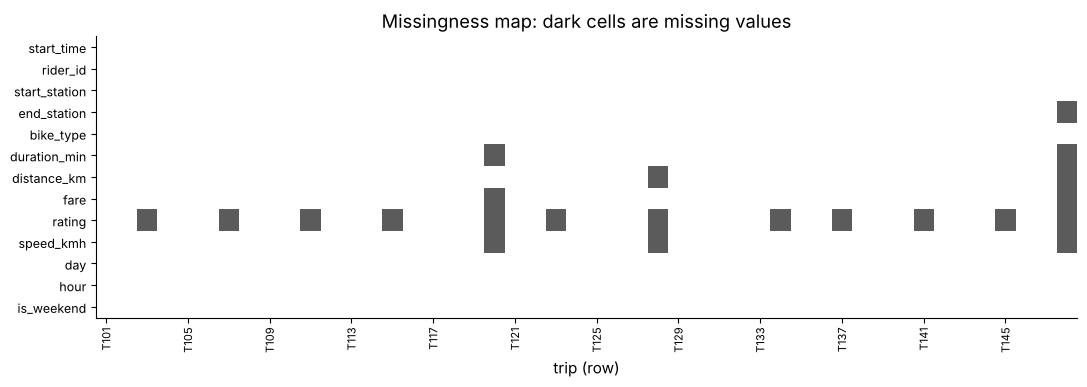

In [100]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.imshow(gaps.T.to_numpy(), aspect="auto", cmap="Greys", interpolation="nearest", vmin=0, vmax=1.4)
ax.set_yticks(range(gaps.shape[1]))
ax.set_yticklabels(gaps.columns, fontsize=9)
ax.set_xticks(range(0, len(gaps), 4))
ax.set_xticklabels(gaps.index[::4], rotation=90, fontsize=8)
ax.grid(False)
ax.set_xlabel("trip (row)")
ax.set_title("Missingness map: dark cells are missing values")
fig.tight_layout()
plt.show()

The `rating` row is speckled across the whole week (riders skip ratings at random), while the other gaps cluster in three columns of the map: T120 (lock fault), T128 (GPS) and T148 (unfinished). The two kinds call for different treatments: a missing rating is a *normal* event that the analysis must tolerate, while T148 is a record that is not finished yet.

### 8.3 Dropping: `dropna`

In [101]:
for kwargs in [{}, {"subset": ["duration_min"]}, {"how": "all"}, {"thresh": 12}, {"axis": 1}]:
    print(f"dropna({', '.join(f'{k}={v!r}' for k, v in kwargs.items())})".ljust(36), "->", trips.dropna(**kwargs).shape)

dropna()                             -> (36, 13)
dropna(subset=['duration_min'])      -> (46, 13)
dropna(how='all')                    -> (48, 13)
dropna(thresh=12)                    -> (45, 13)
dropna(axis=1)                       -> (48, 7)


* `dropna()` drops every row with **any** gap: 12 of 48 rows (25% of the data) disappear, mostly because of the optional rating, which says nothing about a trip's duration or fare.
* `subset=[...]` only looks at the columns you name, which is almost always what you want: to study durations, drop the rows without a duration (2 rows), nothing more.
* `how="all"` drops a row only if *all* its values are missing (none here), `thresh=k` keeps rows with at least `k` non-missing values, and `axis=1` drops **columns** instead of rows (6 of our 13 columns have gaps).

> **Common pitfall.** Dropping incomplete rows is only guaranteed to be harmless when values are missing *completely at random*: whether a value is missing has nothing to do with the trip, the rider or the value itself. If, say, unhappy riders were less likely to leave a rating, the remaining ratings would overstate satisfaction, and dropping or ignoring the gaps would hide that bias. Always ask *why* values are missing.

### 8.4 Filling: `fillna`, `ffill`, `interpolate`, group-wise filling

Filling ("imputation") replaces gaps with plausible values. The choice of value matters, as the ratings show:

In [102]:
r = trips["rating"]
comparison = pd.DataFrame({
    "mean": [r.mean(), r.fillna(0).mean(), r.fillna(r.median()).mean()],
    "std": [r.std(), r.fillna(0).std(), r.fillna(r.median()).std()],
}, index=["ignore gaps (36 values)", "fill with 0", "fill with the median (4.0)"]).round(2)
comparison

,mean,std
ignore gaps (36 values),3.89,1.01
fill with 0,2.92,1.91
fill with the median (4.0),3.92,0.87


* Filling with 0 claims that 12 riders gave zero stars, a rating that does not even exist: the mean collapses from 3.89 to 2.92 and the spread is inflated.
* Filling with the median keeps the center (3.92) but **shrinks the spread** (standard deviation 0.87 instead of 1.01), because 12 identical values were added. Simple imputation always makes data look more certain than it is.
* It is often wise to keep a flag, e.g. `trips["rating_missing"] = trips["rating"].isna()`, *before* filling, so that the information "this value was missing" is not lost (it can even be a useful feature for a model).

**Smarter, group-wise filling.** A distance depends on the route. T128 went from MKT to LIB, a route ridden four other times this week, always 0.9 km. Filling with the median distance *of the same route* is far better than the global median (2.85 km). The tool is `groupby(...).transform(...)` (explained in Section 10), which computes a statistic per group and returns it aligned with the original rows:

In [103]:
route_median = trips.groupby(["start_station", "end_station"])["distance_km"].transform("median")
filled_distance = trips["distance_km"].fillna(route_median)
print("T128: before", trips.at["T128", "distance_km"], "| route median", route_median["T128"],
      "| after", filled_distance["T128"])
print("global median distance:", trips["distance_km"].median())

T128: before nan | route median 0.9 | after 0.9
global median distance: 2.85


**Ordered data: forward fill and interpolation.** For measurements taken over time, a gap is often best filled from its neighbors. Suppose a dock sensor at Harbor Square reports the number of available bikes every hour, and two readings were lost:

In [104]:
readings = pd.Series([12, 10, np.nan, np.nan, 4, 6],
                     index=pd.date_range("2026-05-04 06:00", periods=6, freq="h"), name="bikes")
pd.DataFrame({"raw": readings, "ffill": readings.ffill(), "bfill": readings.bfill(),
              "interpolate": readings.interpolate()})

,raw,ffill,bfill,interpolate
2026-05-04 06:00:00,12.0,12.0,12.0,12.0
2026-05-04 07:00:00,10.0,10.0,10.0,10.0
2026-05-04 08:00:00,NaN,10.0,4.0,8.0
2026-05-04 09:00:00,NaN,10.0,4.0,6.0
2026-05-04 10:00:00,4.0,4.0,4.0,4.0
2026-05-04 11:00:00,6.0,6.0,6.0,6.0


`ffill` carries the last known value forward (10, 10), `bfill` pulls the next one backward (4, 4), and `interpolate` draws a straight line between the neighbors (8, 6). Which one is right depends on the physics: a counter that only changes when someone docks is well described by `ffill`, and a smoothly varying quantity (a temperature) by `interpolate`.

> **Going deeper.** In machine learning, fill values are *learned from data* (a mean, a median, a route median), so they must be learned **from the training set only** and then applied unchanged to validation and test data. Computing them on the full dataset leaks information from the test set into training. scikit-learn's `SimpleImputer` inside a `Pipeline` enforces this discipline.

### 8.5 How computations treat missing values

Most pandas reductions **skip** missing values by default (`skipna=True`). NumPy functions do not.

In [105]:
print(f"count = {r.count()}  | size = {r.size}  | len = {len(r)}")
print(f"sum = {r.sum()}  | mean = {r.mean():.4f}  | sum/count = {r.sum() / r.count():.4f}  | sum/size = {r.sum() / r.size:.4f}")
print("mean(skipna=False)        :", r.mean(skipna=False))
print("np.mean on the raw array  :", np.mean(r.to_numpy()), "| np.nanmean:", round(np.nanmean(r.to_numpy()), 4))
all_missing = pd.Series([np.nan, np.nan])
print("sum of an all-NaN Series  :", all_missing.sum(), "| with min_count=1:", all_missing.sum(min_count=1))
print("value_counts / nunique    :", r.value_counts().sort_index().to_dict(), "/", r.nunique())

count = 36  | size = 48  | len = 48
sum = 140.0  | mean = 3.8889  | sum/count = 3.8889  | sum/size = 2.9167
mean(skipna=False)        : nan
np.mean on the raw array  : nan | np.nanmean: 3.8889
sum of an all-NaN Series  : 0.0 | with min_count=1: nan
value_counts / nunique    : {1.0: 1, 2.0: 2, 3.0: 8, 4.0: 14, 5.0: 11} / 5


The mean rating is $140 / 36 \approx 3.8889$: the sum of the 36 existing ratings divided by their **count**, not by the 48 rows ($140/48 \approx 2.9167$ would silently treat gaps as zeros). The full rulebook:

| operation | treatment of missing values |
|---|---|
| `sum`, `mean`, `median`, `std`, `min`, `max`, `cumsum`, ... | skipped (`skipna=True`), and the sum of nothing is 0 unless `min_count=1` |
| `count()` | counts **non-missing** values |
| `size`, `len()`, `shape` | count **all** rows |
| `value_counts()`, `nunique()` | ignored, unless `dropna=False` |
| `groupby` keys | rows whose key is missing are dropped, unless `groupby(..., dropna=False)` |
| comparisons `<`, `==`, ... | `False` for `NaN` (but `!=` gives `True`), and three-valued `pd.NA` for nullable dtypes |
| arithmetic `+`, `*`, ... | `NaN` propagates |
| NumPy functions on `.to_numpy()` | `NaN` propagates. Use `np.nanmean`, `np.nansum`, ... |

<details>
<summary><b>Quick check</b>: a Series holds <code>[4, NaN, 2, NaN]</code>. What are its <code>count()</code>, <code>size</code>, <code>sum()</code> and <code>mean()</code>?</summary>

`count()` = 2 (non-missing values), `size` = 4 (all entries), `sum()` = 6 and `mean()` = 6 / 2 = 3.0: the missing entries are skipped, not treated as zeros.
</details>

### ✏️ Exercise 8: a missing-value report

Write `missing_report(df)` returning a DataFrame indexed by column name, with two columns: `n_missing` (number of missing values, integer) and `pct_missing` (percentage of rows, rounded to 1 decimal). Include **only** columns with at least one missing value, sorted by `n_missing` from largest to smallest, ties broken alphabetically by column name.

In [106]:
# ✏️ Exercise 8: a missing-value report
def missing_report(df: pd.DataFrame) -> pd.DataFrame:
    """Columns with gaps: n_missing and pct_missing (1 decimal), sorted by n_missing desc, then name."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    rep = missing_report(trips)
    assert isinstance(rep, pd.DataFrame), "return a DataFrame"
    assert list(rep.columns) == ["n_missing", "pct_missing"], f"columns: {list(rep.columns)}"
    expected_order = ["rating", "speed_kmh", "distance_km", "duration_min", "fare", "end_station"]
    assert list(rep.index) == expected_order, f"rows/order: {list(rep.index)}"
    assert rep["n_missing"].tolist() == [12, 3, 2, 2, 2, 1], f"counts: {rep['n_missing'].tolist()}"
    assert np.allclose(rep["pct_missing"].to_numpy(dtype=float), [25.0, 6.2, 4.2, 4.2, 4.2, 2.1], atol=0.051), \
        f"percentages: {rep['pct_missing'].tolist()}"
    tiny = pd.DataFrame({"a": [1.0, np.nan, 3.0], "b": ["x", "y", "z"], "c": [np.nan, np.nan, 1.0]})
    rep2 = missing_report(tiny)
    assert list(rep2.index) == ["c", "a"] and rep2["n_missing"].tolist() == [2, 1], f"tiny case: {rep2}"


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def missing_report(df):
    n = df.isna().sum()
    report = pd.DataFrame({"n_missing": n, "pct_missing": (100 * n / len(df)).round(1)})
    report = report[report["n_missing"] > 0]
    return report.rename_axis("column").sort_values(["n_missing", "column"], ascending=[False, True])
```
`isna().sum()` counts per column. Naming the index (`rename_axis`) lets `sort_values` use it as a sort key alongside a regular column. Sorting with two keys and two directions is explained in Section 9. (A percentage of exactly 6.25 rounds to 6.2: NumPy rounds halves to the nearest even digit.)
</details>

## 9. Sorting and ranking

### 9.1 `sort_values` and `sort_index`

`sort_values(by)` reorders the **rows** by the values of one or more columns and returns a new table. The labels travel with their rows, so after sorting, label and position no longer agree, one more reason to keep the two systems apart.

In [107]:
longest = trips.sort_values("duration_min", ascending=False)
print(longest[["rider_id", "bike_type", "duration_min"]].head(5), "\n")
print(longest[["duration_min"]].tail(3))

        rider_id bike_type  duration_min
trip_id                                 
T138         R06  electric          41.5
T146         R09   classic          35.1
T136         R07   classic          34.7
T144         R07   classic          32.6
T143         R12   classic          24.2 

         duration_min
trip_id              
T131              5.1
T120              NaN
T148              NaN


The four longest rides are all weekend leisure trips. Missing values go **last** by default whatever the direction (`na_position="first"` changes that), so T120 and T148 end up at the bottom even in a descending sort.

**Several keys, several directions.** Pass lists: rows are ordered by the first key, ties are broken by the second, and so on. Combined with `groupby(...).head(k)`, which keeps the first `k` rows of each group in the current order, this gives a classic idiom, the *top-k per group*:

In [108]:
by_type_then_fare = trips.sort_values(["bike_type", "fare"], ascending=[True, False])
by_type_then_fare.groupby("bike_type").head(2)[["bike_type", "rider_id", "duration_min", "fare"]]

,bike_type,rider_id,duration_min,fare
trip_id,,,,
T146,classic,R09,35.1,2.75
T143,classic,R12,24.2,2.21
T138,electric,R06,41.5,7.22
T140,electric,R09,17.3,7.20


For a single top-k (or bottom-k), `nlargest` / `nsmallest` are shorter, and faster than a full sort on big tables. `keep="all"` keeps every row tied with the last one.

In [109]:
print(trips.nlargest(3, "fare")[["rider_id", "bike_type", "duration_min", "fare"]], "\n")
print(trips.nsmallest(3, "speed_kmh")[["bike_type", "start_station", "end_station", "speed_kmh"]])

        rider_id bike_type  duration_min  fare
trip_id                                       
T138         R06  electric          41.5  7.22
T140         R09  electric          17.3  7.20
T145         R06  electric          23.9  4.58 

        bike_type start_station end_station  speed_kmh
trip_id                                               
T119      classic           MKT         LIB        9.0
T136      classic           GAR         GAR        9.9
T112      classic           MKT         LIB       10.0


`sort_index()` sorts by the row labels instead (and `sort_index(axis=1)` sorts the columns by name). A sorted index is also what makes label slicing with missing endpoints work (Section 6.6).

**Sorting text that has a natural order.** Day names sort *alphabetically* (Friday, Monday, Saturday, ...), which is rarely what you want. An **ordered categorical** dtype (Section 2.11) fixes the order once and for all. Every later sort, `groupby` or plot then follows the calendar. We convert the `day` column now:

In [110]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print("alphabetical  :", sorted(trips["day"].unique()))
trips["day"] = trips["day"].astype(pd.CategoricalDtype(WEEKDAYS, ordered=True))
print("calendar order:", trips["day"].value_counts().sort_index().to_dict())

alphabetical  : ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
calendar order: {'Monday': 8, 'Tuesday': 7, 'Wednesday': 8, 'Thursday': 6, 'Friday': 6, 'Saturday': 8, 'Sunday': 5}


(`sort_values(key=...)` is the alternative when you do not want to change the dtype: the function receives the column and returns the values to sort by, for example `key=lambda s: s.map({"Monday": 0, ...})`.)

### 9.2 Ranking and ties

`rank()` assigns each value its position in the sorted order (1 = first). The interesting part is **ties**. Six riders and their weekly kilometers, ranked from most to fewest kilometers (`ascending=False`), by hand first:

| rider | km | sorted positions | `average` | `min` | `max` | `dense` | `first` |
|---|---|---|---|---|---|---|---|
| Lucas | 9.0 | 1–2 (tied with Priya) | 1.5 | 1 | 2 | 1 | 1 |
| Priya | 9.0 | 1–2 (tied with Lucas) | 1.5 | 1 | 2 | 1 | 2 |
| Sofia | 8.0 | 3 | 3 | 3 | 3 | 2 | 3 |
| Amara | 7.5 | 4–5 (tied with Mei) | 4.5 | 4 | 5 | 3 | 4 |
| Mei | 7.5 | 4–5 (tied with Amara) | 4.5 | 4 | 5 | 3 | 5 |
| Jonas | 6.0 | 6 | 6 | 6 | 6 | 4 | 6 |

* `average` (the default) gives tied values the mean of the positions they occupy: $(1+2)/2 = 1.5$.
* `min` gives them the best position: "1, 1, 3": the ranking used in sports (two gold medals, then bronze).
* `max` gives them the worst position.
* `dense` is like `min` without gaps: "1, 1, 2".
* `first` breaks ties by order of appearance in the data (Lucas appears before Priya).

In [111]:
km = pd.Series([7.5, 9.0, 7.5, 6.0, 9.0, 8.0], index=["Amara", "Lucas", "Mei", "Jonas", "Priya", "Sofia"], name="km")
ranks = pd.DataFrame({"km": km, **{m: km.rank(ascending=False, method=m)
                                   for m in ["average", "min", "max", "dense", "first"]}})
ranks.sort_values(["km", "first"], ascending=[False, True])

,km,average,min,max,dense,first
Lucas,9.0,1.5,1.0,2.0,1.0,1.0
Priya,9.0,1.5,1.0,2.0,1.0,2.0
Sofia,8.0,3.0,3.0,3.0,2.0,3.0
Amara,7.5,4.5,4.0,5.0,3.0,4.0
Mei,7.5,4.5,4.0,5.0,3.0,5.0
Jonas,6.0,6.0,6.0,6.0,4.0,6.0


The code agrees with the hand-made table. `rank(pct=True)` returns *percentile* ranks between 0 and 1, which makes ranks comparable across groups of different sizes.

Ranks combine naturally with `groupby` (Section 10): here are the two fastest trips **of each bike type**, a ranking computed separately inside each group.

In [112]:
speed_rank = trips.groupby("bike_type")["speed_kmh"].rank(ascending=False, method="min")
fastest = trips.assign(speed_rank=speed_rank).query("speed_rank <= 2")
fastest.sort_values(["bike_type", "speed_rank"])[["bike_type", "start_station", "end_station", "speed_kmh", "speed_rank"]]

,bike_type,start_station,end_station,speed_kmh,speed_rank
trip_id,,,,,
T126,classic,GAR,HAR,15.1,1.0
T117,classic,GAR,HAR,14.8,2.0
T107,electric,STN,HAR,17.7,1.0
T121,electric,STN,HAR,16.6,2.0


All four fastest trips end at Harbor Square, the lowest station (4 m): riding downhill pays off. We will quantify this effect in the case study.

<details>
<summary><b>Quick check</b>: what does <code>pd.Series([3, 1, 3, 2]).rank(method="dense")</code> return? And with <code>method="min"</code>?</summary>

Ascending order is 1, 2, 3, 3. Dense ranks: 1 → 1, 2 → 2, 3 → 3, so the result is `[3.0, 1.0, 3.0, 2.0]`. With `min`, the two 3s occupy positions 3 and 4 and both get 3, so the result is the same here: `[3.0, 1.0, 3.0, 2.0]`. They would differ for a value *after* the tie, which `dense` would rank 4 and `min` would rank 5.
</details>

## 10. `groupby`: split–apply–combine

"What is the average duration **per bike type**?", "How much revenue **per station**?", "How many trips **per rider**?". Questions of the form "*statistic* per *group*" are answered by `groupby`, the most powerful tool in pandas.

### 10.1 The idea, by hand first

`groupby` performs three steps, a pattern called **split–apply–combine**:

```
                split                         apply                combine
             ┌─► rows with bike_type == "classic"  (27) ─► mean(duration) ─┐
  trips ─────┤                                                           ├─► one value per group
             └─► rows with bike_type == "electric" (21) ─► mean(duration) ─┘
```

Let us do it manually with a loop and boolean masks, then with one line of pandas:

In [113]:
by_hand = {}
for bike in sorted(trips["bike_type"].unique()):              # split ...
    rows = trips[trips["bike_type"] == bike]
    by_hand[bike] = rows["duration_min"].mean()               # ... apply ...
by_hand = pd.Series(by_hand, name="duration_min")             # ... combine
with_groupby = trips.groupby("bike_type")["duration_min"].mean()
print(with_groupby.round(2), "\n")
print("same result:", np.allclose(by_hand, with_groupby))

bike_type
classic     15.77
electric    13.74
Name: duration_min, dtype: float64 

same result: True


Classic trips last 15.77 minutes on average and electric ones 13.74. Read the one-liner from left to right: *group the trips by `bike_type`*, *take the column `duration_min`*, *compute the mean of each group*. The result is a Series indexed by the **group keys**. Besides being shorter, `groupby` is much faster than the loop: it scans the data once instead of once per group.

### 10.2 The `GroupBy` object, `size` versus `count`, several keys

`trips.groupby("bike_type")` alone computes nothing yet: it returns a `GroupBy` object that knows which rows belong to which group and waits for an aggregation.

In [114]:
groups = trips.groupby("bike_type")
print("number of groups:", groups.ngroups, "| keys:", list(groups.groups))
print("rows in the 'electric' group:", groups.get_group("electric").shape)
print("size()          :", groups.size().to_dict())
print("['rating'].count():", groups["rating"].count().to_dict())

number of groups: 2 | keys: ['classic', 'electric']
rows in the 'electric' group: (21, 13)
size()          : {'classic': 27, 'electric': 21}
['rating'].count(): {'classic': 22, 'electric': 14}


`size()` counts **rows** per group, and `count()` counts **non-missing values** per column and group. The difference (27 versus 22 for classic bikes) is the number of unrated trips. Mixing them up is a common source of wrong percentages.

**Several keys** produce a result indexed by a two-level **`MultiIndex`**. `unstack()` turns the inner level into columns, giving a readable 2-D table:

In [115]:
duration_by_daytype = trips.groupby(["is_weekend", "bike_type"])["duration_min"].mean().round(1)
print(duration_by_daytype, "\n")
duration_by_daytype.unstack()

is_weekend  bike_type
False       classic      12.4
            electric     10.7
True        classic      27.2
            electric     20.9
Name: duration_min, dtype: float64 



bike_type,classic,electric
is_weekend,,
False,12.4,10.7
True,27.2,20.9


Weekend trips last roughly twice as long as weekday trips for both bike types (27.2 versus 12.4 minutes on classic bikes): commuters versus leisure riders. Grouping by two keys revealed what the overall averages hid. (To get the keys back as ordinary columns, use `groupby(..., as_index=False)` or call `.reset_index()` on the result.)

### 10.3 Several statistics at once: `agg` and named aggregation

**Named aggregation** is the most readable way to build a summary table: each keyword argument creates one output column, as `new_name=(input_column, function)`. The function can be a name (`"sum"`, `"mean"`, `"nunique"`, `"size"`, ...) or any Python function that reduces a Series to one value.

In [116]:
station_summary = (
    trips.groupby("start_station")
         .agg(departures=("rider_id", "size"),
              riders=("rider_id", "nunique"),
              mean_duration=("duration_min", "mean"),
              revenue=("fare", "sum"),
              share_electric=("bike_type", lambda s: (s == "electric").mean()))
         .round(2)
         .sort_values("departures", ascending=False)
)
station_summary

,departures,riders,mean_duration,revenue,share_electric
start_station,,,,,
MKT,11,6,9.25,13.12,0.36
GAR,9,5,23.38,8.06,0.11
STN,9,3,11.13,7.56,0.78
HAR,8,5,19.27,22.60,0.88
UNI,7,3,13.70,0.00,0.00
LIB,4,3,10.57,3.50,0.50


Market Hall (MKT) is the busiest departure station (11 trips by 6 different riders), but Harbor Square (HAR) earns by far the most (\$22.60). Its high electric share (88%) is not the reason on its own: 78% of North Station's (STN) departures are electric too, yet STN earned only \$7.56, because all of them are members' commutes (\$0.10 per minute on an electric bike, free on a classic one). What sets HAR apart is its customers: five of its eight departures were day-pass rides (four on the weekend), and they brought in \$18.59 of the \$22.60, since casual riders pay a \$1.00 unlock fee plus a higher price per minute. Section 14.3 finds the same pattern across the whole system. University Gate (UNI) earned nothing: all its departures were classic bikes ridden by members.

Two other forms of `agg` are common: a **list** of functions applied to every selected column (producing two-level column labels), and a **dict** mapping each column to its function:

In [117]:
print(trips.groupby("bike_type")[["duration_min", "fare"]].agg(["mean", "max"]).round(2), "\n")
print(trips.groupby("bike_type").agg({"duration_min": "mean", "fare": "sum"}).round(2))

          duration_min        fare      
                  mean   max  mean   max
bike_type                               
classic          15.77  35.1  0.39  2.75
electric         13.74  41.5  2.23  7.22 

           duration_min   fare
bike_type                     
classic           15.77  10.18
electric          13.74  44.66


### 10.4 `transform`: group statistics aligned with the original rows

An aggregation returns **one row per group**. Often you need the group statistic **next to every original row** instead, to compare each row with its group. That is `transform`: it computes the statistic per group and broadcasts it back, so the result has exactly the same index as the input.

```
  aggregate:  48 rows ──► 13 rows (one per rider)
  transform:  48 rows ──► 48 rows (each row receives its rider's value)
```

In [118]:
rider_km = trips.groupby("rider_id")["distance_km"].transform("sum")
type_mean_speed = trips.groupby("bike_type")["speed_kmh"].transform("mean")
context = pd.DataFrame({
    "rider_id": trips["rider_id"], "distance_km": trips["distance_km"],
    "rider_week_km": rider_km, "share_of_week": (trips["distance_km"] / rider_km).round(3),
    "speed_kmh": trips["speed_kmh"], "vs_type_mean": (trips["speed_kmh"] - type_mean_speed).round(1),
})
context.head(4)

,rider_id,distance_km,rider_week_km,share_of_week,speed_kmh,vs_type_mean
trip_id,,,,,,
T101,R01,2.6,17.9,0.145,15.8,1.7
T102,R05,4.4,18.7,0.235,13.3,1.3
T103,R03,0.9,3.6,0.250,10.4,-1.6
T104,R08,3.2,19.3,0.166,14.5,0.3


Trip T101 covered 2.6 of rider R01's 17.9 weekly kilometers (14.5%), and it was 1.7 km/h faster than the average electric trip. `transform` is also the tool behind group-wise imputation (Section 8.4) and behind "keep the rows whose group satisfies a condition", as we see next.

### 10.5 `filter`: keep or drop whole groups

`filter(func)` calls `func` on each group (a sub-DataFrame) and keeps **all** the rows of the groups for which it returns `True`. Here are the trips of "regular" riders, those with at least 4 trips this week, computed in two equivalent ways:

In [119]:
regulars = trips.groupby("rider_id").filter(lambda g: len(g) >= 4)
regulars_fast = trips[trips.groupby("rider_id")["rider_id"].transform("size") >= 4]
print("riders:", sorted(regulars["rider_id"].unique()), "| trips:", len(regulars))
print("both methods agree:", regulars.equals(regulars_fast))

riders: ['R01', 'R02', 'R03', 'R05', 'R07', 'R08'] | trips: 29
both methods agree: True


The `transform` version avoids calling a Python function once per group and scales better to millions of rows.

### 10.6 `idxmax` and `apply`

To fetch the **row** holding a group's maximum (not just the maximal value), combine `idxmax`, which returns the *label* of the maximum in each group, with `.loc`:

In [120]:
longest_per_rider = trips.loc[trips.groupby("rider_id")["duration_min"].idxmax(),
                              ["rider_id", "day", "start_station", "end_station", "duration_min"]]
longest_per_rider.head(6)

,rider_id,day,start_station,end_station,duration_min
trip_id,,,,,
T127,R01,Thursday,UNI,STN,13.6
T129,R02,Thursday,MKT,STN,13.1
T119,R03,Wednesday,MKT,LIB,6.0
T141,R04,Saturday,GAR,HAR,18.0
T110,R05,Tuesday,GAR,HAR,20.4
T138,R06,Saturday,HAR,HAR,41.5


`apply(func)` is the general fallback: `func` receives each group as a DataFrame and may return a scalar, a Series or a DataFrame. Its flexibility costs speed, and there is often a vectorized alternative. Example: the **average price per minute** for each bike type. Should we average the per-trip ratios, or divide total fares by total minutes?

In [121]:
per_minute_apply = trips.groupby("bike_type")[["fare", "duration_min"]].apply(
    lambda g: g["fare"].sum() / g["duration_min"].sum())
totals = trips.groupby("bike_type")[["fare", "duration_min"]].sum()
per_minute_vectorized = totals["fare"] / totals["duration_min"]
mean_of_ratios = (trips["fare"] / trips["duration_min"]).groupby(trips["bike_type"]).mean()
pd.DataFrame({"ratio of sums (apply)": per_minute_apply, "ratio of sums (vectorized)": per_minute_vectorized,
              "mean of ratios": mean_of_ratios}).round(4)

,ratio of sums (apply),ratio of sums (vectorized),mean of ratios
bike_type,,,
classic,0.0248,0.0248,0.0217
electric,0.1625,0.1625,0.1544


The first two columns agree: "total revenue per minute ridden" is a **ratio of sums**, and computing it from the aggregated totals avoids `apply` entirely. The third column, the **mean of per-trip ratios**, is a different quantity (0.1544 versus 0.1625 \$/min for electric bikes): it gives every trip the same weight, whereas the ratio of sums weights trips by their duration. Neither is "wrong", but they answer different questions. Be explicit about which one you report.

> **Version note.** In pandas 2.2+, `groupby(...).apply(func)` warns if `func` may operate on the grouping column itself, and pandas 3 excludes that column from the groups. Selecting the needed columns first, as above (`groupby("bike_type")[["fare", "duration_min"]]`), is clean in both versions.

### 10.7 Categorical keys and `observed=True`

When the grouping key is **categorical**, pandas must decide what to do with categories that never occur. `observed=False` keeps them as empty groups, and `observed=True` keeps only the categories that actually appear. The default changes from `False` (pandas 2, with a `FutureWarning`) to `True` (pandas 3), so **always pass `observed=` explicitly** when grouping by a categorical:

In [122]:
bike_with_cargo = trips["bike_type"].astype(pd.CategoricalDtype(["classic", "electric", "cargo"]))
print("observed=False:", trips.groupby(bike_with_cargo, observed=False).size().to_dict())
print("observed=True :", trips.groupby(bike_with_cargo, observed=True).size().to_dict())
trips_per_day = trips.groupby(["day", "bike_type"], observed=True).size().unstack()
trips_per_day

observed=False: {'classic': 27, 'electric': 21, 'cargo': 0}
observed=True : {'classic': 27, 'electric': 21}


bike_type,classic,electric
day,,
Monday,5,3
Tuesday,4,3
Wednesday,4,4
Thursday,5,1
Friday,3,3
Saturday,3,5
Sunday,3,2


The planned cargo bikes are a category with no trips yet: `observed=False` reports 0 for them, which is useful for complete reports, while `observed=True` omits them. Because `day` is an ordered categorical (Section 9.1), the rows come out in calendar order. A grouped table like this is one line away from a chart:

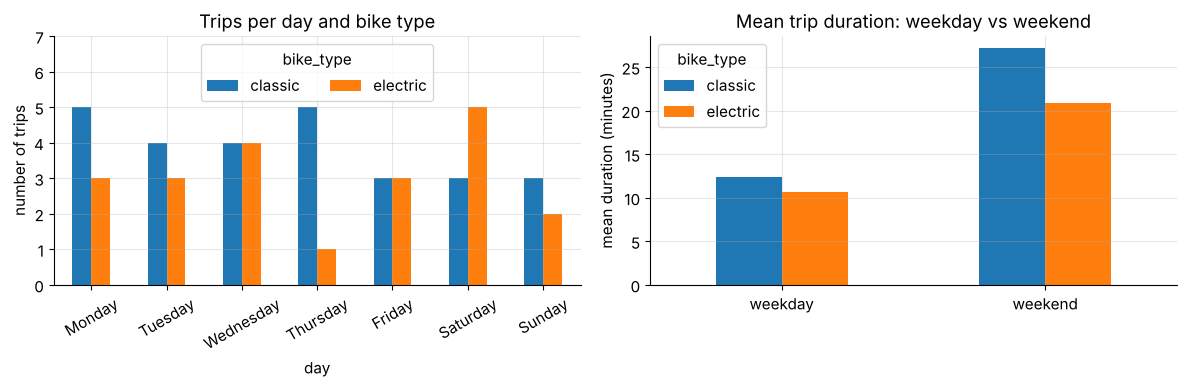

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
trips_per_day.plot.bar(ax=axes[0], color=["tab:blue", "tab:orange"], rot=30)
axes[0].set_xlabel("day")
axes[0].set_ylabel("number of trips")
axes[0].set_title("Trips per day and bike type")
axes[0].set_ylim(0, trips_per_day.to_numpy().max() + 2)            # leave room for the legend
axes[0].legend(title="bike_type", ncol=2, loc="upper center")
duration_by_daytype.unstack().rename(index={False: "weekday", True: "weekend"}).plot.bar(
    ax=axes[1], color=["tab:blue", "tab:orange"], rot=0)
axes[1].set_xlabel("")
axes[1].set_ylabel("mean duration (minutes)")
axes[1].set_title("Mean trip duration: weekday vs weekend")
fig.tight_layout()
plt.show()

<details>
<summary><b>Quick check</b>: <code>df.groupby("g")["x"].mean()</code> and <code>df.groupby("g")["x"].transform("mean")</code>: what are the lengths of the two results if <code>df</code> has 1,000 rows and 7 groups?</summary>

The aggregation returns one value per group: length 7, indexed by the group keys. `transform` returns one value per original row: length 1,000, with the same index as `df`, so it can be used directly in arithmetic with `df["x"]`.
</details>

### ✏️ Exercise 9: a rider summary with named aggregation

Write `rider_summary(trips)` returning one row per rider (indexed by `rider_id`) with the columns
`n_trips` (number of trips), `total_km` (sum of `distance_km`, gaps skipped), `mean_rating` (mean of the existing ratings) and `electric_share` (fraction of the rider's trips made on electric bikes), sorted by `n_trips` (largest first), ties broken by `rider_id` (ascending).

In [124]:
# ✏️ Exercise 9: a rider summary with named aggregation
def rider_summary(trips: pd.DataFrame) -> pd.DataFrame:
    """One row per rider: n_trips, total_km, mean_rating, electric_share, sorted by n_trips desc, rider_id asc."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = rider_summary(trips)
    assert isinstance(out, pd.DataFrame), "return a DataFrame"
    assert list(out.columns) == ["n_trips", "total_km", "mean_rating", "electric_share"], f"columns: {list(out.columns)}"
    assert out.shape == (13, 4), f"expected 13 riders, got shape {out.shape}"
    assert out.index[:3].tolist() == ["R01", "R08", "R02"], f"order: {out.index[:3].tolist()}"
    r01 = out.loc["R01"]
    assert r01["n_trips"] == 7 and abs(r01["total_km"] - 17.9) < 1e-9, f"R01: {r01.to_dict()}"
    assert abs(r01["mean_rating"] - 29 / 7) < 1e-9 and abs(r01["electric_share"] - 4 / 7) < 1e-9, f"R01: {r01.to_dict()}"
    assert abs(out.at["R07", "total_km"] - 12.4) < 1e-9, "R07: the missing distance of T128 must be skipped"
    assert abs(out.at["R10", "mean_rating"] - 2.0) < 1e-9 and out.at["R08", "electric_share"] == 1.0


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def rider_summary(trips):
    out = (trips.assign(is_electric=trips["bike_type"] == "electric")
                .groupby("rider_id")
                .agg(n_trips=("bike_type", "size"),
                     total_km=("distance_km", "sum"),
                     mean_rating=("rating", "mean"),
                     electric_share=("is_electric", "mean")))
    return out.sort_values(["n_trips", "rider_id"], ascending=[False, True])
```
Adding a boolean helper column first turns "share of electric trips" into a plain `"mean"` (the mean of a boolean is the fraction of `True`), which is faster than a `lambda`. `sum` and `mean` skip missing values automatically.
</details>

### ✏️ Exercise 10: rider context with `transform`

Write `add_rider_context(trips)` returning a **new** DataFrame with three extra columns:

* `rider_trips`: the number of trips the same rider made this week,
* `km_share`: the trip's `distance_km` divided by the rider's total distance (`NaN` where the distance is missing),
* `first_trip`: `True` for each rider's earliest trip of the week (by `start_time`), `False` otherwise.

In [125]:
# ✏️ Exercise 10: rider context with transform
def add_rider_context(trips: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of trips with rider_trips, km_share and first_trip columns."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    original = trips.copy()
    out = add_rider_context(trips)
    assert trips.equals(original) and "km_share" not in trips.columns, "do not modify the input"
    assert out.shape == (48, trips.shape[1] + 3) and out.index.equals(trips.index), "one row per trip, same index"
    assert out.at["T101", "rider_trips"] == 7 and out.at["T142", "rider_trips"] == 1, "rider_trips is wrong"
    assert abs(out.at["T101", "km_share"] - 2.6 / 17.9) < 1e-9, f"km_share of T101 should be 2.6/17.9"
    assert pd.isna(out.at["T128", "km_share"]), "T128 has no distance: its share should be NaN"
    shares = out.groupby("rider_id")["km_share"].sum()
    assert np.allclose(shares, 1.0), "the shares of each rider should add up to 1"
    firsts = out.index[out["first_trip"]].tolist()
    assert len(firsts) == 13 and "T101" in firsts and "T106" not in firsts, f"first trips: {firsts}"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def add_rider_context(trips):
    by_rider = trips.groupby("rider_id")
    return trips.assign(
        rider_trips=by_rider["rider_id"].transform("size"),
        km_share=trips["distance_km"] / by_rider["distance_km"].transform("sum"),
        first_trip=trips["start_time"] == by_rider["start_time"].transform("min"),
    )
```
Each `transform` returns a Series aligned with `trips`, so it can be combined with the original columns in ordinary vectorized arithmetic and comparisons.
</details>

## 11. Reshaping: `pivot_table`, `crosstab`, `melt`, `pivot`

The same information can be laid out in different **shapes**. Here are the fares of three days, first in **long** format (one row per *day × bike type* combination), then in **wide** format (one row per day, one column per bike type):

```
  LONG (one row per observation)          WIDE (one row per day, one column per bike type)
  day        bike_type   revenue          day        classic   electric
  Monday     classic        0.00          Monday        0.00       3.43
  Monday     electric       3.43   <-->   Tuesday       0.00       2.80
  Tuesday    classic        0.00          Saturday      3.88      23.79
  Tuesday    electric       2.80
  Saturday   classic        3.88
  Saturday   electric      23.79
```

* The **long** format is what `groupby`, plotting libraries and databases like: every variable is a column, every observation a row (statisticians call this *tidy data*). Adding a new bike type adds rows, not columns.
* The **wide** format is what humans like to read and what a report shows: a compact 2-D grid. It is also the natural input of a heatmap.

Moving from long to wide is a **pivot** (with aggregation: `pivot_table`, or counting: `crosstab`). Moving from wide to long is a **melt**.

### 11.1 `pivot_table`: a `groupby` laid out as a grid

`pivot_table(index=..., columns=..., values=..., aggfunc=...)` groups the rows by the `index` key **and** the `columns` key, aggregates `values` in each group with `aggfunc`, and arranges the results in a grid. Here is the revenue per day and bike type:

In [126]:
revenue_grid = trips.pivot_table(index="day", columns="bike_type", values="fare",
                                 aggfunc="sum", observed=True)
print(revenue_grid, "\n")
same_with_groupby = trips.groupby(["day", "bike_type"], observed=True)["fare"].sum().unstack()
print("identical to groupby + unstack:", revenue_grid.equals(same_with_groupby))

bike_type  classic  electric
day                         
Monday        0.00      3.43
Tuesday       0.00      2.80
Wednesday     0.00      4.67
Thursday      0.00      0.97
Friday        1.40      4.42
Saturday      3.88     23.79
Sunday        4.90      4.58 

identical to groupby + unstack: True


A `pivot_table` really is a two-key `groupby` followed by `unstack()`: the check above confirms it. Reading the grid, the classic-bike revenue is zero on Monday to Thursday (classic bikes are free for members, and only members rode then), and Saturday's electric revenue (\$23.79) dwarfs every other cell: the casual weekend riders pay per minute.

Useful options:

| option | effect |
|---|---|
| `aggfunc` | `"mean"` (the default!), `"sum"`, `"count"`, `"size"`, a list of functions, or a dict per column |
| `fill_value` | value for the cells of combinations that never occur (instead of `NaN`) |
| `margins=True` | adds a row and a column of totals, computed with the same `aggfunc` on the raw data |
| `observed=True` | for categorical keys, show only the categories that occur (as in `groupby`, Section 10.7) |

> **Common pitfall.** The default `aggfunc` is `"mean"`, not `"sum"`. A pivot table of fares without `aggfunc=` shows the average fare per cell, which is easy to misread as revenue.

In [127]:
with_totals = trips.pivot_table(index="day", columns="bike_type", values="fare", aggfunc="sum",
                                margins=True, margins_name="total", observed=True)
print(with_totals, "\n")
print(trips.pivot_table(index="is_weekend", columns="bike_type", values="duration_min",
                        aggfunc=["mean", "count"]).round(1))

bike_type  classic  electric  total
day                                
Monday        0.00      3.43   3.43
Tuesday       0.00      2.80   2.80
Wednesday     0.00      4.67   4.67
Thursday      0.00      0.97   0.97
Friday        1.40      4.42   5.82
Saturday      3.88     23.79  27.67
Sunday        4.90      4.58   9.48
total        10.18     44.66  54.84 

              mean            count         
bike_type  classic electric classic electric
is_weekend                                  
False         12.4     10.7      20       14
True          27.2     20.9       6        6


The margins give the week's totals: \$54.84 of revenue, \$44.66 of it from electric bikes. The second table applies two functions at once and gets **two-level column labels** (function, then bike type). `count` reminds us that the weekend averages rest on only 6 trips per bike type.

### 11.2 `crosstab`: frequency tables

`pd.crosstab(a, b)` counts how often each combination of the values of `a` and `b` occurs. With start and end stations it produces the **origin–destination matrix** of the network, the basic tool of transport planning. We fix the order of the stations from the river (HAR, 4 m) up to the hill (GAR, 93 m) with `reindex`:

In [128]:
STATION_ORDER = ["HAR", "MKT", "LIB", "STN", "UNI", "GAR"]            # by elevation, low -> high
od = (pd.crosstab(trips["start_station"], trips["end_station"], margins=True, margins_name="total")
        .reindex(index=STATION_ORDER + ["total"], columns=STATION_ORDER + ["total"], fill_value=0))
od

end_station,HAR,MKT,LIB,STN,UNI,GAR,total
start_station,,,,,,,
HAR,2,2,0,3,0,1,8
MKT,1,0,5,2,0,2,10
LIB,1,1,0,0,2,0,4
STN,3,2,0,0,4,0,9
UNI,3,0,1,3,0,0,7
GAR,7,0,0,0,0,2,9
total,17,5,6,8,6,5,47


Rows are origins, columns are destinations: 7 trips went from the Botanic Gardens (GAR, on the hill) down to Harbor Square (HAR, by the river), but only **one** went the other way. Three details to notice:

* The grand total is **47**, not 48: trip T148 has no end station, and `crosstab` (like `groupby`) silently drops rows with a missing key. That is also why MKT shows 10 departures here, against the 11 found by `describe` in Section 4.3.
* The diagonal holds the **round trips** (start = end): 2 at HAR and 2 at GAR, the leisure loops of the weekend.
* The `total` column counts departures per station, the `total` row arrivals. HAR receives 17 trips but sends only 8: bikes pile up at the bottom of the hill. The case study (Section 14) turns this observation into a rebalancing plan.

`normalize="index"` divides each row by its total, turning counts into **conditional proportions**: "given that a trip starts at station $s$, what fraction ends at each destination?", an estimate of $P(\text{end} \mid \text{start} = s)$:

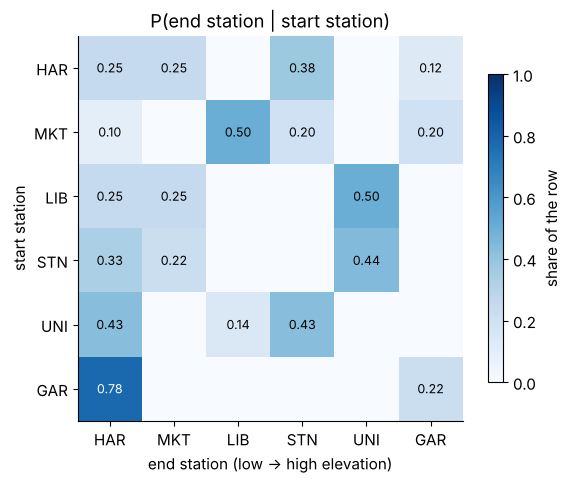

In [129]:
od_share = (pd.crosstab(trips["start_station"], trips["end_station"], normalize="index")
              .reindex(index=STATION_ORDER, columns=STATION_ORDER, fill_value=0))

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(od_share.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(STATION_ORDER)))
ax.set_xticklabels(STATION_ORDER)
ax.set_yticks(range(len(STATION_ORDER)))
ax.set_yticklabels(STATION_ORDER)
for i in range(len(STATION_ORDER)):
    for j in range(len(STATION_ORDER)):
        share = od_share.iat[i, j]
        if share > 0:
            ax.text(j, i, f"{share:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if share > 0.5 else "black")
ax.grid(False)
ax.set_xlabel("end station (low -> high elevation)")
ax.set_ylabel("start station")
ax.set_title("P(end station | start station)")
fig.colorbar(im, ax=ax, shrink=0.8, label="share of the row")
plt.show()

Each row of the heatmap sums to 1. Since the columns are sorted by elevation, cells left of the diagonal are downhill trips and cells right of it are uphill trips. Both kinds are about equally frequent (22 downhill and 21 uphill trips, as the case study will count), but they look very different: downhill trips **converge** on Harbor Square (78% of the trips from GAR, 43% from UNI, 33% from STN), while uphill trips **spread** over several destinations. `crosstab` also accepts `values=` and `aggfunc=` (then it behaves like `pivot_table` on two Series) and `normalize="columns"` or `normalize="all"`.

### 11.3 `melt`: from wide to long

The station staff record the number of available bikes three times a day in a spreadsheet with one column per check time: a typical **wide** table, good for reading but awkward to analyze (what is the average over all checks? which check was the lowest?).

In [130]:
checks_wide = pd.DataFrame({
    "station": ["HAR", "MKT", "UNI"],
    "06:00": [6, 9, 15],
    "12:00": [14, 7, 8],
    "18:00": [18, 4, 3],
})
checks_long = checks_wide.melt(id_vars="station", var_name="check_time", value_name="bikes")
print(checks_wide, "\n")
print(checks_long)

  station  06:00  12:00  18:00
0     HAR      6     14     18
1     MKT      9      7      4
2     UNI     15      8      3 

  station check_time  bikes
0     HAR      06:00      6
1     MKT      06:00      9
2     UNI      06:00     15
3     HAR      12:00     14
4     MKT      12:00      7
5     UNI      12:00      8
6     HAR      18:00     18
7     MKT      18:00      4
8     UNI      18:00      3


`melt` keeps the identifier column(s) given in `id_vars`, and turns every other column into rows: the old column **label** goes into `var_name`, the cell **value** into `value_name`. A 3 × 3 block of measurements became 9 rows. Now every question is a one-liner on ordinary columns:

In [131]:
print("mean per check time:", checks_long.groupby("check_time")["bikes"].mean().round(2).to_dict())
print("lowest reading     :", checks_long.loc[checks_long["bikes"].idxmin()].to_dict())

mean per check time: {'06:00': 10.0, '12:00': 9.67, '18:00': 8.33}
lowest reading     : {'station': 'UNI', 'check_time': '18:00', 'bikes': 3}


The pattern of the readings tells the same story as the origin–destination matrix: the hill station UNI empties during the day (15 → 3) while the river station HAR fills up (6 → 18).

### 11.4 `pivot`: from long to wide, without aggregation

`pivot(index, columns, values)` is the exact inverse of `melt`. Unlike `pivot_table` it does **not** aggregate, so each (index, column) pair must occur **at most once**. Otherwise pandas cannot know which value to put in the cell:

In [132]:
back_to_wide = checks_long.pivot(index="station", columns="check_time", values="bikes")
print(back_to_wide, "\n")
print("round trip recovers the values:",
      back_to_wide.reset_index().rename_axis(columns=None).equals(checks_wide))
duplicated_check = pd.concat([checks_long, checks_long.iloc[[0]].assign(bikes=7)])   # HAR 06:00 twice
attempt('duplicated_check.pivot(index="station", columns="check_time", values="bikes")', width=150)
print(duplicated_check.pivot_table(index="station", columns="check_time", values="bikes", aggfunc="mean"))

check_time  06:00  12:00  18:00
station                        
HAR             6     14     18
MKT             9      7      4
UNI            15      8      3 

round trip recovers the values: True
duplicated_check.pivot(index="station", columns="check_time", values="bikes") raises ValueError: Index contains duplicate entries, cannot reshape
check_time  06:00  12:00  18:00
station                        
HAR           6.5   14.0   18.0
MKT           9.0    7.0    4.0
UNI          15.0    8.0    3.0


With a duplicated measurement (HAR at 06:00 recorded as 6 **and** 7), `pivot` refuses with `ValueError: Index contains duplicate entries`, while `pivot_table` resolves the conflict with its `aggfunc` (here the mean, 6.5). Rule of thumb: use `pivot` when the data is guaranteed to have one value per cell (the error then acts as a free sanity check), and `pivot_table` when you *want* aggregation.

| from → to | method | aggregates? |
|---|---|---|
| long → wide | `pivot(index, columns, values)` | no: duplicates raise `ValueError` |
| long → wide | `pivot_table(index, columns, values, aggfunc)` | yes (default `"mean"`) |
| long → wide (counts) | `pd.crosstab(a, b)` | yes (counts, or `aggfunc`) |
| long → wide | `groupby([k1, k2])[v].agg(f).unstack()` | yes |
| wide → long | `melt(id_vars, var_name, value_name)` | no |
| wide ↔ long (on the index) | `stack()` / `unstack()` | no |

<details>
<summary><b>Quick check</b>: a long table has 4 stations × 7 days = 28 rows with columns <code>station</code>, <code>day</code>, <code>trips</code>. What is the shape of <code>df.pivot(index="station", columns="day", values="trips")</code>? And what does <code>melt</code> give back, starting from that result after <code>reset_index()</code>?</summary>

The pivot has one row per station and one column per day: shape (4, 7). After `reset_index()` the table has 4 rows and 8 columns (`station` plus the 7 days). `melt(id_vars="station")` turns the 7 day columns into rows: 4 × 7 = 28 rows with 3 columns (`station`, `day`, `value`), the original long table again (up to row order and column names).
</details>

### ✏️ Exercise 11: a busiest-hours grid

Write `hour_grid(trips)` that returns a DataFrame with **one row per hour of the day from 6 to 21 inclusive** (16 rows, index named `hour`, in increasing order) and **two columns**, `weekday` and `weekend`, holding the **number of trips** that started in that hour. Hours without trips must show 0, and the values must be integers.

In [133]:
# ✏️ Exercise 11: a busiest-hours grid
def hour_grid(trips: pd.DataFrame) -> pd.DataFrame:
    """Trips per start hour (rows 6..21) for weekdays and weekends (columns 'weekday', 'weekend')."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    grid = hour_grid(trips)
    assert isinstance(grid, pd.DataFrame), "return a DataFrame"
    assert grid.index.tolist() == list(range(6, 22)), f"rows should be the hours 6..21, got {grid.index.tolist()}"
    assert grid.index.name == "hour", f"the index should be named 'hour', got {grid.index.name!r}"
    assert list(grid.columns) == ["weekday", "weekend"], f"columns: {list(grid.columns)}"
    assert all(pd.api.types.is_integer_dtype(t) for t in grid.dtypes), f"use integer counts, got {grid.dtypes.tolist()}"
    assert grid.loc[8, "weekday"] == 10 and grid.loc[17, "weekday"] == 6, "weekday rush-hour counts are wrong"
    assert grid.loc[6].sum() == 0 and grid.loc[20].sum() == 0, "empty hours must show 0"
    assert grid["weekday"].sum() == 35 and grid["weekend"].sum() == 13, "every trip must be counted once"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet: fill in the function and re-run this cell.

<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def hour_grid(trips):
    day_type = np.where(trips["is_weekend"], "weekend", "weekday")
    grid = pd.crosstab(trips["hour"], day_type)
    grid = grid.reindex(index=range(6, 22), columns=["weekday", "weekend"], fill_value=0)
    return grid.rename_axis(index="hour", columns=None)
```
`crosstab` counts the (hour, day type) combinations that occur, and `reindex` with `fill_value=0` adds the empty hours as zero rows and fixes the column order. An equivalent route is `trips.groupby(["hour", day_type]).size().unstack(fill_value=0)` followed by the same `reindex`.
</details>

## 12. Combining tables: `merge` and `concat`

Real information is spread over several tables: the trip log knows *which* rider and *which* station, the rider registry knows the rider's *plan*, the station table knows the station's *name* and *elevation*. Answering "how much do day-pass riders spend on the hill?" requires **combining** them. pandas has two tools:

* **`merge`** puts tables side by side, matching rows through the values of **key** columns (the database *join*),
* **`concat`** stacks tables on top of each other (or side by side), matching along an axis.

### 12.1 A first merge: looking up station details

Each trip has a `start_station` code. `station_info` has one row per `code` with the name, zone, docks and elevation. Merging attaches the matching station row to every trip:

In [134]:
trips_with_start = trips.reset_index().merge(
    station_info, left_on="start_station", right_on="code", how="left", validate="many_to_one")
print("rows before / after:", len(trips), "/", len(trips_with_start))
print("index after merge  :", trips_with_start.index[:4].tolist(), "...")
trips_with_start[["trip_id", "start_station", "code", "name", "zone", "elevation_m"]].head(4)

rows before / after: 48 / 48
index after merge  : [0, 1, 2, 3] ...


,trip_id,start_station,code,name,zone,elevation_m
0,T101,STN,STN,North Station,downtown,38
1,T102,GAR,GAR,Botanic Gardens,hill,93
2,T103,MKT,MKT,Market Hall,downtown,17
3,T104,HAR,HAR,Harbor Square,riverside,4


Line by line:

* `left_on="start_station", right_on="code"`: the key columns have different names in the two tables. When they share a name, write `on="rider_id"`. Both key columns are kept (`start_station` and `code` hold the same values here), so you would usually `drop(columns="code")`.
* `how="left"`: keep **every** trip, even one whose station were unknown (it would get `NaN` station details).
* `validate="many_to_one"`: assert that each code appears **at most once** in `station_info` (many trips share one station). Section 12.3 explains why this one argument can save an analysis.
* **The index is not preserved.** `merge` on columns returns a fresh `RangeIndex` 0, 1, 2, ... That is why we called `reset_index()` first: it turned `trip_id` into a column that survives the merge, and a `set_index("trip_id")` afterwards restores the labels.

For a **single** looked-up column, `map` (Section 7.1) is shorter and keeps the index: `trips["start_station"].map(station_info.set_index("code")["name"])`. `merge` shines when you need several columns or several keys.

### 12.2 The four join types and `indicator=True`

What happens to rows whose key has **no partner** on the other side? That is what `how` decides. A tiny example, by hand first: trip counts for three riders, and plans for three riders, with two riders in common.

In [135]:
rides = pd.DataFrame({"rider_id": ["R04", "R09", "R14"], "trips": [3, 3, 1]})
plans = pd.DataFrame({"rider_id": ["R04", "R09", "R13"], "plan": ["day-pass", "day-pass", "monthly"]})
for how in ["inner", "left", "right", "outer"]:
    print(f'how="{how}"')
    print(rides.merge(plans, on="rider_id", how=how, indicator=True).to_string(index=False), "\n")

how="inner"
rider_id  trips     plan _merge
     R04      3 day-pass   both
     R09      3 day-pass   both 

how="left"


rider_id  trips     plan    _merge
     R04      3 day-pass      both
     R09      3 day-pass      both
     R14      1      NaN left_only 

how="right"
rider_id  trips     plan     _merge
     R04    3.0 day-pass       both
     R09    3.0 day-pass       both
     R13    NaN  monthly right_only 

how="outer"


rider_id  trips     plan     _merge
     R04    3.0 day-pass       both
     R09    3.0 day-pass       both
     R13    NaN  monthly right_only
     R14    1.0      NaN  left_only 



```
       rides keys          plans keys
     ┌──────────────┬──────────────┬──────────────┐
     │   R14        │  R04   R09   │        R13   │
     │  left_only   │    both      │  right_only  │
     └──────────────┴──────────────┴──────────────┘
  inner = both (2 rows)          left  = both + left_only  (3 rows)
  outer = all three (4 rows)     right = both + right_only (3 rows)
```

| `how` | keeps | rows here | unmatched side filled with |
|---|---|---|---|
| `"inner"` (**the default**) | keys present in **both** tables | 2 | (no unmatched rows) |
| `"left"` | all keys of the left table | 3 | `NaN` in the right table's columns (R14 has no plan) |
| `"right"` | all keys of the right table | 3 | `NaN` in the left table's columns (R13 has no trips) |
| `"outer"` | keys of either table (sorted) | 4 | `NaN` on whichever side is missing |

Notice that `trips` became `float64` (3.0, 3.0, `NaN`) in the right and outer joins: a gap in an integer column forces floats, once again (Section 2.11).

`indicator=True` adds a `_merge` column saying where each row came from. It is the standard tool for **auditing** the overlap of two tables, which we now do on the real data: which riders appear in the trip log but not in the registry, and vice versa?

In [136]:
trips_per_rider = trips.groupby("rider_id").size().rename("n_trips").reset_index()
rider_audit = trips_per_rider.merge(rider_info, on="rider_id", how="outer", indicator=True)
print(rider_audit["_merge"].value_counts(), "\n")
rider_audit.loc[rider_audit["_merge"] != "both", ["rider_id", "n_trips", "name", "plan", "_merge"]]

_merge
both          12
left_only      1
right_only     1
Name: count, dtype: int64

,rider_id,n_trips,name,plan,_merge
12,R13,NaN,Kwame Mensah,monthly,right_only
13,R14,1.0,NaN,NaN,left_only


Twelve riders match. `R14` (the kiosk day-pass rider of Section 3.4) rode once but is missing from the registry, and `R13` is registered but did not ride. An inner join would have **silently dropped** R14's trip: since `"inner"` is the default, a forgotten `how=` is a classic source of vanishing rows. Always compare row counts before and after a merge, or audit with `indicator=True`.

### 12.3 `validate=` and the row-multiplication trap

Suppose the station table is updated by someone who **adds** a row for Market Hall's new name instead of replacing the old row. The code `MKT` now appears twice:

In [137]:
renamed_row = pd.DataFrame({"code": ["MKT"], "name": ["Market Hall East"], "zone": ["downtown"],
                            "docks": [15], "elevation_m": [17]})
stations_dup = pd.concat([station_info, renamed_row], ignore_index=True)
bad_merge = trips.reset_index().merge(stations_dup, left_on="start_station", right_on="code", how="left")
print("rows   :", len(trips), "->", len(bad_merge))
print("revenue:", round(trips["fare"].sum(), 2), "->", round(bad_merge["fare"].sum(), 2))
print("MKT departures:", (trips["start_station"] == "MKT").sum(),
      "| MKT revenue:", round(trips.loc[trips["start_station"] == "MKT", "fare"].sum(), 2))

rows   :

 48 -> 59
revenue: 54.84 -> 67.96
MKT departures: 11 | MKT revenue: 13.12


The merge did not fail. It **duplicated** every MKT trip (one copy per matching station row). The table grew from 48 to 59 rows (11 MKT departures counted twice), and the "total revenue" jumped from \$54.84 to \$67.96, inflated by exactly MKT's \$13.12. Nothing in the output looks wrong unless you check.

The rule behind it: a merge pairs **every** left row with **every** right row that has the same key. If key $k$ occurs $n_L(k)$ times on the left and $n_R(k)$ times on the right, an inner join produces

$$
\text{rows} = \sum_{k} n_L(k)\, n_R(k)
$$

rows (a left join adds one row for each left row whose key has $n_R(k) = 0$). With unique keys on the right, every $n_R(k) \in \{0, 1\}$: a **left** join then keeps exactly the left table's size, and an inner join can only shrink it (by dropping the left rows without a partner). With duplicates on **both** sides (a *many-to-many* merge), the count can explode: two tables of 1,000 rows sharing a single key value produce 1,000,000 rows.

`validate=` turns your assumption about the keys into a check that fails loudly:

In [138]:
flat_trips = trips.reset_index()
attempt('flat_trips.merge(stations_dup, left_on="start_station", right_on="code", validate="m:1")',
        width=200)
attempt('flat_trips.merge(station_info, left_on="start_station", right_on="code", validate="m:1")',
        width=200)
print("duplicated codes:", stations_dup.loc[stations_dup["code"].duplicated(keep=False), ["code", "name"]]
      .to_dict("records"))

flat_trips.merge(stations_dup, left_on="start_station", right_on="code", validate="m:1") raises MergeError: Merge keys are not unique in right dataset; not a many-to-one merge
flat_trips.merge(station_info, left_on="start_station", right_on="code", validate="m:1") -> DataFrame (48, 19)


duplicated codes: [{'code': 'MKT', 'name': 'Market Hall'}, {'code': 'MKT', 'name': 'Market Hall East'}]


| `validate=` | asserts | typical case |
|---|---|---|
| `"one_to_one"` / `"1:1"` | keys unique on both sides | two tables describing the same entities |
| `"one_to_many"` / `"1:m"` | keys unique on the left | riders (left) → their trips (right) |
| `"many_to_one"` / `"m:1"` | keys unique on the right | trips (left) → station details (right): **lookups** |
| `"many_to_many"` / `"m:m"` | nothing (documents the intent) | rarely what you want |

> **Key idea.** Before every merge, say out loud which side should have unique keys, write it as `validate=`, and compare the row counts before and after. Most silent analytics bugs in real projects are duplicated or vanished rows after a join.

> **Going deeper.** Unlike SQL, pandas **matches missing keys with each other**: a `NaN` (or `None`) key on the left joins with a `NaN` key on the right. If both tables can have missing keys, drop or fill them before merging.

### 12.4 Several keys, suffixes, and joining on the index

**Several keys.** The tariff depends on two things, the member type and the bike type, so it is merged on **both** columns: `on=["member_type", "bike_type"]` matches a row only when *all* keys agree. The case study uses exactly this to recompute every fare.

**Suffixes.** When both tables have a non-key column with the same name, pandas renames them with `suffixes=("_x", "_y")` by default. Choose meaningful ones. Here we attach both the start and the end station names:

In [139]:
station_names = station_info[["code", "name"]]
both_names = (trips.reset_index()
                   .merge(station_names, left_on="start_station", right_on="code", how="left")
                   .merge(station_names, left_on="end_station", right_on="code", how="left",
                          suffixes=("_start", "_end"))
                   .set_index("trip_id"))
print(both_names.shape)
both_names[["start_station", "name_start", "end_station", "name_end"]].tail(3)

(48, 17)


,start_station,name_start,end_station,name_end
trip_id,,,,
T146,HAR,Harbor Square,HAR,Harbor Square
T147,GAR,Botanic Gardens,HAR,Harbor Square
T148,MKT,Market Hall,NaN,NaN


Thanks to `how="left"`, the unfinished trip T148 is kept with a missing end name, and with the default inner join it would have disappeared. `set_index("trip_id")` restored the row labels.

**Joining on the index.** When the right table is indexed by the key (like `riders`, read with `index_col="rider_id"` in Section 4.4), `df.join(other, on="key_column")` is a convenient shortcut. It is a left join by default and, unlike `merge`, it **keeps the left table's index**:

In [140]:
with_plan = trips.join(riders, on="rider_id")
print(with_plan.shape, "| index kept:", with_plan.index[:3].tolist())
with_plan.loc["T140":"T143", ["rider_id", "name", "plan", "fare"]]

(48, 16)

 | index kept: ['T101', 'T102', 'T103']


,rider_id,name,plan,fare
trip_id,,,,
T140,R09,Diego Alvarez,day-pass,7.20
T141,R04,Jonas Becker,day-pass,3.70
T142,R14,NaN,NaN,1.67
T143,R12,Elif Kaya,day-pass,2.21


Trip T142 belongs to the unregistered rider R14, so its `name` and `plan` are missing: a left join keeps the trip and marks the gap. The general `merge` can also use indexes as keys, with `left_index=True` and / or `right_index=True`.

### 12.5 `concat`: stacking tables

`pd.concat(list_of_tables)` glues tables together along an axis. With the default `axis=0` it stacks **rows**, aligning the **columns by label**. Here are the first trips of the following week, exported by a newer version of the app that also records a `promo_code` and no longer exports ratings:

In [141]:
next_week = pd.DataFrame({
    "trip_id": ["T149", "T150"],
    "start_time": pd.to_datetime(["2026-05-11 07:41", "2026-05-11 07:58"]),
    "rider_id": ["R01", "R05"], "start_station": ["STN", "GAR"], "end_station": ["UNI", "HAR"],
    "bike_type": ["electric", "classic"], "duration_min": [10.2, 19.4], "distance_km": [2.6, 4.7],
    "fare": [1.02, 0.0], "promo_code": ["SPRING", np.nan],
}).set_index("trip_id")
log_cols = ["rider_id", "start_station", "bike_type", "fare", "rating"]
two_weeks = pd.concat([trips[log_cols + ["start_time"]], next_week])
print(two_weeks.shape, "| index unique:", two_weeks.index.is_unique)
two_weeks[log_cols + ["promo_code"]].iloc[46:]

(50, 10)

 | index unique: True


,rider_id,start_station,bike_type,fare,rating,promo_code
trip_id,,,,,,
T147,R06,GAR,classic,2.15,4.0,NaN
T148,R12,MKT,electric,NaN,NaN,NaN
T149,R01,STN,electric,1.02,NaN,SPRING
T150,R05,GAR,classic,0.00,NaN,NaN


* The result has the **union** of the columns: the old trips have no `promo_code` and the new ones have no `rating`, so both get `NaN`. Check `two_weeks.columns` after stacking tables from different sources: a misspelled column name (`"Fare"` versus `"fare"`) would produce two half-empty columns instead of an error.
* Row labels are kept as they are. Here the trip ids are unique across weeks, but stacking tables with default labels 0, 1, 2, ... produces **duplicate labels**. Use `ignore_index=True` to renumber, `keys=[...]` to record the origin of each row in an extra index level, or `verify_integrity=True` to raise an error on duplicates:

In [142]:
week_a = pd.DataFrame({"station": ["HAR", "MKT"], "trips": [8, 11]})
week_b = pd.DataFrame({"station": ["HAR", "MKT"], "trips": [10, 9]})
print(pd.concat([week_a, week_b]).index.tolist(), "<- duplicated labels")
print(pd.concat([week_a, week_b], ignore_index=True).index.tolist(), "<- renumbered")
print(pd.concat([week_a, week_b], keys=["week 19", "week 20"]), "\n")
attempt("pd.concat([week_a, week_b], verify_integrity=True)", width=120)

[0, 1, 0, 1] <- duplicated labels
[0, 1, 2, 3] <- renumbered
          station  trips
week 19 0     HAR      8
        1     MKT     11
week 20 0     HAR     10
        1     MKT      9 



pd.concat([week_a, week_b], verify_integrity=True) raises ValueError: Indexes have overlapping values: Index([0, 1], dtype='int64')

With `axis=1`, `concat` places tables **side by side** and aligns the **rows by label**, exactly like the dict-of-Series constructor of Section 3.1 (an outer join on the index by default, and `join="inner"` keeps the common labels only):

In [143]:
departures = trips["start_station"].value_counts().rename("departures")
arrivals = trips["end_station"].value_counts().rename("arrivals")
pd.concat([departures, arrivals, station_info.set_index("code")["elevation_m"]], axis=1).loc[STATION_ORDER]

,departures,arrivals,elevation_m
HAR,8,17,4
MKT,11,5,17
LIB,4,6,29
STN,9,8,38
UNI,7,6,71
GAR,9,5,93


| task | tool |
|---|---|
| add columns from a lookup table, by key values | `merge(..., how="left", validate="many_to_one")`, or `map` for one column |
| combine tables on their indexes | `join`, or `concat(axis=1)` |
| append rows (same columns) | `concat([...], ignore_index=True)` |
| audit the overlap of two key sets | `merge(..., how="outer", indicator=True)` |

> **Common pitfall.** Appending rows one at a time with `pd.concat` inside a loop copies the whole table at every iteration. Collect the pieces in a list and call `pd.concat(pieces)` **once** (Section 13.3 times both).

<details>
<summary><b>Quick check</b>: table <code>A</code> has key column values <code>[1, 1, 2, 3]</code> and table <code>B</code> has <code>[1, 1, 1, 2, 4]</code>. How many rows do the inner, left and outer merges on that key produce?</summary>

Inner: key 1 gives $2 \times 3 = 6$ rows, key 2 gives $1 \times 1 = 1$, keys 3 and 4 give nothing: **7 rows**. Left: the 7 matched rows plus the unmatched left row with key 3: **8 rows**. Outer: the 7 matched rows plus key 3 (left only) and key 4 (right only): **9 rows**. Neither table has unique keys, so `validate="many_to_one"` and `"one_to_many"` would both raise.
</details>

### ✏️ Exercise 12: station names, safely

Write `add_station_names(trips, stations)` returning a **new** DataFrame with the **same index, rows and order** as `trips`, plus two columns `start_name` and `end_name` holding the full station names (`NaN` where the end station is missing). `stations` has the columns `code` and `name` (and possibly others). If a code is duplicated in `stations`, your function must raise `pd.errors.MergeError` instead of silently duplicating trips.

In [144]:
# ✏️ Exercise 12: station names, safely
def add_station_names(trips: pd.DataFrame, stations: pd.DataFrame) -> pd.DataFrame:
    """Return trips (same index and order) plus start_name and end_name. Raise MergeError on duplicated codes."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    original = trips.copy()
    out = add_station_names(trips, station_info)
    assert trips.equals(original), "do not modify the input"
    assert out.index.equals(trips.index), "keep the trip ids as the index, in the original order"
    assert out.shape == (48, trips.shape[1] + 2), f"expected shape (48, {trips.shape[1] + 2}), got {out.shape}"
    assert out.at["T101", "start_name"] == "North Station" and out.at["T101", "end_name"] == "University Gate"
    assert pd.isna(out.at["T148", "end_name"]), "T148 has no end station: end_name should be missing"
    try:
        add_station_names(trips, stations_dup)
    except pd.errors.MergeError:
        pass
    else:
        raise AssertionError("a duplicated station code must raise pd.errors.MergeError")


run_check("Exercise 12", _test)

⏳ Exercise 12: not implemented yet: fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def add_station_names(trips, stations):
    names = stations[["code", "name"]]
    return (trips.reset_index()
                 .merge(names.rename(columns={"code": "start_station", "name": "start_name"}),
                        on="start_station", how="left", validate="many_to_one")
                 .merge(names.rename(columns={"code": "end_station", "name": "end_name"}),
                        on="end_station", how="left", validate="many_to_one")
                 .set_index("trip_id"))
```
Renaming the lookup columns before each merge avoids the extra `code` column and the suffixes. `how="left"` keeps every trip in its original order, `validate="many_to_one"` raises on duplicated codes, and `reset_index` / `set_index` carry the trip ids through the merge.
</details>

## 13. Performance: vectorization and memory

Our trip log has 48 rows, so everything is instantaneous. A real bike-share produces millions of trips per year, and then *how* you write pandas code decides whether an analysis takes a second or an hour. Two resources matter: **time** (avoid Python-level loops) and **memory** (choose compact dtypes).

### 13.1 Loops, `apply` and vectorized code

To measure honestly, we generate a synthetic log of 200,000 trips with the same tariff as Riverton (Section 3.4) and compute every fare in four ways:

1. a Python loop over `iterrows()`, which builds a `Series` object for every row,
2. a Python loop over `itertuples()`, which yields light named tuples,
3. `df.apply(func, axis=1)`, which calls a Python function once per row (it is a loop in disguise),
4. **vectorized** code: whole-column arithmetic with `np.where` / `np.select`, executed by compiled NumPy loops.

The slow methods run on the first 20,000 rows only, and we compare the **time per row**.

In [145]:
N_BIG = 200_000
big = pd.DataFrame({
    "member": rng.random(N_BIG) < 0.7,                                    # 70% members
    "bike_type": rng.choice(["classic", "electric"], size=N_BIG, p=[0.6, 0.4]),
    "duration_min": rng.gamma(shape=2.0, scale=7.0, size=N_BIG).round(1),
})


def fare_of(member: bool, bike_type: str, minutes: float) -> float:
    """Fare of one trip under the Riverton tariff (scalar inputs)."""
    if member:
        return 0.10 * minutes if bike_type == "electric" else 0.0
    return 1.00 + (0.15 if bike_type == "electric" else 0.05) * minutes


def fares_vectorized(df: pd.DataFrame) -> np.ndarray:
    """Same tariff, whole columns at once."""
    electric = (df["bike_type"] == "electric").to_numpy()
    member = df["member"].to_numpy()
    per_min = np.select([member & electric, member & ~electric, ~member & electric],
                        [0.10, 0.00, 0.15], default=0.05)
    unlock = np.where(member, 0.0, 1.0)
    return unlock + per_min * df["duration_min"].to_numpy()


def time_per_row(func, n_rows: int, repeat: int = 1) -> float:
    """Best wall-clock time of func() over `repeat` runs, divided by n_rows (seconds per row)."""
    best = min(_timed(func) for _ in range(repeat))
    return best / n_rows


def _timed(func) -> float:
    t0 = time.perf_counter()
    func()
    return time.perf_counter() - t0


small = big.iloc[:20_000]
methods = {
    "iterrows loop": (lambda: [fare_of(r["member"], r["bike_type"], r["duration_min"])
                               for _, r in small.iterrows()], len(small), 1),
    "itertuples loop": (lambda: [fare_of(r.member, r.bike_type, r.duration_min)
                                 for r in small.itertuples(index=False)], len(small), 3),
    "apply(axis=1)": (lambda: small.apply(lambda r: fare_of(r["member"], r["bike_type"],
                                                            r["duration_min"]), axis=1), len(small), 1),
    "vectorized": (lambda: fares_vectorized(big), len(big), 5),
}
per_row = {name: time_per_row(func, n, rep) for name, (func, n, rep) in methods.items()}
timing = pd.DataFrame({"µs per row": pd.Series(per_row) * 1e6})
timing["slower than vectorized"] = timing["µs per row"] / timing.loc["vectorized", "µs per row"]
print(timing.round(3).to_string(), "\n")

reference = np.array([fare_of(m, b, d) for m, b, d in zip(small["member"], small["bike_type"],
                                                           small["duration_min"])])
print("all methods agree:", np.allclose(reference, fares_vectorized(small)))
print(f"estimated time for 1 million trips: iterrows ≈ {per_row['iterrows loop'] * 1e6:.0f} s, "
      f"vectorized ≈ {per_row['vectorized'] * 1e6 * 1000:.0f} ms")

                 µs per row  slower than vectorized
iterrows loop       275.009                 473.220
itertuples loop       4.868                   8.376
apply(axis=1)        53.617                  92.262
vectorized            0.581                   1.000 

all methods agree: True
estimated time for 1 million trips: iterrows ≈ 275 s, vectorized ≈ 581 ms


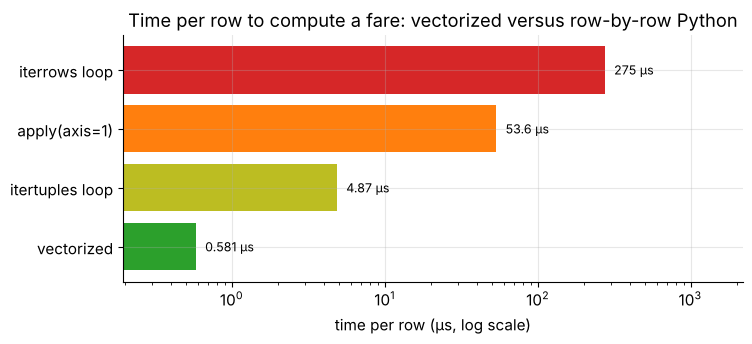

In [146]:
fig, ax = plt.subplots(figsize=(8, 3.2))
order = timing["µs per row"].sort_values()
ax.barh(order.index, order.to_numpy(), color=["tab:green", "tab:olive", "tab:orange", "tab:red"])
ax.set_xscale("log")
ax.set_xlabel("time per row (µs, log scale)")
ax.set_title("Time per row to compute a fare: vectorized versus row-by-row Python")
for y, value in enumerate(order.to_numpy()):
    ax.text(value * 1.15, y, f"{value:.3g} µs", va="center", fontsize=9)
ax.set_xlim(order.min() / 3, order.max() * 8)
plt.show()

The exact numbers depend on your machine, but the ranking never changes, and the gaps are measured in **orders of magnitude** (the axis is logarithmic):

* `iterrows` is the slowest: for every row it builds a full `Series` (an index, a dtype check, a new object). It also silently **converts dtypes**, since a row of mixed types becomes an `object` Series.
* `apply(axis=1)` is not vectorization. It is a convenient way to write the same row loop, with similar overhead.
* `itertuples` is the least bad loop: plain tuples, no Series objects.
* The vectorized version needs less than a microsecond per row (0.58 µs in the run above, though timings depend strongly on how busy the machine is, and on an idle CPU core this code needs about 0.1 µs per row or less): each `==` / `np.where` / `np.select` / `*` / `+` is a single compiled loop over a whole column, with no Python function call per element.

**Why?** For each element, a Python loop must fetch the object, look up its type, dispatch the operation, allocate the result object and count references, which costs tens to hundreds of nanoseconds even for `a * b`, and calling a Python function per row (as `fare_of` does) adds more. A compiled loop over a `float64` array does the multiplication directly on raw 8-byte numbers, often several per CPU instruction (SIMD), at around a nanosecond per element. (In pandas 2, the one comparatively slow step of our vectorized version is `bike_type == "electric"` on an `object` column, which still compares Python string objects one by one, inside C code. pandas 3's `str` dtype makes this comparison several times faster when the `pyarrow` package is installed, and in either version a `category` column (Section 13.2) turns it into a comparison of small integers.)

> **Key idea.** Think in **columns**, not rows. Most "for each row, if ... then ..." logic has a vectorized form: arithmetic between columns, comparisons and boolean masks, `np.where` (two branches), `np.select` (many branches), `Series.map` (lookups), `pd.cut` (binning), `groupby(...).transform` (group statistics), `merge` (lookups in another table). Use `apply` only when nothing else fits, and prefer built-in aggregation names (`"sum"`, `"mean"`) over `lambda`s in `groupby`.

### 13.2 Memory: `memory_usage` and the `category` dtype

`df.memory_usage(deep=True)` reports the bytes used by each column. `deep=True` matters for text: without it, pandas counts only the 8-byte pointers of an `object` column, not the Python string objects they point to.

In [147]:
stations_big = pd.DataFrame({
    "start_station": rng.choice(STATION_ORDER, size=N_BIG),
    "bike_type": big["bike_type"],
    "duration_min": big["duration_min"],
    "docks_free": rng.integers(0, 25, size=N_BIG),
})
compact = stations_big.astype({"start_station": "category", "bike_type": "category"}).assign(
    duration_min=lambda d: d["duration_min"].astype("float32"),
    docks_free=lambda d: pd.to_numeric(d["docks_free"], downcast="integer"),
)
memory = pd.DataFrame({
    "dtype before": stations_big.dtypes.astype(str),
    "MB before": stations_big.memory_usage(deep=True, index=False) / 1e6,
    "dtype after": compact.dtypes.astype(str),
    "MB after": compact.memory_usage(deep=True, index=False) / 1e6,
})
memory.loc["total"] = ["", memory["MB before"].sum(), "", memory["MB after"].sum()]
print(memory.round(2).to_string())
print(f"\nthe compact table uses {memory.at['total', 'MB after'] / memory.at['total', 'MB before']:.1%} "
      "of the original memory")

              dtype before  MB before dtype after  MB after
start_station       object      10.40    category       0.2
bike_type           object      11.28    category       0.2
duration_min       float64       1.60     float32       0.8
docks_free           int64       1.60        int8       0.2
total                           24.88                   1.4

the compact table uses 5.6% of the original memory


How the savings arise, column by column (200,000 rows):

* **Text → `category`.** With six distinct station codes, a categorical stores the six strings **once** and one small integer code per row. Six categories fit in an `int8` code: 1 byte per row, so $200{,}000 \times 1$ byte $= 0.2$ MB. With the `object` dtype of pandas 2 (the version that executed this notebook), every row costs an 8-byte pointer plus a 44-byte Python string object for a three-letter code: 52 bytes per row, 10.4 MB in total. pandas 3's `str` dtype stores the characters far more compactly than `object` when the `pyarrow` package is installed, but still once per row, so `category` wins there too.
* **`float64` → `float32`** halves the size (8 → 4 bytes per value) at the cost of precision: about 7 significant digits instead of 16, plenty for durations measured to 0.1 minute, but not for money sums or IDs.
* **`int64` → `int8`** with `pd.to_numeric(..., downcast="integer")`: values between 0 and 24 fit in one byte, an 8-fold saving.

The category dtype pays off when the number of distinct values is **small compared with the number of rows**. For a column of unique values (like `trip_id`) it would *add* memory (every value stored once as a category, plus a code per row).

> **Common pitfall.** Compact dtypes have traps of their own: `int8` columns overflow silently beyond 127 (`pd.Series([127], dtype="int8") + 1` gives −128 without any warning), and `float32` sums of millions of values lose precision. Downcast columns whose range you know, and keep money in `float64` (or integer cents).

### 13.3 Building a table: one row at a time versus all at once

Section 3.2 warned against growing a DataFrame inside a loop. Here is the measurement: collect 1,000 trip records either by concatenating one-row DataFrames one at a time, or by appending dicts to a Python list and building the DataFrame **once**.

In [148]:
def build_by_concat(n: int) -> pd.DataFrame:
    """Anti-pattern: grow the table one row at a time (copies everything at each step)."""
    table = pd.DataFrame({"trip": [0], "minutes": [0.0]})
    for k in range(1, n):
        table = pd.concat([table, pd.DataFrame({"trip": [k], "minutes": [0.5 * k]})], ignore_index=True)
    return table


def build_from_list(n: int) -> pd.DataFrame:
    """Recommended: collect plain Python records, convert once."""
    records = [{"trip": k, "minutes": 0.5 * k} for k in range(n)]
    return pd.DataFrame(records)


N_ROWS = 1_000
t_concat = _timed(lambda: build_by_concat(N_ROWS))
t_list = _timed(lambda: build_from_list(N_ROWS))
print(f"concat in a loop: {t_concat * 1e3:7.1f} ms")
print(f"list, then once : {t_list * 1e3:7.1f} ms   -> {t_concat / t_list:.0f}x faster")
print("same table:", build_by_concat(50).equals(build_from_list(50)))

concat in a loop:  1932.9 ms
list, then once :    19.5 ms   -> 99x faster
same table: True


Two costs add up in the loop. Each `pd.concat` call has a fixed overhead (checking columns and dtypes, allocating a new table), which dominates for small tables like this one, and each call **copies all existing rows** into the new table, so building $n$ rows costs $1 + 2 + \dots + n = n(n+1)/2$ row copies, a **quadratic** term that dominates for large $n$. The list version does a constant amount of cheap Python work per row and a single conversion at the end: **linear** time with a small constant.

**Checklist for big data in pandas**

* Read only what you need: `usecols=`, `dtype=` (e.g. categories) and `nrows=` at read time. Parquet instead of CSV for repeated reads.
* Vectorize, group with built-in aggregations, and look up with `map` / `merge` instead of row loops.
* Check `memory_usage(deep=True)`, convert low-cardinality text to `category`, and downcast numbers whose range you know.
* Measure before optimizing (`time.perf_counter`, or `%timeit` in Jupyter): the bottleneck is rarely where you expect.

<details>
<summary><b>Quick check</b>: a column holds 10 million country codes drawn from 200 distinct countries. Roughly how many bytes per row does it need as <code>category</code>, and why is the code type not <code>int8</code>?</summary>

An `int8` code can only represent the values −128 to 127, which is not enough for 200 categories, so pandas uses `int16` codes: 2 bytes per row, about 20 MB in total, plus the 200 strings stored once (negligible). As `object` the same column would need roughly 60 bytes per row, about 600 MB.
</details>

## 14. Case study: one week of Riverton bike-share

The operations manager of the Riverton bike-share sends you the week's files with five questions:

1. **Activity.** How did trips, riders and revenue evolve over the week?
2. **Customers.** How do members and casual (day-pass) riders differ, and who brings in the money?
3. **Billing.** Was every trip charged correctly according to the tariff?
4. **Fleet.** Which stations run out of bikes and which overflow, and what should the rebalancing truck do?
5. **Terrain.** Does the hill change how people ride?

Each answer combines several tools from this notebook. We start again from the **files on disk**, exactly as you would in a fresh project, so that the analysis does not depend on any variable created earlier.

### 14.1 Load, type and check the data

In [149]:
sheets = pd.read_excel(XLSX_PATH, sheet_name=None)                  # all four sheets at once
cs_trips = sheets["trips"].pipe(set_unique_index, "trip_id")        # helper from Section 5.3
cs_riders = sheets["riders"]
cs_stations = sheets["stations"]
cs_tariff = sheets["tariff"]

cs_trips = cs_trips.assign(
    day=lambda d: d["start_time"].dt.day_name().astype(pd.CategoricalDtype(WEEKDAYS, ordered=True)),
    hour=lambda d: d["start_time"].dt.hour,
    is_weekend=lambda d: d["start_time"].dt.dayofweek >= 5,
    speed_kmh=lambda d: (d["distance_km"] / (d["duration_min"] / 60)).round(1),
)
print("shapes:", {name: frame.shape for name, frame in sheets.items()})
print("trip ids unique:", cs_trips.index.is_unique, "| period:", cs_trips["start_time"].min().date(),
      "to", cs_trips["start_time"].max().date())
print("station codes unique:", cs_stations["code"].is_unique, "| rider ids unique:", cs_riders["rider_id"].is_unique)
print("missing values:", cs_trips.isna().sum()[lambda s: s > 0].to_dict())

shapes: {'trips': (48, 10), 'stations': (6, 5), 'riders': (13, 4), 'tariff': (4, 4)}
trip ids unique: True | period: 2026-05-04 to 2026-05-10
station codes unique: True | rider ids unique: True
missing values: {'end_station': 1, 'duration_min': 2, 'distance_km': 2, 'fare': 2, 'rating': 12, 'speed_kmh': 3}


A disciplined start: the trip ids, station codes and rider ids are unique (so the merges below can be validated as many-to-one), the dates cover exactly one week, and the gaps are the known ones (T120, T128, T148 and the skipped ratings). `pipe(func, ...)` calls `func(table, ...)`, which lets our own helper sit inside a method chain.

### 14.2 Question 1: activity over the week

In [150]:
daily = (cs_trips.groupby("day", observed=True)
                 .agg(trips=("rider_id", "size"),
                      riders=("rider_id", "nunique"),
                      km=("distance_km", "sum"),
                      mean_minutes=("duration_min", "mean"),
                      revenue=("fare", "sum"))
                 .round(2))
daily

,trips,riders,km,mean_minutes,revenue
day,,,,,
Monday,8,6,22.7,12.14,3.43
Tuesday,7,5,17.5,11.27,2.80
Wednesday,8,7,21.5,12.59,4.67
Thursday,6,4,14.9,12.27,0.97
Friday,6,5,13.8,9.85,5.82
Saturday,8,6,33.5,21.70,27.67
Sunday,5,4,21.0,28.62,9.48


Weekdays are busy but cheap: 6 to 8 trips a day, 9.9 to 12.6 minutes long on average, and little revenue (members ride classic bikes for free). The weekend has a similar number of trips per day (8 and 5), but they are about **twice as long** (21.7 and 28.6 minutes on average), and Saturday alone brings in \$27.67, more than the five weekdays together (\$17.69). Remember that a sum of `daily["riders"]` would *not* count the week's riders: someone who rode on three days is counted three times. The number of distinct riders must be computed on the raw trips (`cs_trips["rider_id"].nunique()` = 13).

### 14.3 Question 2: members versus casual riders

The trip log only knows the rider id. The plan is in the rider registry. A **left** merge keeps every trip, and `indicator=True` shows that exactly one trip has no registered rider: R14's kiosk day pass. We know from the operator that unregistered riders always use a day pass, so we fill that gap explicitly, then translate plans into the tariff's member types with `map`.

In [151]:
PLAN_TO_MEMBER_TYPE = {"annual": "member", "monthly": "member", "day-pass": "casual"}
enriched = cs_trips.reset_index().merge(cs_riders[["rider_id", "plan"]], on="rider_id", how="left",
                                        validate="many_to_one", indicator=True)
print(enriched["_merge"].value_counts().to_dict())
print("unmatched riders:", enriched.loc[enriched["_merge"] == "left_only", "rider_id"].unique().tolist())
enriched = (enriched.drop(columns="_merge")
                    .assign(plan=lambda d: d["plan"].fillna("day-pass"),        # kiosk passes
                            member_type=lambda d: d["plan"].map(PLAN_TO_MEMBER_TYPE))
                    .set_index("trip_id"))
segments = enriched.groupby("member_type").agg(
    trips=("rider_id", "size"),
    riders=("rider_id", "nunique"),
    weekend_share=("is_weekend", "mean"),
    electric_share=("bike_type", lambda s: (s == "electric").mean()),
    mean_minutes=("duration_min", "mean"),
    mean_rating=("rating", "mean"),
    revenue=("fare", "sum"),
)
segments["revenue_share"] = segments["revenue"] / segments["revenue"].sum()
segments.round(2)

{'both': 47, 'left_only': 1, 'right_only': 0}
unmatched riders: ['R14']


,trips,riders,weekend_share,electric_share,mean_minutes,mean_rating,revenue,revenue_share
member_type,,,,,,,,
casual,13,5,0.85,0.62,19.61,4.33,40.54,0.74
member,35,8,0.06,0.37,13.22,3.74,14.30,0.26


Two very different customer groups:

* **Members** (8 riders) make 35 of the 48 trips, almost all on weekdays (6% on the weekend), mostly on classic bikes, about 13 minutes each: commuters. They generate only 26% of the revenue.
* **Casual riders** (5 riders) make 13 trips, 85% of them on the weekend, mostly on electric bikes, about 20 minutes each: leisure riders. They bring in **74%** of the revenue. They also rate their trips higher (4.33 versus 3.74 stars), although with so few ratings this difference could easily be chance.

Before recommending anything based on revenue, though, we should make sure the fares themselves are right.

### 14.4 Question 3: a billing audit

The tariff table gives an unlock fee and a price per minute for each (member type, bike type) pair. Merging on **both** keys attaches the right prices to every trip. The expected fare is then one vectorized line:

$$
\text{expected fare} = \text{unlock\_fee} + \text{per\_min} \times \text{duration\_min}, \quad \text{rounded to the cent.}
$$

In [152]:
audit = (enriched.reset_index()
                 .merge(cs_tariff, on=["member_type", "bike_type"], how="left", validate="many_to_one")
                 .set_index("trip_id")
                 .assign(expected_fare=lambda d: (d["unlock_fee"] + d["per_min"] * d["duration_min"]).round(2),
                         difference=lambda d: (d["fare"] - d["expected_fare"]).round(2)))
print("trips that cannot be audited (no duration or no fare):",
      audit.index[audit["difference"].isna()].tolist())
print("differences found:", audit["difference"].value_counts().sort_index().to_dict(), "\n")
suspicious = audit[audit["difference"].abs() > 0.015]                  # more than a rounding cent
suspicious[["rider_id", "member_type", "bike_type", "duration_min", "fare", "expected_fare", "difference"]]

trips that cannot be audited (no duration or no fare):

 ['T120', 'T148']
differences found: {-0.01: 1, 0.0: 43, 0.01: 1, 3.6: 1} 



,rider_id,member_type,bike_type,duration_min,fare,expected_fare,difference
trip_id,,,,,,,
T140,R09,casual,electric,17.3,7.2,3.6,3.6


Reading the audit:

* T120 and T148 cannot be checked: their duration (and fare) are missing. They need a manual follow-up, not a silent `dropna`.
* 46 trips can be audited. 43 match to the cent, and two differ by exactly one cent (T146 and T147), both casual classic trips whose exact price ends in half a cent ($1 + 0.05 \times 35.1 = 2.755$ and $1 + 0.05 \times 22.9 = 2.145$): the billing system and our computation round half-cents differently. That is a rounding convention, not an error, which is why the filter uses a tolerance of 1.5 cents.
* **Trip T140 was charged \$7.20 instead of \$3.60**: exactly twice the correct fare. Rider R09 (Diego Alvarez, day pass) was double-charged and is owed a \$3.60 refund.

The corrected revenue changes the picture of Question 2 only slightly:

In [153]:
corrected_fare = audit["fare"].where(audit["difference"].abs() <= 0.015, audit["expected_fare"])
by_type = pd.DataFrame({"charged": audit.groupby("member_type")["fare"].sum(),
                        "corrected": corrected_fare.groupby(audit["member_type"]).sum()})
by_type.loc["total"] = by_type.sum()
by_type["corrected_share"] = by_type["corrected"] / by_type.loc["total", "corrected"]
by_type.round(3)

,charged,corrected,corrected_share
member_type,,,
casual,40.54,36.94,0.721
member,14.30,14.30,0.279
total,54.84,51.24,1.000


`where(cond, other)` keeps the charged fare where the difference is within the tolerance and takes the expected fare everywhere else. One subtlety deserves a check rather than trust: for T120 and T148 the difference is `NaN`, so the condition `NaN <= 0.015` is `False` and `where` replaces their fare by the expected fare, which is also `NaN`. Nothing changes for them, and `sum()` skips them. The corrected revenue of the week is \$51.24, of which casual riders contribute 72%.

### 14.5 Question 4: where do the bikes go?

Every trip moves one bike from its start station to its end station. Over the week, a station's **net flow** is arrivals minus departures: positive means bikes pile up, negative means the station is drained.

In [154]:
flows = pd.concat([cs_trips["start_station"].value_counts().rename("departures"),
                   cs_trips["end_station"].value_counts().rename("arrivals")], axis=1)
flows = (flows.assign(net=flows["arrivals"] - flows["departures"])
              .join(cs_stations.set_index("code")[["name", "elevation_m", "docks"]])
              .sort_values("elevation_m"))
print(flows, "\n")
print("correlation between elevation and net flow:", round(flows["net"].corr(flows["elevation_m"]), 2))

     departures  arrivals  net             name  elevation_m  docks
HAR           8        17    9    Harbor Square            4     20
MKT          11         5   -6      Market Hall           17     15
LIB           4         6    2  Central Library           29     12
STN           9         8   -1    North Station           38     24
UNI           7         6   -1  University Gate           71     18
GAR           9         5   -4  Botanic Gardens           93     10 

correlation between elevation and net flow: -0.5


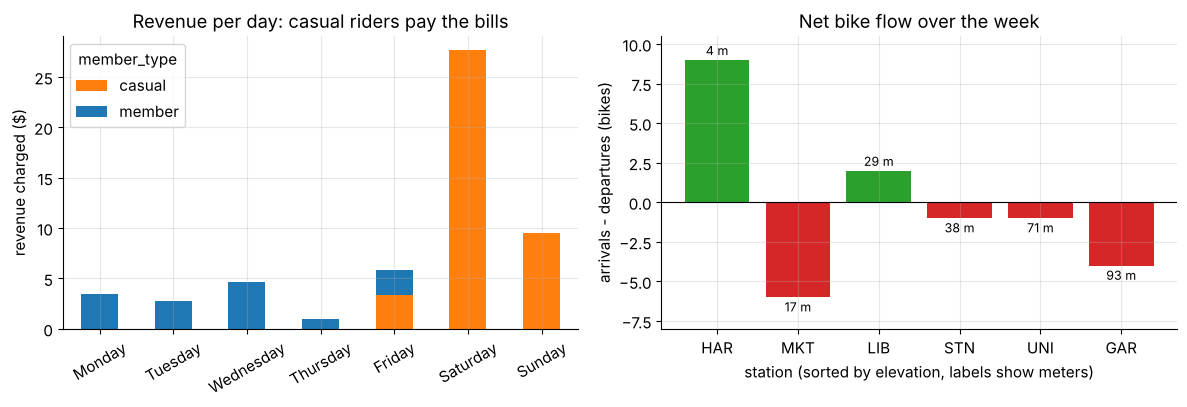

In [155]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
revenue_by_day = enriched.pivot_table(index="day", columns="member_type", values="fare",
                                      aggfunc="sum", observed=True)
revenue_by_day.plot.bar(stacked=True, ax=axes[0], color=["tab:orange", "tab:blue"], rot=30)
axes[0].set_xlabel("")
axes[0].set_ylabel("revenue charged ($)")
axes[0].set_title("Revenue per day: casual riders pay the bills")
colors = ["tab:green" if v > 0 else "tab:red" for v in flows["net"]]
axes[1].bar(flows.index, flows["net"], color=colors)
for x, (net, elev) in enumerate(zip(flows["net"], flows["elevation_m"])):
    axes[1].text(x, net + (0.3 if net >= 0 else -0.9), f"{elev} m", ha="center", fontsize=9)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylim(flows["net"].min() - 2, flows["net"].max() + 1.5)
axes[1].set_xlabel("station (sorted by elevation, labels show meters)")
axes[1].set_ylabel("arrivals - departures (bikes)")
axes[1].set_title("Net bike flow over the week")
fig.tight_layout()
plt.show()

Harbor Square, at the bottom of the hill, gained **9** bikes over the week: 17 arrivals for 8 departures. Market Hall lost 6 (its commuters ride up to the Central Library and to North Station) and the Botanic Gardens, the highest station, lost 4. The correlation between elevation and net flow is negative (−0.5), but six stations are too few for it to be convincing on its own: if the six net flows were shuffled randomly among the stations, roughly one shuffle in three would produce a correlation at least this strong. Market Hall also shows that elevation is not the whole story: commuting patterns matter too. (The flows sum to −1, not 0: the unfinished trip T148 left MKT and has not arrived anywhere yet.)

**Recommendation:** a weekly rebalancing run moving bikes **out of Harbor Square** (about 9 per week) **into Market Hall and the Botanic Gardens**. With 6 trips a day, a daily run of one or two bikes would keep the stations balanced.

### 14.6 Question 5: does the hill change how people ride?

The elevation gain of a trip is the end station's elevation minus the start station's, looked up with `map`. `np.select` labels each trip as uphill, downhill or flat (a round trip), and a pivot table compares speeds:

In [156]:
elevation_of = cs_stations.set_index("code")["elevation_m"]
gain = cs_trips["end_station"].map(elevation_of) - cs_trips["start_station"].map(elevation_of)
direction = pd.Series(np.select([gain > 0, gain < 0], ["uphill", "downhill"], default="flat"),
                      index=cs_trips.index).where(gain.notna())        # T148: no end station -> NaN
terrain = cs_trips.assign(direction=direction)
speed_table = terrain.pivot_table(index="direction", columns="bike_type", values="speed_kmh",
                                  aggfunc="mean").round(1)
bike_choice = pd.crosstab(terrain["direction"], terrain["bike_type"], margins=True, margins_name="all")
print("mean speed (km/h):")
print(speed_table, "\n")
print("number of trips:")
print(bike_choice)

mean speed (km/h):
bike_type  classic  electric
direction                   
downhill      12.7      16.1
flat          10.3      12.3
uphill        10.3      13.8 

number of trips:
bike_type  classic  electric  all
direction                        
downhill        18         4   22
flat             3         1    4
uphill           6        15   21
all             27        20   47


Two effects show up:

* **Speed.** For each bike type, downhill trips are the fastest (12.7 km/h on classic bikes, 16.1 on electric ones), as Section 9.2 suggested. Electric bikes are faster in every direction.
* **Choice of bike.** The counts tell a second story: 15 of the 21 uphill trips (71%) used an **electric** bike, but only 4 of the 22 downhill trips (18%) did. Riders pick the e-bike to climb and the free classic bike to roll down. This also explains part of the fleet imbalance: electric bikes drift uphill, classic bikes downhill.

Note `where(gain.notna())`: without it, T148 (no end station, so `gain` is `NaN`) would have been labeled `"flat"` by the `default=` of `np.select`, since `NaN > 0` and `NaN < 0` are both `False`. Missing values need a decision at **every** step.

### 14.7 The memo

| question | answer | pandas tools |
|---|---|---|
| activity | 48 trips by 13 riders, weekday commuting (short, mostly free) versus long, paid weekend leisure rides, and Saturday brought in half of the revenue charged | `groupby` + named aggregation, ordered categorical days |
| customers | members: 73% of trips, 26% of revenue, and casual riders: 27% of trips, 74% of revenue (72% after correction) | `merge(how="left", indicator=True)`, `fillna`, `map` |
| billing | T140 double-charged: refund \$3.60 to R09, T120 and T148 need manual review, and ±1 cent rounding on two trips | two-key `merge` with the tariff, vectorized expected fare, tolerance filter |
| fleet | Harbor Square +9 bikes per week, Market Hall −6, Botanic Gardens −4: move bikes uphill daily | `value_counts`, `concat(axis=1)`, `join`, bar chart |
| terrain | downhill trips are fastest, and 71% of uphill trips use e-bikes, only 18% of downhill trips | `map`, `np.select`, `where`, `pivot_table`, `crosstab` |

> **Key idea.** A real analysis is a chain of small, checkable steps: load, fix types, validate keys, merge with `validate=` and `indicator=`, compute vectorized columns, aggregate, and question every gap and every surprising number (here, a doubled fare). Each step in this case study is a technique from an earlier section.

## 15. Quiz

Ten exam-style questions. Answer each one on paper **before** opening the hidden answer. Most of them are "predict what pandas returns" questions, so you can check yourself afterwards by running the code in a new cell. Throughout, `df` is a DataFrame with row labels `["a", "b", "c"]` and columns `["x", "y", "z"]` unless the question says otherwise.

**Q1.** What does `df.loc["a":"b", "y"]` return?

- (A) a scalar
- (B) a `Series` of length 2
- (C) a `DataFrame` of shape (2, 1)
- (D) a `Series` of length 1

<details>
<summary>Answer</summary>

**(B).** The row selector is a slice (a collection), so the row axis is kept, and label slices include their stop, so rows `a` and `b` are both selected. The column selector `"y"` is a scalar, so the column axis disappears: a `Series` of length 2 indexed by `a`, `b`. (A) would need scalars on both axes, (C) would need a list `["y"]` as column selector, and (D) is what you would get if label slices excluded their stop, as position slices do.
</details>

**Q2.** `s = pd.Series([10, 20, 30], index=[2, 0, 1])`. What are `s.loc[0]` and `s.iloc[0]`?

- (A) 20 and 10
- (B) 10 and 10
- (C) 10 and 20
- (D) `s.loc[0]` raises `KeyError`

<details>
<summary>Answer</summary>

**(A).** `.loc[0]` looks for the **label** 0, which sits at position 1 and holds 20. `.iloc[0]` takes the first **position**, which holds 10 (its label is 2). (B) reads both as positions, (C) swaps the two systems, and (D) would be right only if no label 0 existed.
</details>

**Q3.** `a = pd.Series([1, 2], index=["p", "q"])` and `b = pd.Series([10, 20], index=["q", "r"])`. What is `a + b`?

- (A) `[11, 22]`
- (B) `p: NaN, q: 12.0, r: NaN`
- (C) `p: 1, q: 12, r: 20`
- (D) an error, because the indexes differ

<details>
<summary>Answer</summary>

**(B).** Arithmetic aligns on labels: the result's index is the union `p, q, r`, only `q` exists on both sides ($2 + 10 = 12$), and the others get `NaN`, which also makes the dtype `float64`. (A) pairs values by position, as NumPy would. (C) is the result of `a.add(b, fill_value=0)` (and even then the values would be floats). (D) is wrong: different indexes are exactly what alignment handles.
</details>

**Q4.** What is the dtype of `pd.Series([3, None, 5])`?

- (A) `int64`
- (B) `object`
- (C) `float64`
- (D) `Int64`

<details>
<summary>Answer</summary>

**(C).** `None` among numbers is converted to `NaN`, and only floating-point types have a `NaN`, so the integers become `3.0` and `5.0`. (A) is impossible: `int64` has no missing-value marker. (B) is what you get when `None` sits among non-numeric Python objects such as booleans or dictionaries, or among strings in pandas 2 (pandas 3 gives strings their own `str` dtype). (D) is what you get only if you ask for it with `dtype="Int64"`.
</details>

**Q5.** Which line sets `y` to 0 in the rows where `x > 0`, **in both pandas 2 and pandas 3**?

- (A) `df[df["x"] > 0]["y"] = 0`
- (B) `df.loc[df["x"] > 0, "y"] = 0`
- (C) `sub = df[df["x"] > 0]; sub["y"] = 0`
- (D) `df["y"][df["x"] > 0] = 0`

<details>
<summary>Answer</summary>

**(B).** One `.loc` call on the table itself is the only reliable way to write. (A) is chained assignment: `df[mask]` is a new table, so the write is lost in every version. (C) modifies `sub`, a separate table, never `df` (pandas 2 adds a `SettingWithCopyWarning`). (D) is chained assignment as well: it happened to work in pandas 2 (with a warning) because `df["y"]` was a view, but under Copy-on-Write it does nothing.
</details>

**Q6.** `trips` has 48 rows and its `rating` column has 12 missing values. Which expression returns 36?

- (A) `len(trips["rating"])`
- (B) `trips["rating"].size`
- (C) `trips["rating"].count()`
- (D) `trips["rating"].isna().sum()`

<details>
<summary>Answer</summary>

**(C).** `count()` counts the **non-missing** values: $48 - 12 = 36$. (A) and (B) count all entries, missing or not (48). (D) counts the missing ones (12).
</details>

**Q7.** Table `L` has key values `[1, 1, 2, 3, 4]` and table `R` has key values `[1, 1, 2, 2, 5]`. How many rows does `L.merge(R, on="k", how="inner")` produce?

- (A) 3
- (B) 5
- (C) 6
- (D) 8

<details>
<summary>Answer</summary>

**(C).** Every left row is paired with every right row that has the same key: key 1 gives $2 \times 2 = 4$ rows, key 2 gives $1 \times 2 = 2$ rows, keys 3, 4 and 5 have no partner. Total 6. (A) is the number of left rows that have a partner (the two 1s and the 2), not the number of pairs. (B) is the length of `L`, which only a *left* merge with unique right keys is guaranteed to keep. Here the right keys repeat, and an inner merge also drops the unmatched keys 3 and 4. (D) is the result of `how="left"`: the 6 matched rows plus the two unmatched left rows (keys 3 and 4).
</details>

**Q8.** What does `trips.pivot_table(index="day", columns="bike_type", values="fare")` put in each cell?

- (A) the sum of the fares
- (B) the mean of the fares
- (C) the number of trips
- (D) nothing: it raises an error because several trips share a cell

<details>
<summary>Answer</summary>

**(B).** The default `aggfunc` of `pivot_table` is `"mean"`. Write `aggfunc="sum"` for revenue. (C) would need `aggfunc="count"` / `"size"` (or `pd.crosstab`). (D) describes `pivot`, which refuses duplicate (index, column) pairs because it never aggregates.
</details>

**Q9.** `df` has 1,000 rows in 7 groups. Which statement about `df.groupby("g")["x"].transform("mean")` is true?

- (A) it returns 7 values, one per group
- (B) it returns 1,000 values with the same index as `df`
- (C) it adds a column to `df` in place
- (D) it is identical to `df.groupby("g")["x"].agg("mean")`

<details>
<summary>Answer</summary>

**(B).** `transform` broadcasts each group's statistic back to the group's rows, so the result is aligned with `df` and can be combined with its columns (e.g. `df["x"] - group_mean`). (A) and (D) describe the aggregation `agg("mean")` / `mean()`. (C) is wrong: like almost every pandas method, it returns a new object. You add it with `df["x_mean"] = ...`.
</details>

**Q10.** A table has 10 million rows and a numeric column `minutes`. Which way of computing `1 + 0.15 * minutes` for every row is fastest?

- (A) `df.apply(lambda r: 1 + 0.15 * r["minutes"], axis=1)`
- (B) `[1 + 0.15 * m for m in df["minutes"]]`
- (C) `1 + 0.15 * df["minutes"]`
- (D) a `for` loop over `df.iterrows()` writing each result with `.at`

<details>
<summary>Answer</summary>

**(C).** Whole-column arithmetic runs as compiled loops over a typed array, typically hundreds of times faster than Python-level iteration. (A) calls a Python function for each of the 10 million rows and builds a `Series` per row, (B) is a plain Python loop, faster than (A) but still slow, and (D) is the slowest of all: `iterrows` builds a `Series` per row, and each `.at` write adds overhead.
</details>

## 16. Summary, cheat sheet and going further

### 16.1 Key takeaways

| idea | in one sentence |
|---|---|
| the mental model | a `DataFrame` is a set of typed columns (`Series`) sharing one row index. Rows are assembled on demand |
| labels vs positions | `.loc` / `.at` take labels (slices **include** the stop), `.iloc` / `.iat` take positions (slices **exclude** it). Avoid ambiguous `s[k]` |
| return types | each axis given a scalar disappears, each axis given a collection (list, slice, mask, `:`) stays: 0 kept axes → scalar, 1 → `Series`, 2 → `DataFrame` |
| alignment | arithmetic, assignment of a `Series`, the dict-of-Series constructor and `concat(axis=1)` match **labels**, not positions. Unmatched labels give `NaN` |
| dtypes | one dtype per column, a gap turns `int64` into `float64` (use `Int64`), text is `object` (pandas 2) or `str` (pandas 3), and `category` for small sets of values |
| files | CSV stores no dtypes: check `dtypes` after every read. `dtype=`, `parse_dates=`, `index_col=`, `keep_default_na=` fix the round-trip traps |
| writing | one indexing call on the table itself (`df.loc[rows, cols] = v`), never chained `[...][...] =`, `.copy()` for independent subsets, and no `inplace=True` |
| missing data | detect with `isna()`, never `== np.nan`, reductions skip gaps, `count()` ≠ `size`, and decide *why* a value is missing before dropping or filling |
| groupby | split–apply–combine, `agg` → one row per group, `transform` → one value per original row, `filter` → whole groups kept or dropped |
| reshaping | `pivot_table` / `crosstab` (long → wide, aggregating), `pivot` (no aggregation), `melt` (wide → long) |
| merge | choose `how=` deliberately (default `"inner"` drops unmatched rows), assert key uniqueness with `validate=`, audit with `indicator=True`, compare row counts |
| performance | vectorize (column arithmetic, `np.where`, `np.select`, `map`, `transform`), `apply(axis=1)` and `iterrows` are loops, and `category` and downcasting save memory |

### 16.2 Cheat sheet

```text
CREATE    pd.Series(data, index=, name=, dtype=)        pd.DataFrame(dict | records | rows, columns=)
          pd.read_csv / read_excel(path, sheet_name=, usecols=, dtype=, parse_dates=, index_col=)
          df.to_csv(path, index=False)   df.to_excel(path, sheet_name=)   df.to_parquet(path)
INSPECT   df.shape  df.dtypes  df.info()  df.describe()  df.head()/tail()/sample()
          s.value_counts(normalize=, dropna=)  s.unique()  s.nunique()  df.memory_usage(deep=True)
LABELS    df.set_index("col")  df.reset_index(drop=)  df.index.is_unique  df.reindex(labels, fill_value=)
SELECT    df["col"] -> Series          df[["a", "b"]] -> DataFrame      df[mask] -> rows
          df.loc[row_labels, col_labels]     df.iloc[row_pos, col_pos]     df.at[r, c]  df.iat[i, j]
          (s > 3) & (s < 9)   |   ~   s.isin([...])   s.between(a, b)   df.query("a > 3 and b == 'x'")
MODIFY    df.loc[mask, "col"] = v     df["new"] = expr     df.assign(new=...)     df.drop(columns=[...])
          df.rename(columns={...})    s.astype(t)    pd.to_numeric(s, errors="coerce")    pd.to_datetime(s, format=)
          np.where(cond, a, b)   np.select(conds, choices, default=)   s.map(lookup)   pd.cut(s, bins, labels=)
TEXT/TIME s.str.strip().str.lower()...  s.str.contains(p, na=False)   s.dt.hour  s.dt.day_name()  s.dt.floor("h")
MISSING   df.isna().sum()   df.dropna(subset=[...])   s.fillna(v)   s.ffill()   s.interpolate()
SORT      df.sort_values(["a", "b"], ascending=[False, True])   df.nlargest(k, "col")   s.rank(method=)
GROUP     df.groupby("k").agg(out=("col", "func"), ...)    .transform("mean")    .filter(func)    .size()
RESHAPE   df.pivot_table(index=, columns=, values=, aggfunc=, fill_value=, margins=)   pd.crosstab(a, b, normalize=)
          df.melt(id_vars=, var_name=, value_name=)   df.pivot(index=, columns=, values=)   s.unstack()
COMBINE   left.merge(right, on= | left_on=, right_on=, how=, validate=, indicator=)   df.join(other, on=)
          pd.concat([df1, df2], ignore_index=True | keys=[...])   pd.concat([s1, s2], axis=1)
```

**Return type of a selection** (Section 6.5):

| row selector \ column selector | scalar label / position | list, slice, mask, `:` |
|---|---|---|
| **scalar** | scalar | `Series` (indexed by column labels) |
| **list, slice, mask, `:`** | `Series` (indexed by row labels) | `DataFrame` |

### 16.3 Version notes: pandas 2.x versus 3.x

| topic | pandas 2.x | pandas 3.x | version-proof habit |
|---|---|---|---|
| text columns | `object` dtype, missing = `None` or `NaN` | dedicated `str` dtype, missing = `NaN` | use `.str` methods and `pd.api.types.is_string_dtype`, never test `dtype == object` |
| Copy-on-Write | optional (`pd.options.mode.copy_on_write = True`) | always on | write with one `.loc` call, and `.copy()` independent subsets |
| chained assignment `df[a][b] = v` | sometimes works, `SettingWithCopyWarning` | never works, `ChainedAssignmentError` warning | `df.loc[a, b] = v` |
| `s[0]` on a non-integer index | falls back to position, `FutureWarning` | `KeyError` | `s.iloc[0]` |
| writing `20.5` into an `int64` column | silently upcasts to `float64`, `FutureWarning` | `TypeError` | `astype` the column first |
| `astype(str)` on `NaN` | the text `"nan"` | stays missing | convert to text only for display |
| `groupby` on a categorical | `observed=False` by default (`FutureWarning`) | `observed=True` by default | always pass `observed=` |
| `set_index(..., verify_integrity=True)` | supported | deprecated | check `df.index.is_unique` |
| parsed timestamps | `datetime64[ns]` | resolution inferred, e.g. `datetime64[us]` | do not rely on the unit |
| `pd.DataFrame(numpy_array)` | may share memory with the array | copies | pass `copy=True` when it matters |

This notebook was executed with the pandas version printed in the setup cell and runs unchanged on both versions.

### 16.4 Going further

* [10 minutes to pandas](https://pandas.pydata.org/docs/user_guide/10min.html) and the full [pandas User Guide](https://pandas.pydata.org/docs/user_guide/index.html): the official documentation, with chapters on [indexing and selecting data](https://pandas.pydata.org/docs/user_guide/indexing.html), [missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html), [group by](https://pandas.pydata.org/docs/user_guide/groupby.html), [reshaping and pivot tables](https://pandas.pydata.org/docs/user_guide/reshaping.html) and [merge, join, concatenate](https://pandas.pydata.org/docs/user_guide/merging.html).
* [Copy-on-Write in pandas](https://pandas.pydata.org/docs/user_guide/copy_on_write.html) and the [release notes of pandas 3.0](https://pandas.pydata.org/docs/whatsnew/v3.0.0.html): the details behind Section 7.3 and the version notes above.
* Wes McKinney, [*Python for Data Analysis*, 3rd edition](https://wesmckinney.com/book/) (free online), written by the creator of pandas.
* Hadley Wickham, ["Tidy Data"](https://www.jstatsoft.org/article/view/v059i10), *Journal of Statistical Software* 59(10), 2014: the long-versus-wide principles behind Section 11.
* Tom Augspurger, [*Modern Pandas*](https://tomaugspurger.net/posts/modern-1-intro/): method chaining, indexing, performance and tidy data, in a series of essays.

**Next notebook.** You can now load, inspect, clean, reshape and combine tables. Next, we turn clean tables into numbers that models can learn from, starting with derivatives and gradient descent.